In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Neurocirugía.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=133.6, y1=102.1
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 325
Page 1, Q1, A: Yellow percentage: 0.0%


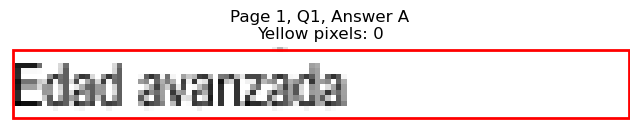

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=236.3, y1=114.7
Page 1, Q1, B: Yellow pixels: 5
Page 1, Q1, B: Total non-white pixels: 1046
Page 1, Q1, B: Yellow percentage: 0.5%


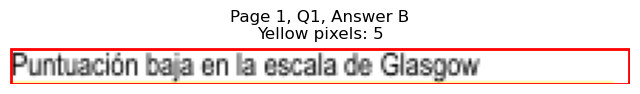

Page 1, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=189.1, y1=127.3
Page 1, Q1, C: Yellow pixels: 1629
Page 1, Q1, C: Total non-white pixels: 2408
Page 1, Q1, C: Yellow percentage: 67.6%


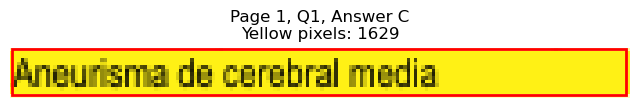

Page 1, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=438.9, y1=102.1
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 566
Page 1, Q1, D: Yellow percentage: 0.0%


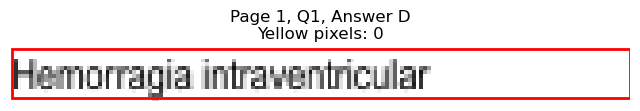

Page 1, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=383.7, y1=114.7
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 282
Page 1, Q1, E: Yellow percentage: 0.0%


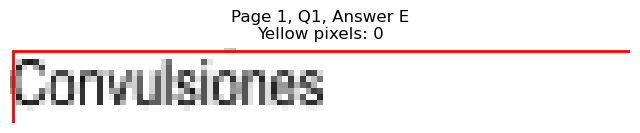


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=161.5, y1=165.2
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 467
Page 1, Q2, A: Yellow percentage: 0.0%


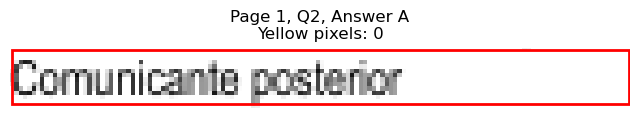

Page 1, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=132.5, y1=177.8
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 330
Page 1, Q2, B: Yellow percentage: 0.0%


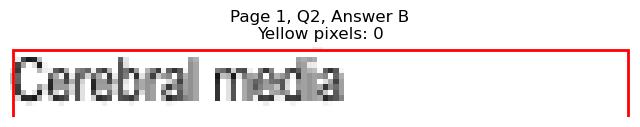

Page 1, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=92.3, y1=190.4
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 112
Page 1, Q2, C: Yellow percentage: 0.0%


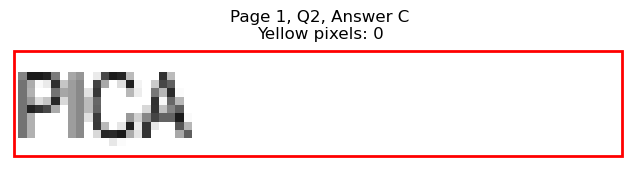

Page 1, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=384.8, y1=165.2
Page 1, Q2, D: Yellow pixels: 108
Page 1, Q2, D: Total non-white pixels: 411
Page 1, Q2, D: Yellow percentage: 26.3%


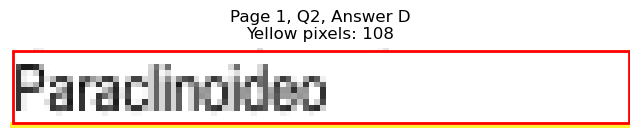

Page 1, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=415.9, y1=177.8
Page 1, Q2, E: Yellow pixels: 1464
Page 1, Q2, E: Total non-white pixels: 1807
Page 1, Q2, E: Yellow percentage: 81.0%


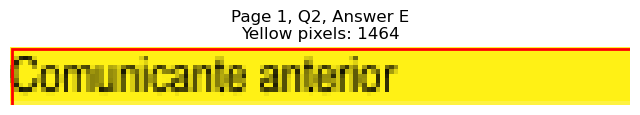


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=282.2, y1=228.3
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 1090
Page 1, Q3, A: Yellow percentage: 0.0%


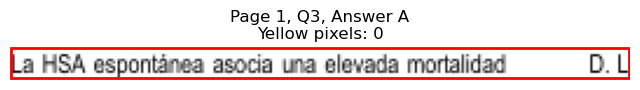

Page 1, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=282.4, y1=253.5
Page 1, Q3, B: Yellow pixels: 1973
Page 1, Q3, B: Total non-white pixels: 3071
Page 1, Q3, B: Yellow percentage: 64.2%


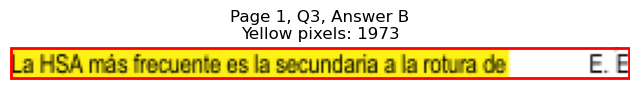

Page 1, Q3 - C: Detected box: x0=220.2, y0=266.1, x1=282.2, y1=278.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 376
Page 1, Q3, C: Yellow percentage: 0.0%


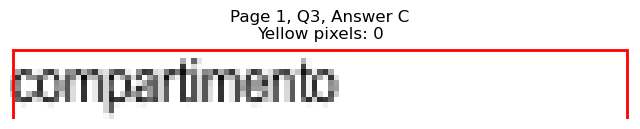

Page 1, Q3 - D: Detected box: x0=366.1, y0=215.7, x1=415.9, y1=228.3
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 476
Page 1, Q3, D: Yellow percentage: 0.0%


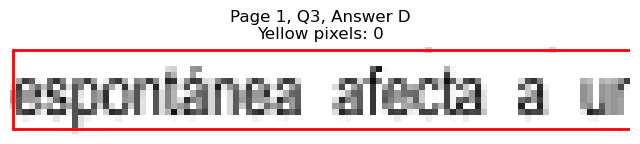

Page 1, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=508.8, y1=253.5
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 914
Page 1, Q3, E: Yellow percentage: 0.0%


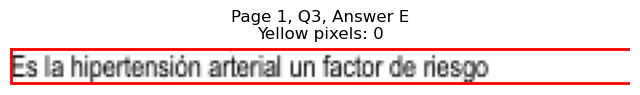


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=56.6, y0=316.6, x1=65.2, y1=329.3
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 53
Page 1, Q4, A: Yellow percentage: 0.0%


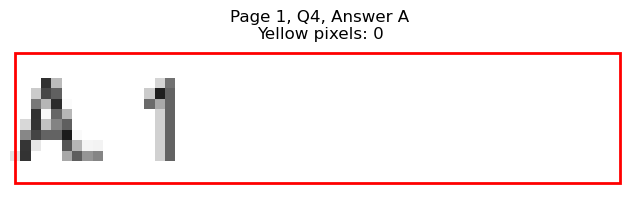

Page 1, Q4 - B: Detected box: x0=56.6, y0=329.2, x1=65.2, y1=341.9
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 73
Page 1, Q4, B: Yellow percentage: 0.0%


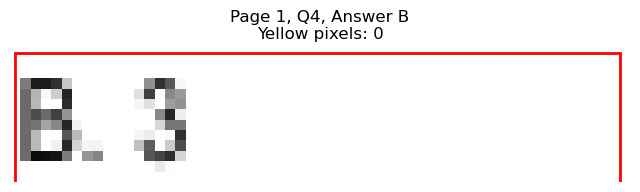

Page 1, Q4 - C: Detected box: x0=56.6, y0=341.9, x1=65.6, y1=354.6
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 66
Page 1, Q4, C: Yellow percentage: 0.0%


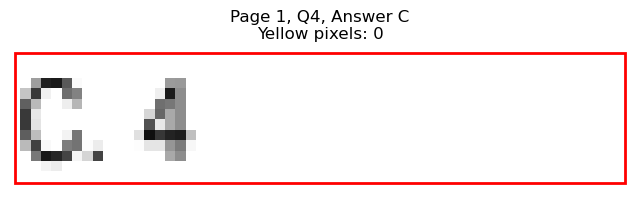

Page 1, Q4 - D: Detected box: x0=315.4, y0=316.6, x1=324.4, y1=329.3
Page 1, Q4, D: Yellow pixels: 60
Page 1, Q4, D: Total non-white pixels: 133
Page 1, Q4, D: Yellow percentage: 45.1%


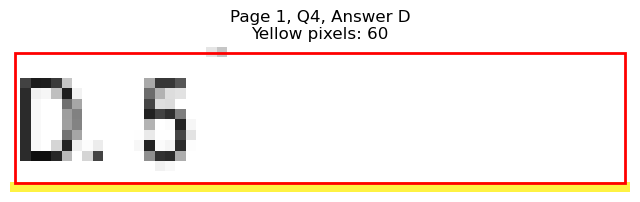

Page 1, Q4 - E: Detected box: x0=315.4, y0=329.2, x1=323.9, y1=341.9
Page 1, Q4, E: Yellow pixels: 718
Page 1, Q4, E: Total non-white pixels: 767
Page 1, Q4, E: Yellow percentage: 93.6%


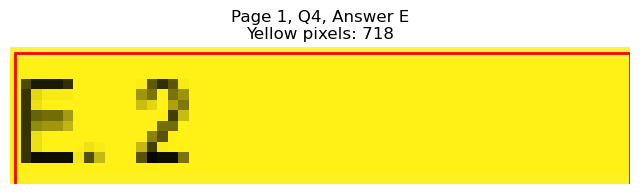


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=149.5, y1=392.4
Page 1, Q5, A: Yellow pixels: 1294
Page 1, Q5, A: Total non-white pixels: 1848
Page 1, Q5, A: Yellow percentage: 70.0%


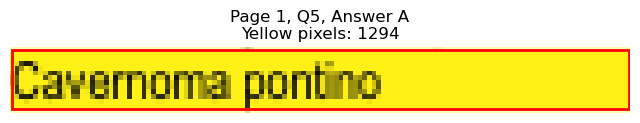

Page 1, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=182.2, y1=405.0
Page 1, Q5, B: Yellow pixels: 0
Page 1, Q5, B: Total non-white pixels: 731
Page 1, Q5, B: Yellow percentage: 0.0%


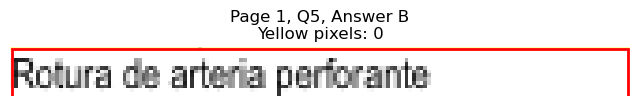

Page 1, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=142.0, y1=417.6
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 377
Page 1, Q5, C: Yellow percentage: 0.0%


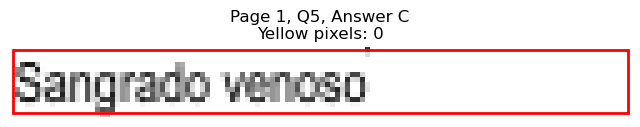

Page 1, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=501.1, y1=392.4
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 832
Page 1, Q5, D: Yellow percentage: 0.0%


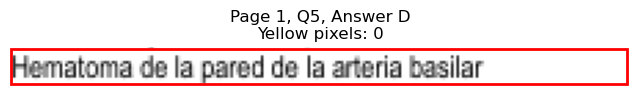

Page 1, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=431.3, y1=405.0
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 502
Page 1, Q5, E: Yellow percentage: 0.0%


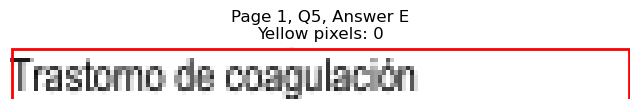


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=140.5, y1=493.4
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 393
Page 1, Q6, A: Yellow percentage: 0.0%


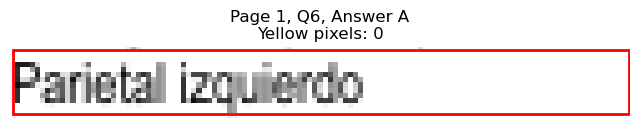

Page 1, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=148.0, y1=506.0
Page 1, Q6, B: Yellow pixels: 130
Page 1, Q6, B: Total non-white pixels: 620
Page 1, Q6, B: Yellow percentage: 21.0%


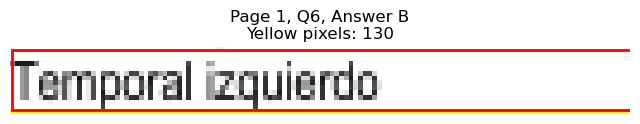

Page 1, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=144.5, y1=518.6
Page 1, Q6, C: Yellow pixels: 1358
Page 1, Q6, C: Total non-white pixels: 1778
Page 1, Q6, C: Yellow percentage: 76.4%


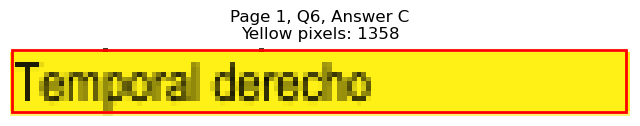

Page 1, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=403.7, y1=493.4
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 397
Page 1, Q6, D: Yellow percentage: 0.0%


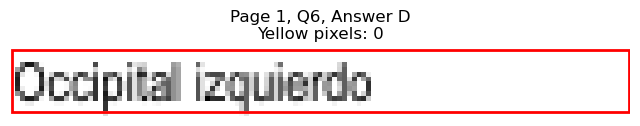

Page 1, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=395.2, y1=506.0
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 355
Page 1, Q6, E: Yellow percentage: 0.0%


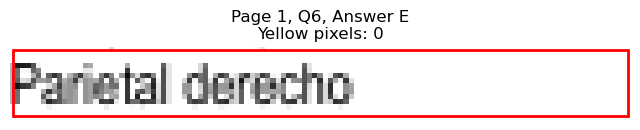


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=93.9, y1=569.2
Page 1, Q7, A: Yellow pixels: 924
Page 1, Q7, A: Total non-white pixels: 1064
Page 1, Q7, A: Yellow percentage: 86.8%


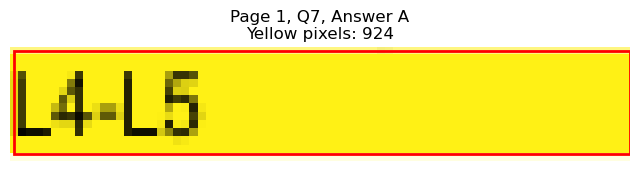

Page 1, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=94.9, y1=581.8
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 183
Page 1, Q7, B: Yellow percentage: 0.0%


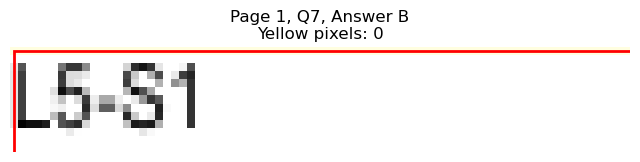

Page 1, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=94.3, y1=594.4
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 101
Page 1, Q7, C: Yellow percentage: 0.0%


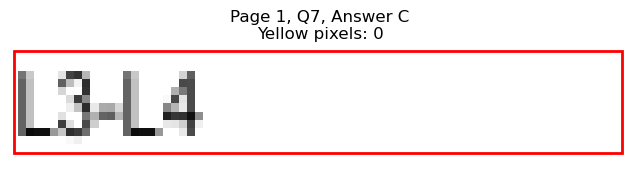

Page 1, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=353.1, y1=569.2
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 76
Page 1, Q7, D: Yellow percentage: 0.0%


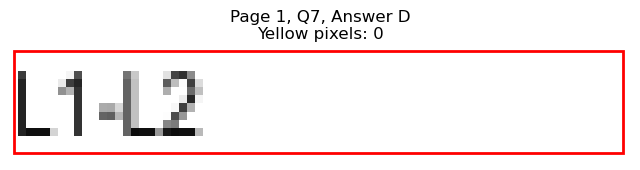

Page 1, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=354.7, y1=581.8
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 122
Page 1, Q7, E: Yellow percentage: 0.0%


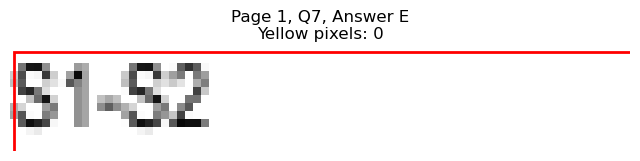


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=153.0, y1=644.9
Page 1, Q8, A: Yellow pixels: 1444
Page 1, Q8, A: Total non-white pixels: 1768
Page 1, Q8, A: Yellow percentage: 81.7%


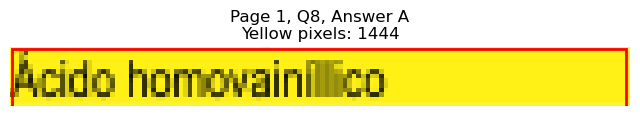

Page 1, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=171.6, y1=657.5
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 525
Page 1, Q8, B: Yellow percentage: 0.0%


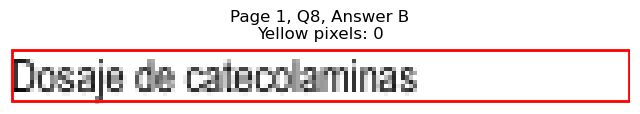

Page 1, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=139.0, y1=670.1
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 344
Page 1, Q8, C: Yellow percentage: 0.0%


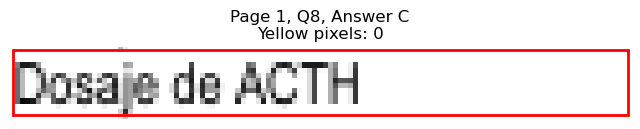

Page 1, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=401.8, y1=644.9
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 377
Page 1, Q8, D: Yellow percentage: 0.0%


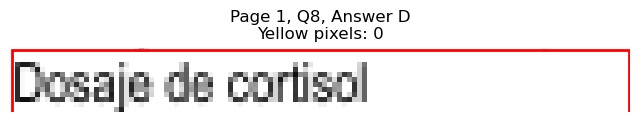

Page 1, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=442.5, y1=657.5
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 577
Page 1, Q8, E: Yellow percentage: 0.0%


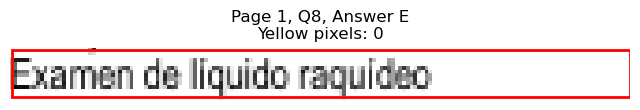


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=177.7, y1=733.2
Page 1, Q9, A: Yellow pixels: 1695
Page 1, Q9, A: Total non-white pixels: 2240
Page 1, Q9, A: Yellow percentage: 75.7%


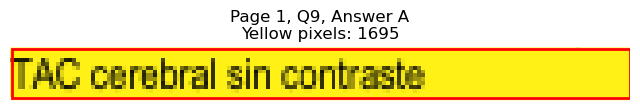

Page 1, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=173.7, y1=745.8
Page 1, Q9, B: Yellow pixels: 0
Page 1, Q9, B: Total non-white pixels: 650
Page 1, Q9, B: Yellow percentage: 0.0%


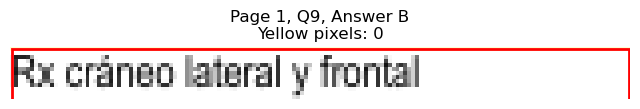

Page 1, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=183.6, y1=758.4
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 555
Page 1, Q9, C: Yellow percentage: 0.0%


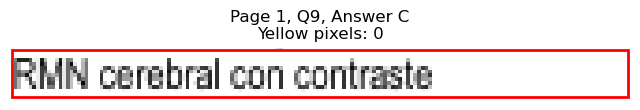

Page 1, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=417.9, y1=733.2
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 463
Page 1, Q9, D: Yellow percentage: 0.0%


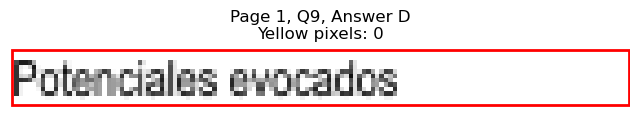

Page 1, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=404.3, y1=745.8
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 411
Page 1, Q9, E: Yellow percentage: 0.0%


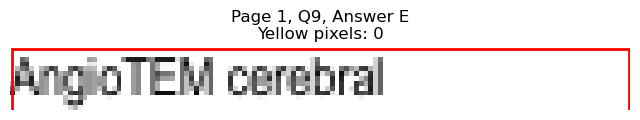


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=222.9, y1=114.7
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 800
Page 2, Q1, A: Yellow percentage: 0.0%


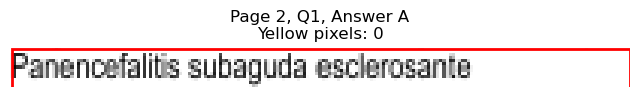

Page 2, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=166.1, y1=127.3
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 474
Page 2, Q1, B: Yellow percentage: 0.0%


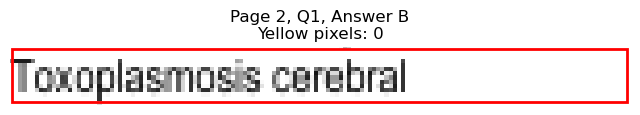

Page 2, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=158.5, y1=139.9
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 450
Page 2, Q1, C: Yellow percentage: 0.0%


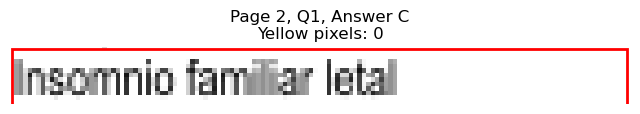

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=469.5, y1=114.7
Page 2, Q1, D: Yellow pixels: 1927
Page 2, Q1, D: Total non-white pixels: 2509
Page 2, Q1, D: Yellow percentage: 76.8%


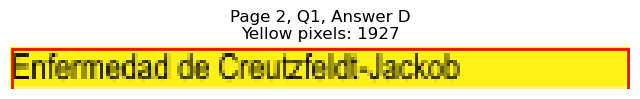

Page 2, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=404.3, y1=127.3
Page 2, Q1, E: Yellow pixels: 128
Page 2, Q1, E: Total non-white pixels: 543
Page 2, Q1, E: Yellow percentage: 23.6%


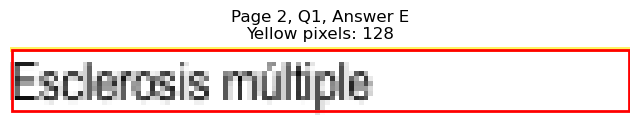


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=115.0, y1=177.8
Page 2, Q2, A: Yellow pixels: 1073
Page 2, Q2, A: Total non-white pixels: 1261
Page 2, Q2, A: Yellow percentage: 85.1%


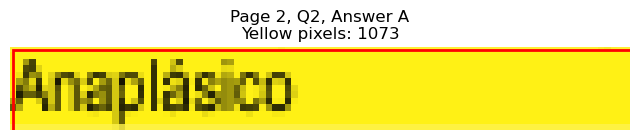

Page 2, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=92.4, y1=190.4
Page 2, Q2, B: Yellow pixels: 75
Page 2, Q2, B: Total non-white pixels: 210
Page 2, Q2, B: Yellow percentage: 35.7%


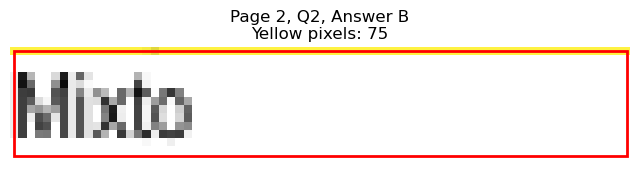

Page 2, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=101.4, y1=203.0
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 165
Page 2, Q2, C: Yellow percentage: 0.0%


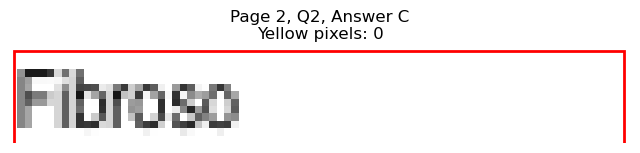

Page 2, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=383.7, y1=177.8
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 286
Page 2, Q2, D: Yellow percentage: 0.0%


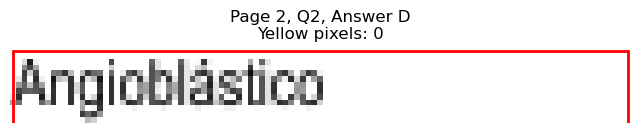

Page 2, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=387.3, y1=190.4
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 306
Page 2, Q2, E: Yellow percentage: 0.0%


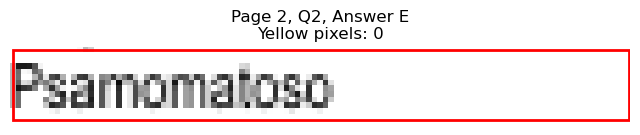


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=56.6, y0=253.5, x1=65.2, y1=266.1
Page 2, Q3, A: Yellow pixels: 727
Page 2, Q3, A: Total non-white pixels: 840
Page 2, Q3, A: Yellow percentage: 86.5%


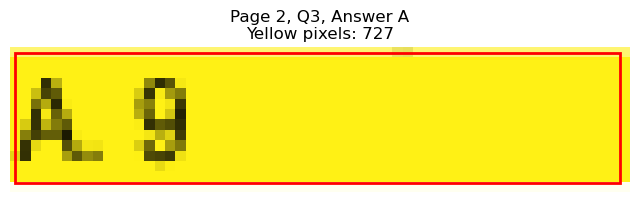

Page 2, Q3 - B: Detected box: x0=56.6, y0=266.1, x1=65.2, y1=278.7
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 138
Page 2, Q3, B: Yellow percentage: 0.0%


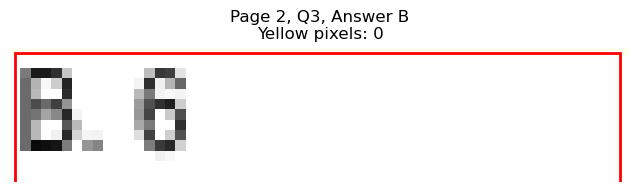

Page 2, Q3 - C: Detected box: x0=56.6, y0=278.8, x1=65.6, y1=291.5
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 67
Page 2, Q3, C: Yellow percentage: 0.0%


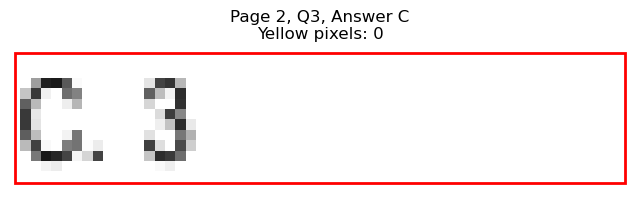

Page 2, Q3 - D: Detected box: x0=315.4, y0=253.5, x1=324.4, y1=266.1
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 71
Page 2, Q3, D: Yellow percentage: 0.0%


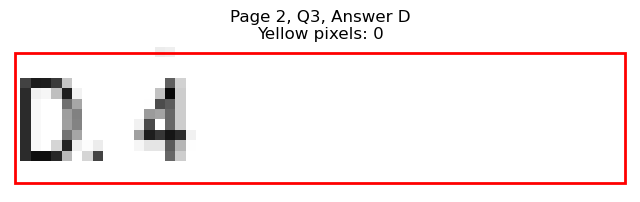

Page 2, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=339.7, y1=278.7
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 44
Page 2, Q3, E: Yellow percentage: 0.0%


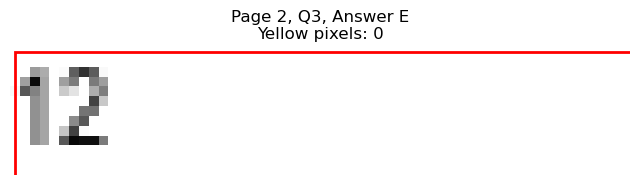


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=152.1, y1=341.9
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 429
Page 2, Q4, A: Yellow percentage: 0.0%


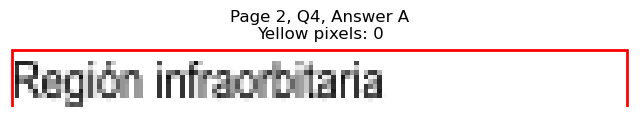

Page 2, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=135.0, y1=354.6
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 323
Page 2, Q4, B: Yellow percentage: 0.0%


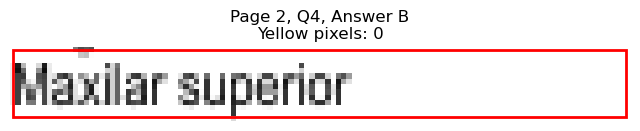

Page 2, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=125.4, y1=367.2
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 306
Page 2, Q4, C: Yellow percentage: 0.0%


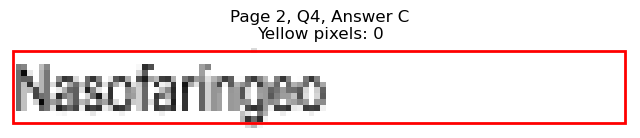

Page 2, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=393.8, y1=341.9
Page 2, Q4, D: Yellow pixels: 1271
Page 2, Q4, D: Total non-white pixels: 1521
Page 2, Q4, D: Yellow percentage: 83.6%


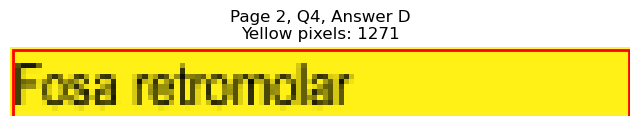

Page 2, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=407.8, y1=354.6
Page 2, Q4, E: Yellow pixels: 131
Page 2, Q4, E: Total non-white pixels: 520
Page 2, Q4, E: Yellow percentage: 25.2%


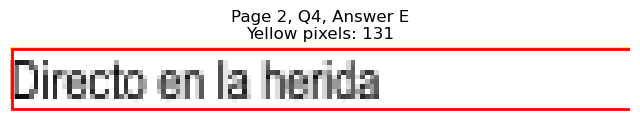


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=152.1, y1=430.3
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 389
Page 2, Q5, A: Yellow percentage: 0.0%


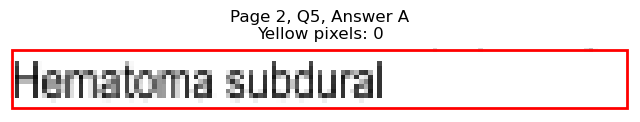

Page 2, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=193.2, y1=442.9
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 655
Page 2, Q5, B: Yellow percentage: 0.0%


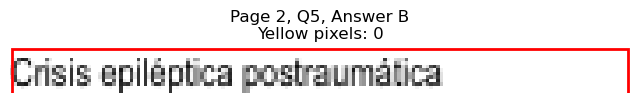

Page 2, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=111.9, y1=455.5
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 236
Page 2, Q5, C: Yellow percentage: 0.0%


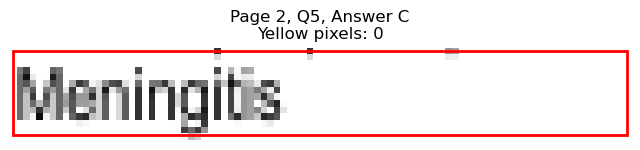

Page 2, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=446.9, y1=430.3
Page 2, Q5, D: Yellow pixels: 170
Page 2, Q5, D: Total non-white pixels: 786
Page 2, Q5, D: Yellow percentage: 21.6%


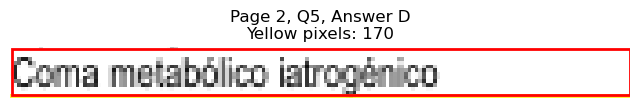

Page 2, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=408.3, y1=442.9
Page 2, Q5, E: Yellow pixels: 1413
Page 2, Q5, E: Total non-white pixels: 1716
Page 2, Q5, E: Yellow percentage: 82.3%


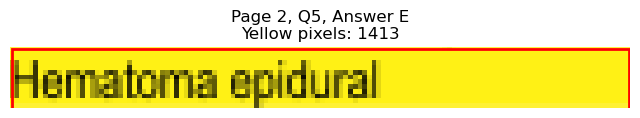


Page 2, Q5 - Selected Answer: E (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=161.5, y1=493.4
Page 2, Q6, A: Yellow pixels: 144
Page 2, Q6, A: Total non-white pixels: 611
Page 2, Q6, A: Yellow percentage: 23.6%


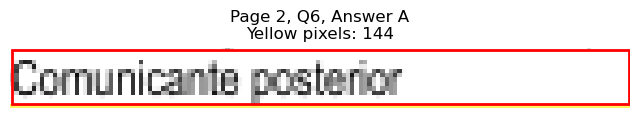

Page 2, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=143.1, y1=506.0
Page 2, Q6, B: Yellow pixels: 1348
Page 2, Q6, B: Total non-white pixels: 1639
Page 2, Q6, B: Yellow percentage: 82.2%


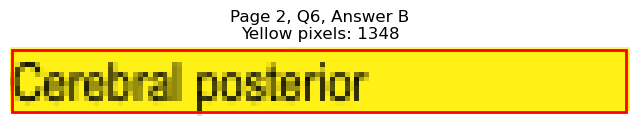

Page 2, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=157.6, y1=518.6
Page 2, Q6, C: Yellow pixels: 139
Page 2, Q6, C: Total non-white pixels: 573
Page 2, Q6, C: Yellow percentage: 24.3%


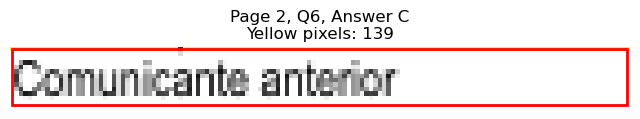

Page 2, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=391.7, y1=493.4
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 329
Page 2, Q6, D: Yellow percentage: 0.0%


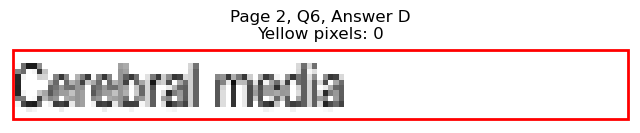

Page 2, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=409.3, y1=506.0
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 436
Page 2, Q6, E: Yellow percentage: 0.0%


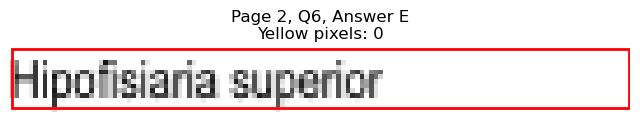


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=181.7, y1=556.4
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 553
Page 2, Q7, A: Yellow percentage: 0.0%


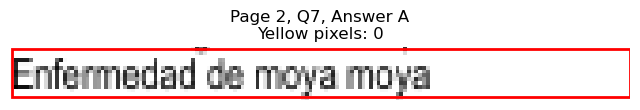

Page 2, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=155.5, y1=569.2
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 437
Page 2, Q7, B: Yellow percentage: 0.0%


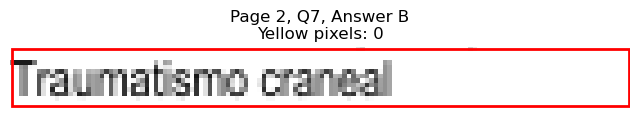

Page 2, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=152.5, y1=581.8
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 466
Page 2, Q7, C: Yellow percentage: 0.0%


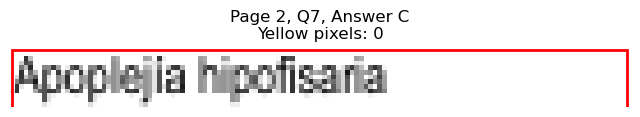

Page 2, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=401.3, y1=556.4
Page 2, Q7, D: Yellow pixels: 1362
Page 2, Q7, D: Total non-white pixels: 1750
Page 2, Q7, D: Yellow percentage: 77.8%


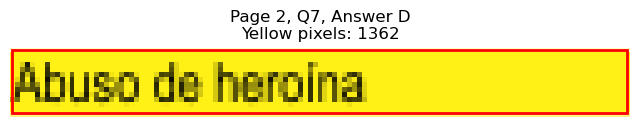

Page 2, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=410.3, y1=569.2
Page 2, Q7, E: Yellow pixels: 134
Page 2, Q7, E: Total non-white pixels: 572
Page 2, Q7, E: Yellow percentage: 23.4%


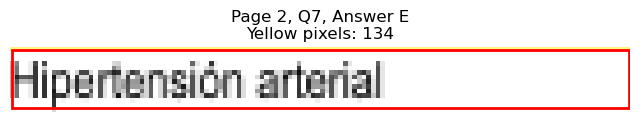


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=109.5, y1=632.3
Page 2, Q8, A: Yellow pixels: 92
Page 2, Q8, A: Total non-white pixels: 302
Page 2, Q8, A: Yellow percentage: 30.5%


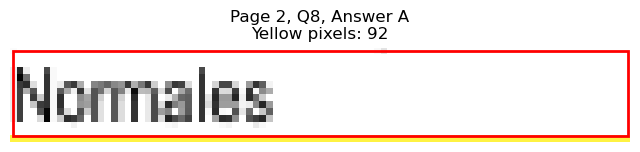

Page 2, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=170.1, y1=644.9
Page 2, Q8, B: Yellow pixels: 1610
Page 2, Q8, B: Total non-white pixels: 1989
Page 2, Q8, B: Yellow percentage: 80.9%


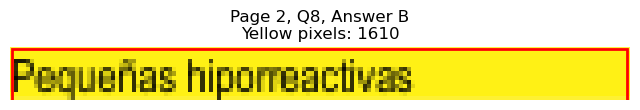

Page 2, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=114.4, y1=657.5
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 251
Page 2, Q8, C: Yellow percentage: 0.0%


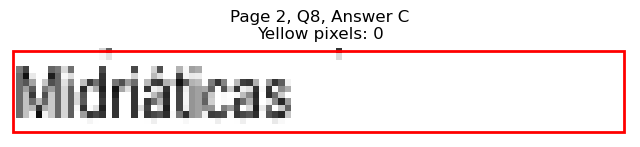

Page 2, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=423.8, y1=632.3
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 507
Page 2, Q8, D: Yellow percentage: 0.0%


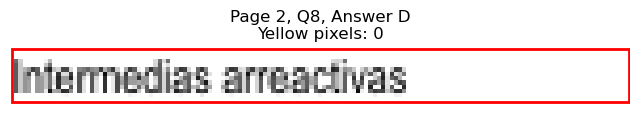

Page 2, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=428.8, y1=644.9
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 548
Page 2, Q8, E: Yellow percentage: 0.0%


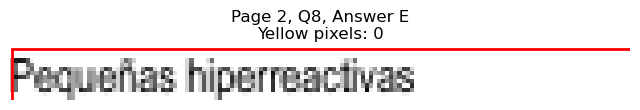


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=139.5, y0=682.7, x1=216.4, y1=695.3
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 605
Page 2, Q9, A: Yellow percentage: 0.0%


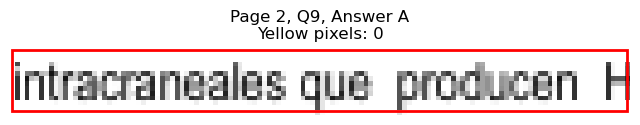

Page 2, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=282.2, y1=720.6
Page 2, Q9, B: Yellow pixels: 2014
Page 2, Q9, B: Total non-white pixels: 3067
Page 2, Q9, B: Yellow percentage: 65.7%


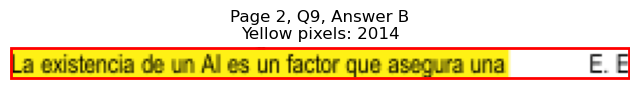

Page 2, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=282.4, y1=745.8
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 1245
Page 2, Q9, C: Yellow percentage: 0.0%


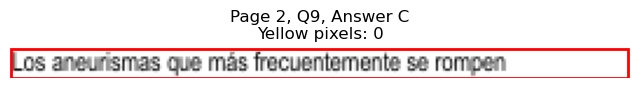

Page 2, Q9 - D: Detected box: x0=415.5, y0=682.7, x1=460.6, y1=695.3
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 439
Page 2, Q9, D: Yellow percentage: 0.0%


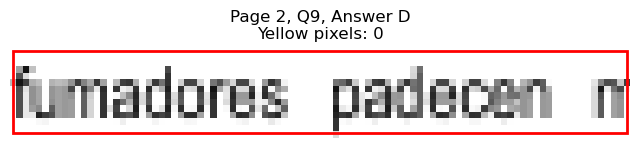

Page 2, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=540.9, y1=720.6
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 979
Page 2, Q9, E: Yellow percentage: 0.0%


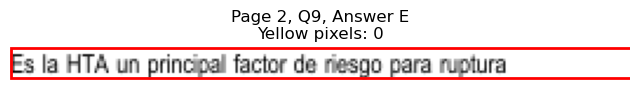


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=86.4, y1=114.7
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 63
Page 3, Q1, A: Yellow percentage: 0.0%


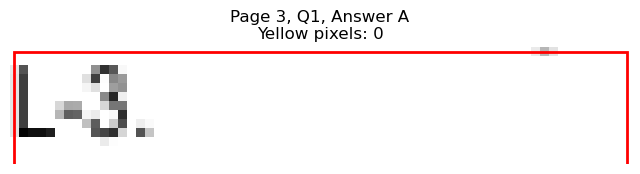

Page 3, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=86.4, y1=127.3
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 53
Page 3, Q1, B: Yellow percentage: 0.0%


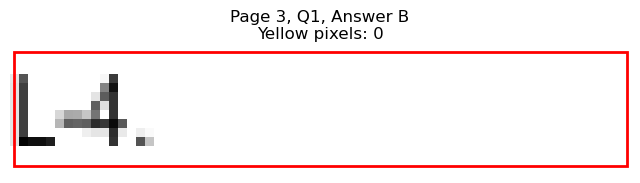

Page 3, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=87.9, y1=139.9
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 66
Page 3, Q1, C: Yellow percentage: 0.0%


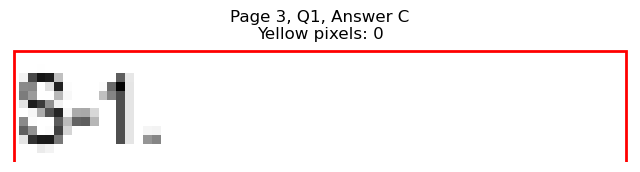

Page 3, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=346.6, y1=114.7
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 143
Page 3, Q1, D: Yellow percentage: 0.0%


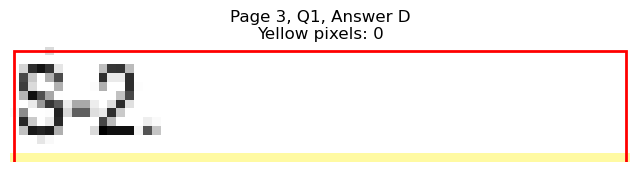

Page 3, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=345.2, y1=127.3
Page 3, Q1, E: Yellow pixels: 779
Page 3, Q1, E: Total non-white pixels: 966
Page 3, Q1, E: Yellow percentage: 80.6%


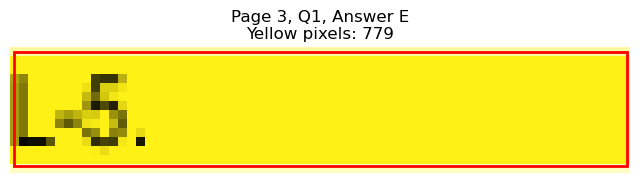


Page 3, Q1 - Selected Answer: E (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=105.9, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 164
Page 3, Q2, A: Yellow percentage: 0.0%


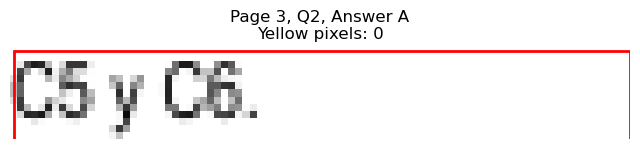

Page 3, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=105.9, y1=190.4
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 154
Page 3, Q2, B: Yellow percentage: 0.0%


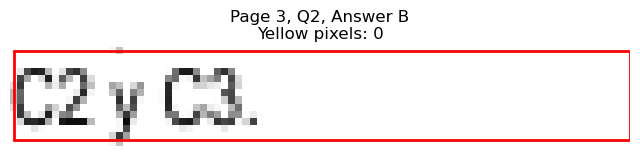

Page 3, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=106.3, y1=203.0
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 151
Page 3, Q2, C: Yellow percentage: 0.0%


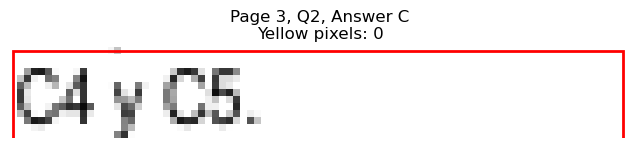

Page 3, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=365.1, y1=177.8
Page 3, Q2, D: Yellow pixels: 1
Page 3, Q2, D: Total non-white pixels: 245
Page 3, Q2, D: Yellow percentage: 0.4%


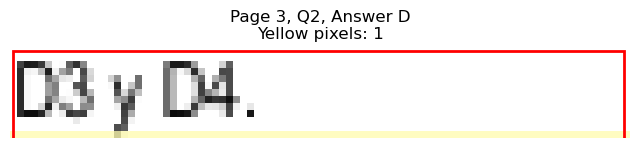

Page 3, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=364.6, y1=190.4
Page 3, Q2, E: Yellow pixels: 963
Page 3, Q2, E: Total non-white pixels: 1232
Page 3, Q2, E: Yellow percentage: 78.2%


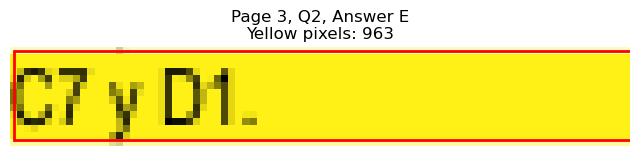


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=124.0, y1=240.9
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 274
Page 3, Q3, A: Yellow percentage: 0.0%


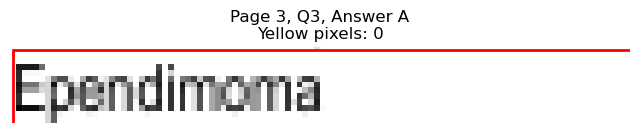

Page 3, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=120.0, y1=253.5
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 293
Page 3, Q3, B: Yellow percentage: 0.0%


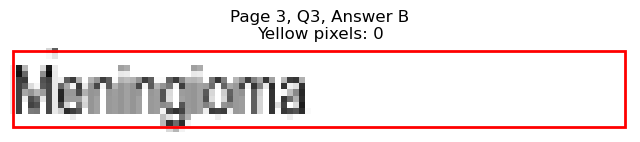

Page 3, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=147.1, y1=266.1
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 452
Page 3, Q3, C: Yellow percentage: 0.0%


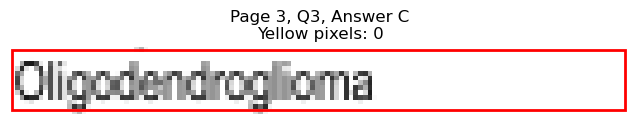

Page 3, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=404.8, y1=240.9
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 539
Page 3, Q3, D: Yellow percentage: 0.0%


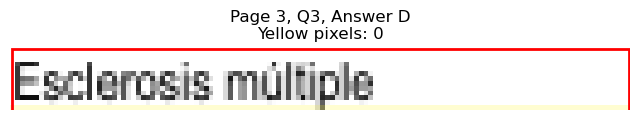

Page 3, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=426.9, y1=253.5
Page 3, Q3, E: Yellow pixels: 1533
Page 3, Q3, E: Total non-white pixels: 2100
Page 3, Q3, E: Yellow percentage: 73.0%


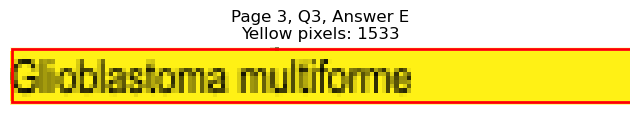


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=132.0, y1=329.3
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 296
Page 3, Q4, A: Yellow percentage: 0.0%


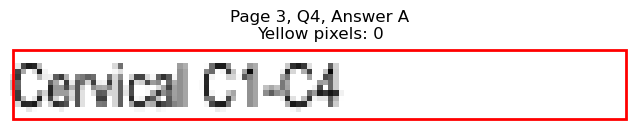

Page 3, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=132.0, y1=341.9
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 272
Page 3, Q4, B: Yellow percentage: 0.0%


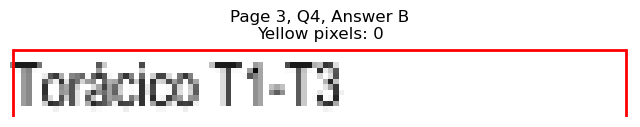

Page 3, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=132.5, y1=354.6
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 292
Page 3, Q4, C: Yellow percentage: 0.0%


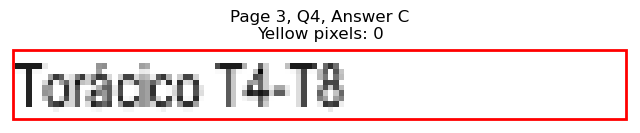

Page 3, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=396.2, y1=329.3
Page 3, Q4, D: Yellow pixels: 120
Page 3, Q4, D: Total non-white pixels: 423
Page 3, Q4, D: Yellow percentage: 28.4%


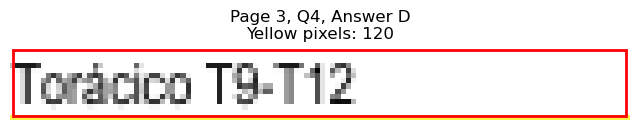

Page 3, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=390.8, y1=341.9
Page 3, Q4, E: Yellow pixels: 1251
Page 3, Q4, E: Total non-white pixels: 1482
Page 3, Q4, E: Yellow percentage: 84.4%


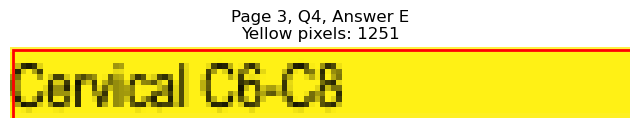


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=118.5, y1=392.4
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 265
Page 3, Q5, A: Yellow percentage: 0.0%


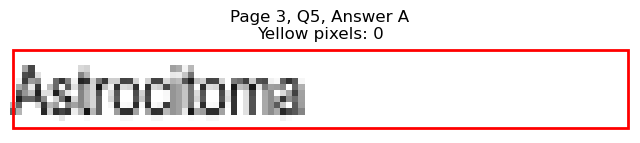

Page 3, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=146.5, y1=405.0
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 505
Page 3, Q5, B: Yellow percentage: 0.0%


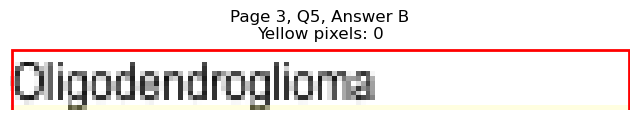

Page 3, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=121.9, y1=417.6
Page 3, Q5, C: Yellow pixels: 1153
Page 3, Q5, C: Total non-white pixels: 1456
Page 3, Q5, C: Yellow percentage: 79.2%


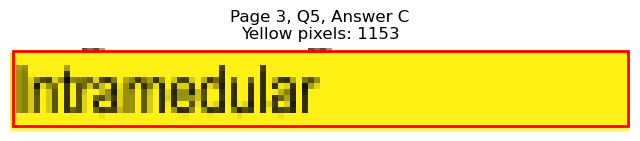

Page 3, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=383.2, y1=392.4
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 273
Page 3, Q5, D: Yellow percentage: 0.0%


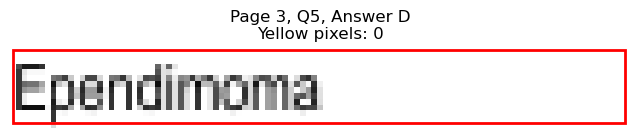

Page 3, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=378.7, y1=405.0
Page 3, Q5, E: Yellow pixels: 0
Page 3, Q5, E: Total non-white pixels: 269
Page 3, Q5, E: Yellow percentage: 0.0%


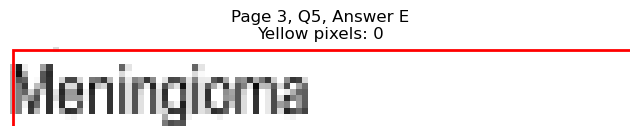


Page 3, Q5 - Selected Answer: C (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=146.1, y1=468.1
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 374
Page 3, Q6, A: Yellow percentage: 0.0%


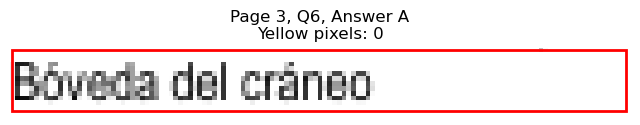

Page 3, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=134.5, y1=480.7
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 335
Page 3, Q6, B: Yellow percentage: 0.0%


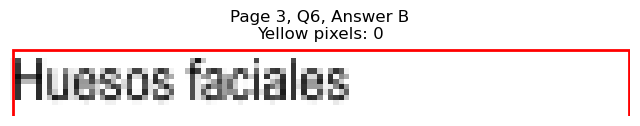

Page 3, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=135.1, y1=493.4
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 317
Page 3, Q6, C: Yellow percentage: 0.0%


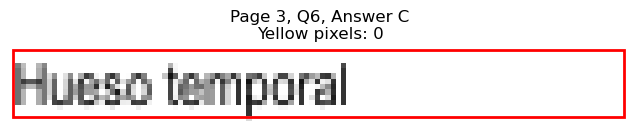

Page 3, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=388.3, y1=468.1
Page 3, Q6, D: Yellow pixels: 112
Page 3, Q6, D: Total non-white pixels: 427
Page 3, Q6, D: Yellow percentage: 26.2%


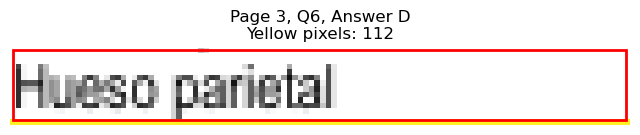

Page 3, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=394.7, y1=480.7
Page 3, Q6, E: Yellow pixels: 1254
Page 3, Q6, E: Total non-white pixels: 1534
Page 3, Q6, E: Yellow percentage: 81.7%


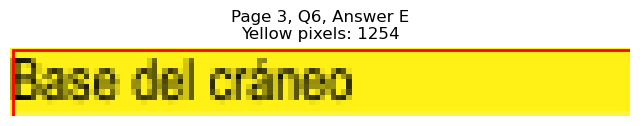


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=80.9, y1=531.2
Page 3, Q7, A: Yellow pixels: 63
Page 3, Q7, A: Total non-white pixels: 102
Page 3, Q7, A: Yellow percentage: 61.8%


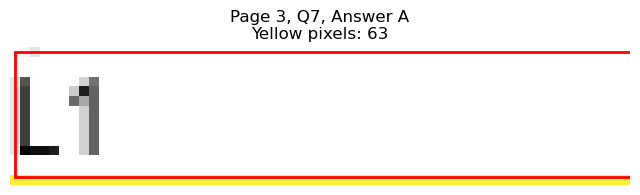

Page 3, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=80.9, y1=543.8
Page 3, Q7, B: Yellow pixels: 791
Page 3, Q7, B: Total non-white pixels: 819
Page 3, Q7, B: Yellow percentage: 96.6%


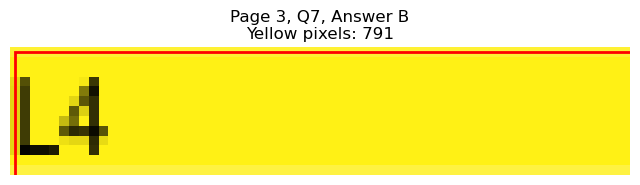

Page 3, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=81.4, y1=556.4
Page 3, Q7, C: Yellow pixels: 64
Page 3, Q7, C: Total non-white pixels: 116
Page 3, Q7, C: Yellow percentage: 55.2%


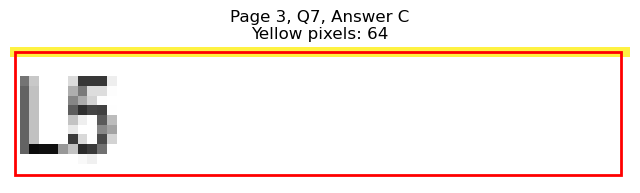

Page 3, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=341.1, y1=531.2
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 48
Page 3, Q7, D: Yellow percentage: 0.0%


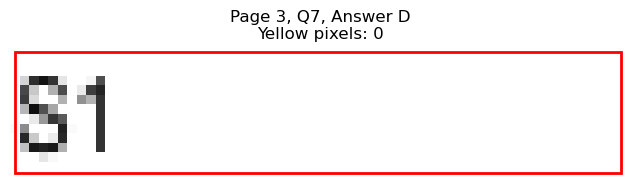

Page 3, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=340.6, y1=543.8
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 61
Page 3, Q7, E: Yellow percentage: 0.0%


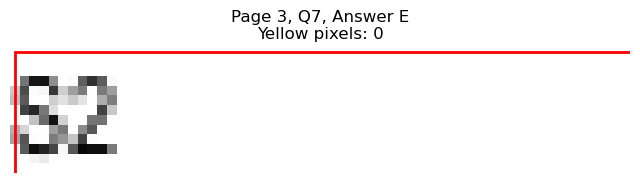


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=119.9, y1=607.0
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 286
Page 3, Q8, A: Yellow percentage: 0.0%


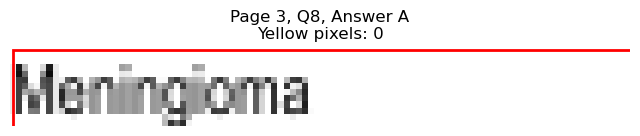

Page 3, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=153.5, y1=619.6
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 441
Page 3, Q8, B: Yellow percentage: 0.0%


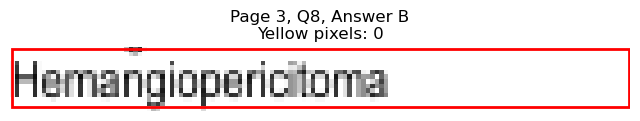

Page 3, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=103.3, y1=632.3
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 173
Page 3, Q8, C: Yellow percentage: 0.0%


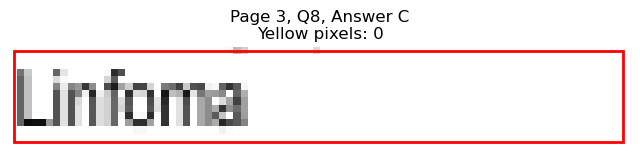

Page 3, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=390.8, y1=607.0
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 434
Page 3, Q8, D: Yellow percentage: 0.0%


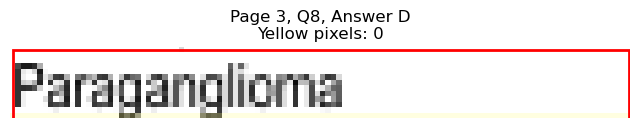

Page 3, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=434.3, y1=619.6
Page 3, Q8, E: Yellow pixels: 1628
Page 3, Q8, E: Total non-white pixels: 2212
Page 3, Q8, E: Yellow percentage: 73.6%


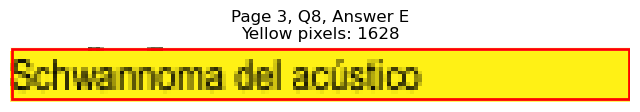


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=272.4, y1=695.3
Page 3, Q9, A: Yellow pixels: 79
Page 3, Q9, A: Total non-white pixels: 1143
Page 3, Q9, A: Yellow percentage: 6.9%


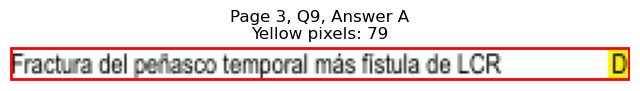

Page 3, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=282.2, y1=708.0
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 1142
Page 3, Q9, B: Yellow percentage: 0.0%


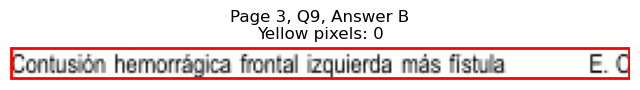

Page 3, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=282.3, y1=733.2
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 1059
Page 3, Q9, C: Yellow percentage: 0.0%


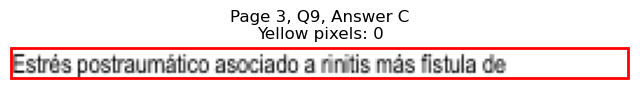

Page 3, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=520.2, y1=695.3
Page 3, Q9, D: Yellow pixels: 1846
Page 3, Q9, D: Total non-white pixels: 2996
Page 3, Q9, D: Yellow percentage: 61.6%


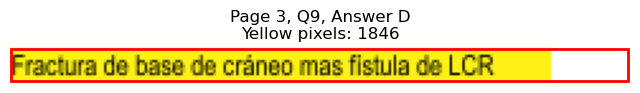

Page 3, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=541.0, y1=708.0
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 1313
Page 3, Q9, E: Yellow percentage: 0.0%


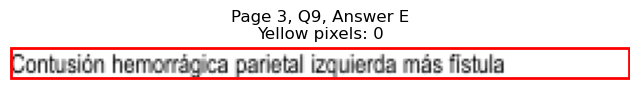


Page 3, Q9 - Selected Answer: D (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=78.4, y1=114.7
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 93
Page 4, Q1, A: Yellow percentage: 0.0%


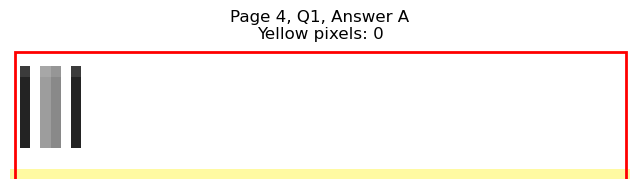

Page 4, Q1 - B: Detected box: x0=56.6, y0=114.6, x1=65.2, y1=127.3
Page 4, Q1, B: Yellow pixels: 659
Page 4, Q1, B: Total non-white pixels: 840
Page 4, Q1, B: Yellow percentage: 78.5%


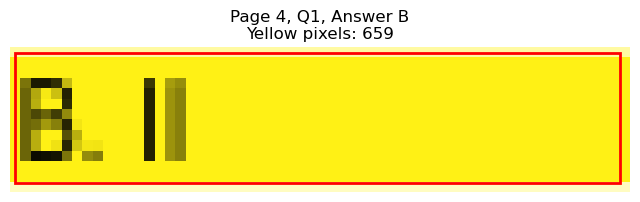

Page 4, Q1 - C: Detected box: x0=56.6, y0=127.2, x1=65.6, y1=139.9
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 113
Page 4, Q1, C: Yellow percentage: 0.0%


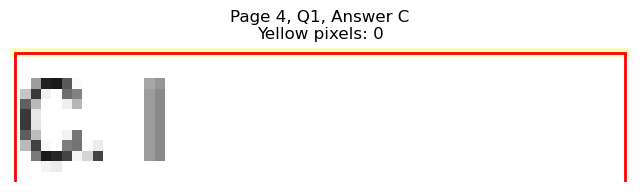

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=338.6, y1=114.7
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 42
Page 4, Q1, D: Yellow percentage: 0.0%


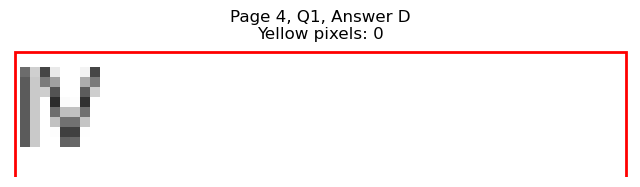

Page 4, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=335.6, y1=127.3
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 26
Page 4, Q1, E: Yellow percentage: 0.0%


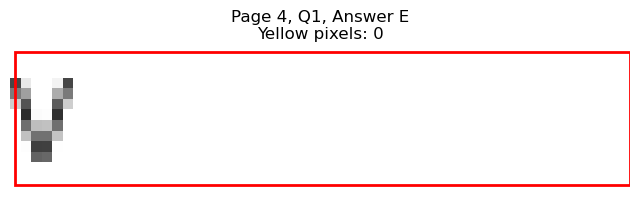


Page 4, Q1 - Selected Answer: B (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=152.5, y1=203.0
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 468
Page 4, Q2, A: Yellow percentage: 0.0%


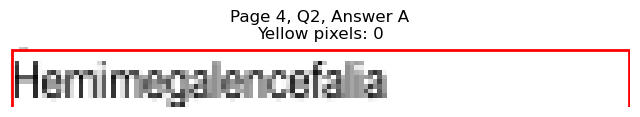

Page 4, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=112.9, y1=215.6
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 241
Page 4, Q2, B: Yellow percentage: 0.0%


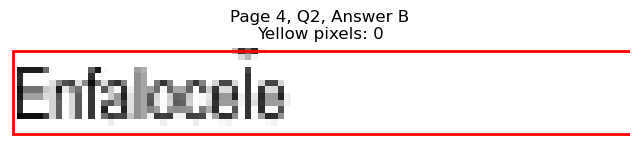

Page 4, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=118.9, y1=228.3
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 240
Page 4, Q2, C: Yellow percentage: 0.0%


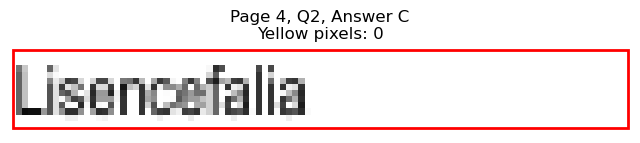

Page 4, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=393.3, y1=203.0
Page 4, Q2, D: Yellow pixels: 1259
Page 4, Q2, D: Total non-white pixels: 1521
Page 4, Q2, D: Yellow percentage: 82.8%


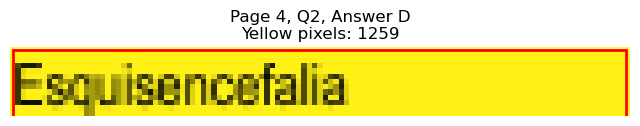

Page 4, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=369.7, y1=215.6
Page 4, Q2, E: Yellow pixels: 91
Page 4, Q2, E: Total non-white pixels: 343
Page 4, Q2, E: Yellow percentage: 26.5%


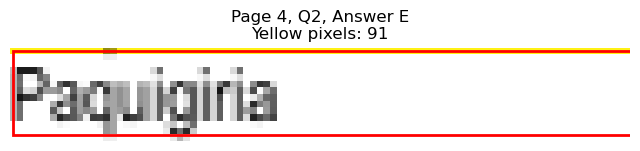


Page 4, Q2 - Selected Answer: D (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=150.1, y1=291.5
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 412
Page 4, Q3, A: Yellow percentage: 0.0%


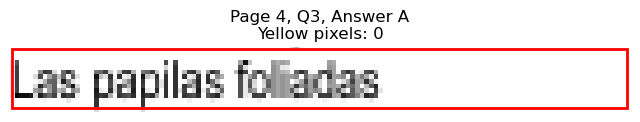

Page 4, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=166.6, y1=304.1
Page 4, Q3, B: Yellow pixels: 149
Page 4, Q3, B: Total non-white pixels: 626
Page 4, Q3, B: Yellow percentage: 23.8%


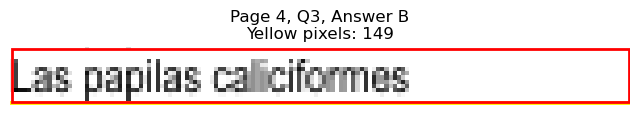

Page 4, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=166.7, y1=316.7
Page 4, Q3, C: Yellow pixels: 1530
Page 4, Q3, C: Total non-white pixels: 1937
Page 4, Q3, C: Yellow percentage: 79.0%


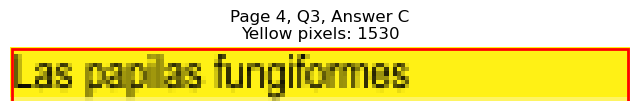

Page 4, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=418.9, y1=291.5
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 460
Page 4, Q3, D: Yellow percentage: 0.0%


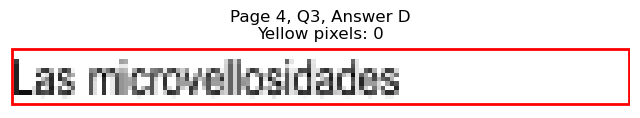

Page 4, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=419.8, y1=304.1
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 461
Page 4, Q3, E: Yellow percentage: 0.0%


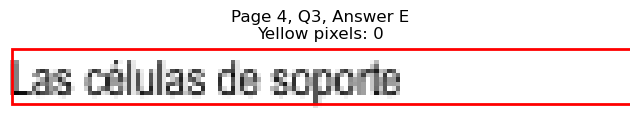


Page 4, Q3 - Selected Answer: C (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=119.9, y1=379.8
Page 4, Q4, A: Yellow pixels: 1094
Page 4, Q4, A: Total non-white pixels: 1326
Page 4, Q4, A: Yellow percentage: 82.5%


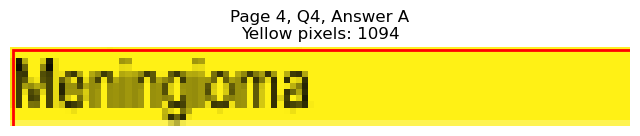

Page 4, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=125.4, y1=392.4
Page 4, Q4, B: Yellow pixels: 107
Page 4, Q4, B: Total non-white pixels: 395
Page 4, Q4, B: Yellow percentage: 27.1%


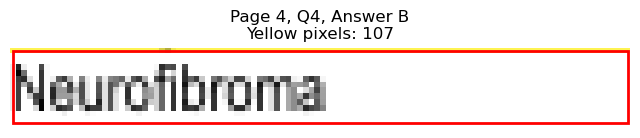

Page 4, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=132.0, y1=405.0
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 342
Page 4, Q4, C: Yellow percentage: 0.0%


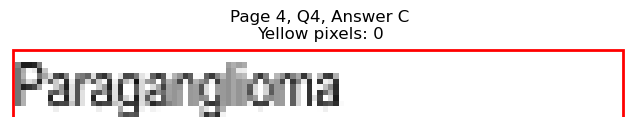

Page 4, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=430.4, y1=379.8
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 550
Page 4, Q4, D: Yellow percentage: 0.0%


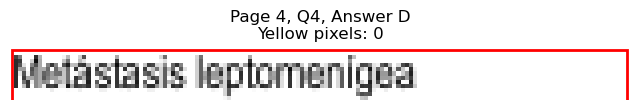

Page 4, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=412.3, y1=392.4
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 474
Page 4, Q4, E: Yellow percentage: 0.0%


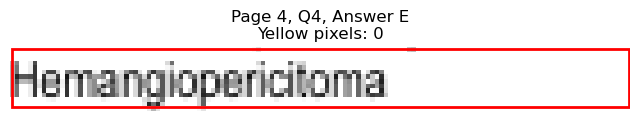


Page 4, Q4 - Selected Answer: A (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=159.6, y1=442.9
Page 4, Q5, A: Yellow pixels: 1467
Page 4, Q5, A: Total non-white pixels: 1846
Page 4, Q5, A: Yellow percentage: 79.5%


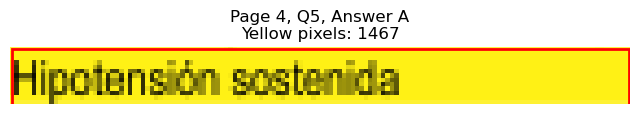

Page 4, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=215.3, y1=455.5
Page 4, Q5, B: Yellow pixels: 197
Page 4, Q5, B: Total non-white pixels: 946
Page 4, Q5, B: Yellow percentage: 20.8%


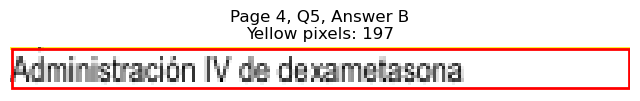

Page 4, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=135.5, y1=468.1
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 353
Page 4, Q5, C: Yellow percentage: 0.0%


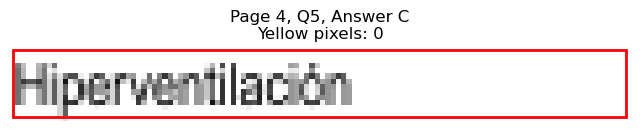

Page 4, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=433.4, y1=442.9
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 554
Page 4, Q5, D: Yellow percentage: 0.0%


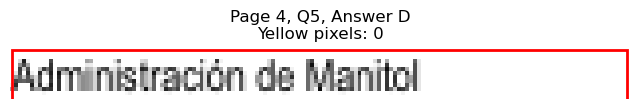

Page 4, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=471.0, y1=455.5
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 708
Page 4, Q5, E: Yellow percentage: 0.0%


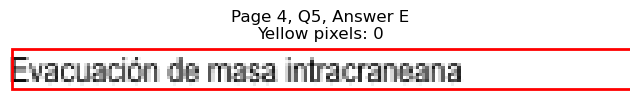


Page 4, Q5 - Selected Answer: A (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=127.0, y1=518.6
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 244
Page 4, Q6, A: Yellow percentage: 0.0%


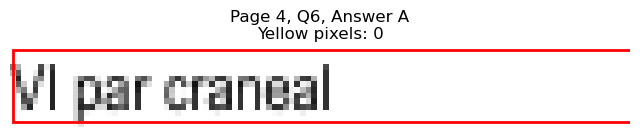

Page 4, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=129.5, y1=531.2
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 290
Page 4, Q6, B: Yellow percentage: 0.0%


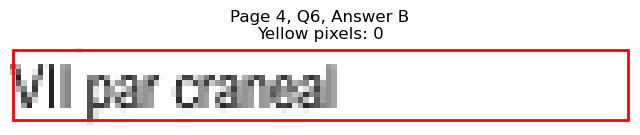

Page 4, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=142.9, y1=543.8
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 395
Page 4, Q6, C: Yellow percentage: 0.0%


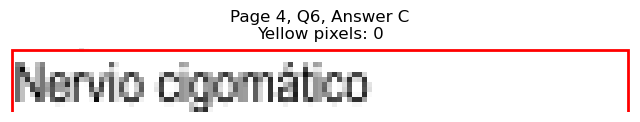

Page 4, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=380.2, y1=518.6
Page 4, Q6, D: Yellow pixels: 104
Page 4, Q6, D: Total non-white pixels: 354
Page 4, Q6, D: Yellow percentage: 29.4%


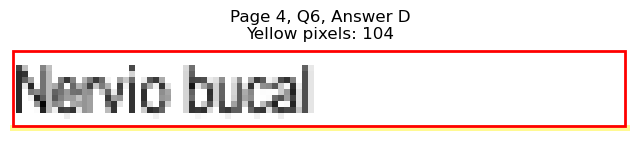

Page 4, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=383.2, y1=531.2
Page 4, Q6, E: Yellow pixels: 1204
Page 4, Q6, E: Total non-white pixels: 1498
Page 4, Q6, E: Yellow percentage: 80.4%


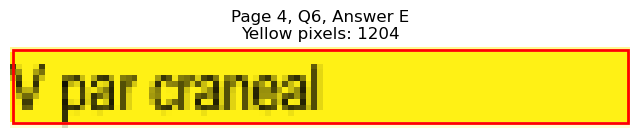


Page 4, Q6 - Selected Answer: E (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=107.4, y1=581.8
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 292
Page 4, Q7, A: Yellow percentage: 0.0%


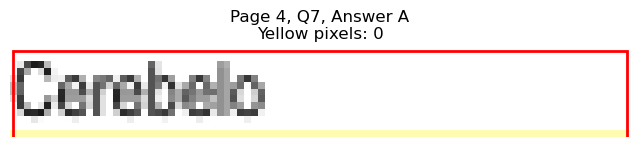

Page 4, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=140.1, y1=594.4
Page 4, Q7, B: Yellow pixels: 1196
Page 4, Q7, B: Total non-white pixels: 1722
Page 4, Q7, B: Yellow percentage: 69.5%


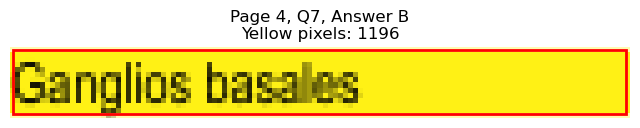

Page 4, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=132.5, y1=607.0
Page 4, Q7, C: Yellow pixels: 1
Page 4, Q7, C: Total non-white pixels: 431
Page 4, Q7, C: Yellow percentage: 0.2%


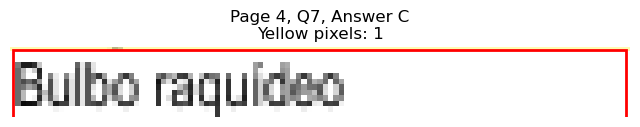

Page 4, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=386.2, y1=581.8
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 310
Page 4, Q7, D: Yellow percentage: 0.0%


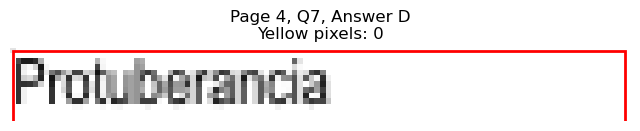

Page 4, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=384.3, y1=594.4
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 283
Page 4, Q7, E: Yellow percentage: 0.0%


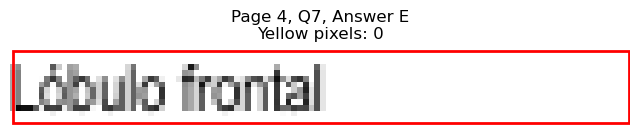


Page 4, Q7 - Selected Answer: B (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=186.6, y1=644.9
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 605
Page 4, Q8, A: Yellow percentage: 0.0%


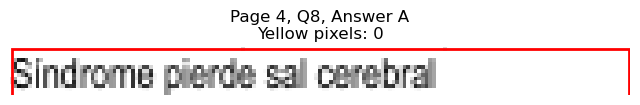

Page 4, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=140.5, y1=657.5
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 392
Page 4, Q8, B: Yellow percentage: 0.0%


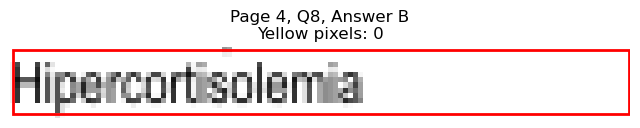

Page 4, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=154.6, y1=670.1
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 452
Page 4, Q8, C: Yellow percentage: 0.0%


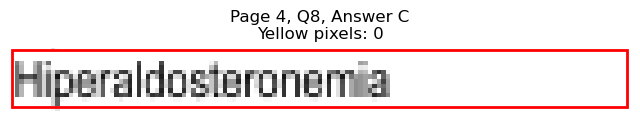

Page 4, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=405.8, y1=644.9
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 568
Page 4, Q8, D: Yellow percentage: 0.0%


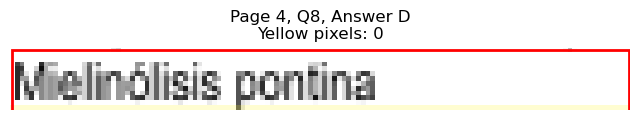

Page 4, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=357.2, y1=657.5
Page 4, Q8, E: Yellow pixels: 927
Page 4, Q8, E: Total non-white pixels: 1134
Page 4, Q8, E: Yellow percentage: 81.7%


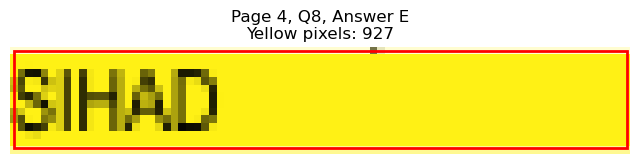


Page 4, Q8 - Selected Answer: E (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=128.5, y1=708.0
Page 4, Q9, A: Yellow pixels: 111
Page 4, Q9, A: Total non-white pixels: 517
Page 4, Q9, A: Yellow percentage: 21.5%


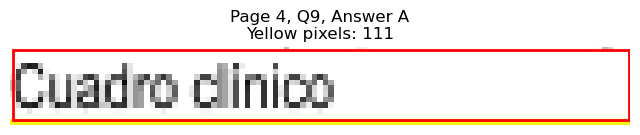

Page 4, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=208.2, y1=720.6
Page 4, Q9, B: Yellow pixels: 1943
Page 4, Q9, B: Total non-white pixels: 2674
Page 4, Q9, B: Yellow percentage: 72.7%


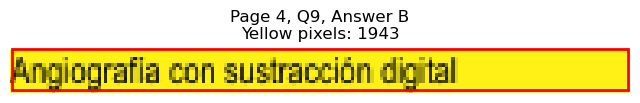

Page 4, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=138.5, y1=733.2
Page 4, Q9, C: Yellow pixels: 118
Page 4, Q9, C: Total non-white pixels: 474
Page 4, Q9, C: Yellow percentage: 24.9%


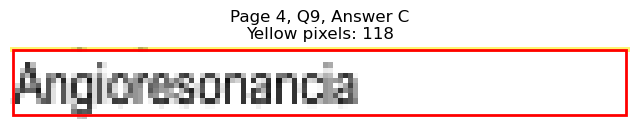

Page 4, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=367.6, y1=708.0
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 170
Page 4, Q9, D: Yellow percentage: 0.0%


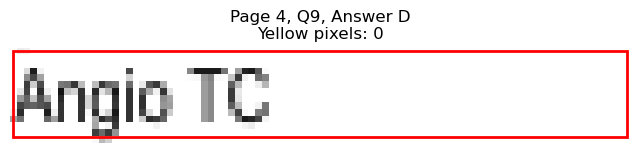

Page 4, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=413.3, y1=720.6
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 445
Page 4, Q9, E: Yellow percentage: 0.0%


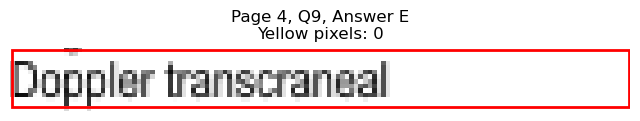


Page 4, Q9 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 8 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=282.2, y1=114.7
Page 5, Q1, A: Yellow pixels: 195
Page 5, Q1, A: Total non-white pixels: 1288
Page 5, Q1, A: Yellow percentage: 15.1%


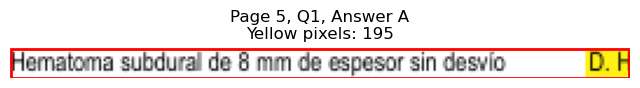

Page 5, Q1 - B: Detected box: x0=153.8, y0=127.2, x1=212.0, y1=139.9
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 476
Page 5, Q1, B: Yellow percentage: 0.0%


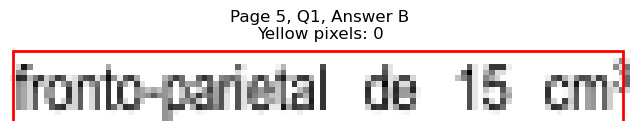

Page 5, Q1 - C: Detected box: x0=157.8, y0=152.5, x1=216.0, y1=165.2
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 467
Page 5, Q1, C: Yellow percentage: 0.0%


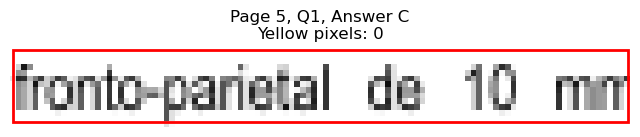

Page 5, Q1 - D: Detected box: x0=417.8, y0=102.0, x1=473.0, y1=114.7
Page 5, Q1, D: Yellow pixels: 1002
Page 5, Q1, D: Total non-white pixels: 1378
Page 5, Q1, D: Yellow percentage: 72.7%


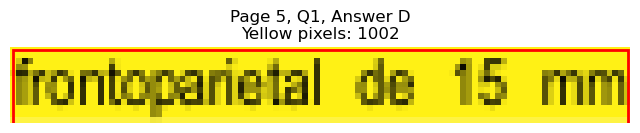

Page 5, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=373.7, y1=152.6
Page 5, Q1, E: Yellow pixels: 91
Page 5, Q1, E: Total non-white pixels: 560
Page 5, Q1, E: Yellow percentage: 16.2%


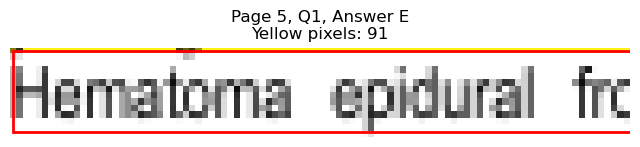


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=139.5, y1=228.3
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 356
Page 5, Q2, A: Yellow percentage: 0.0%


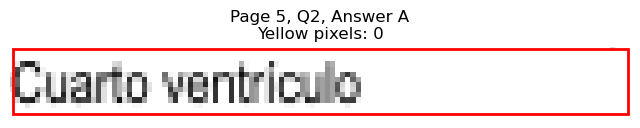

Page 5, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=138.5, y1=240.9
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 332
Page 5, Q2, B: Yellow percentage: 0.0%


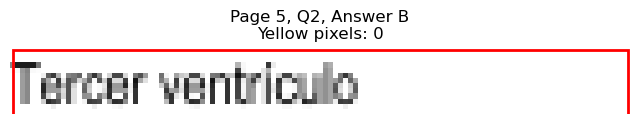

Page 5, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=148.6, y1=253.5
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 398
Page 5, Q2, C: Yellow percentage: 0.0%


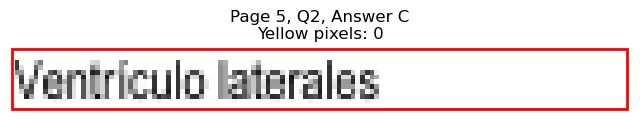

Page 5, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=389.7, y1=228.3
Page 5, Q2, D: Yellow pixels: 113
Page 5, Q2, D: Total non-white pixels: 410
Page 5, Q2, D: Yellow percentage: 27.6%


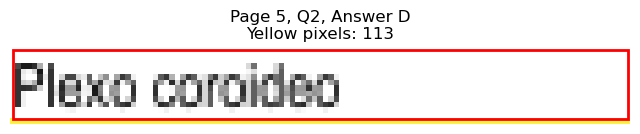

Page 5, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=391.3, y1=240.9
Page 5, Q2, E: Yellow pixels: 1257
Page 5, Q2, E: Total non-white pixels: 1495
Page 5, Q2, E: Yellow percentage: 84.1%


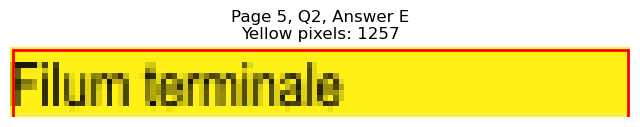


Page 5, Q2 - Selected Answer: E (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=179.7, y1=291.5
Page 5, Q3, A: Yellow pixels: 162
Page 5, Q3, A: Total non-white pixels: 732
Page 5, Q3, A: Yellow percentage: 22.1%


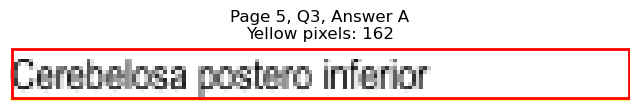

Page 5, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=137.5, y1=304.1
Page 5, Q3, B: Yellow pixels: 1295
Page 5, Q3, B: Total non-white pixels: 1680
Page 5, Q3, B: Yellow percentage: 77.1%


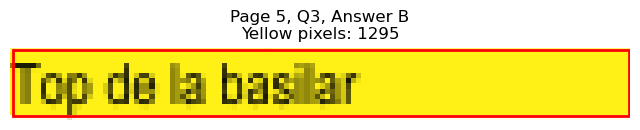

Page 5, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=132.5, y1=316.7
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 448
Page 5, Q3, C: Yellow percentage: 0.0%


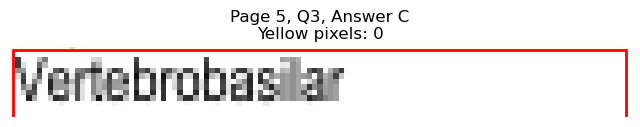

Page 5, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=434.3, y1=291.5
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 545
Page 5, Q3, D: Yellow percentage: 0.0%


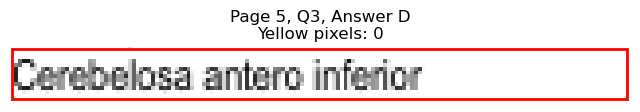

Page 5, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=438.9, y1=304.1
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 532
Page 5, Q3, E: Yellow percentage: 0.0%


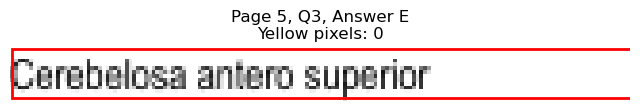


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=121.0, y1=367.2
Page 5, Q4, A: Yellow pixels: 103
Page 5, Q4, A: Total non-white pixels: 381
Page 5, Q4, A: Yellow percentage: 27.0%


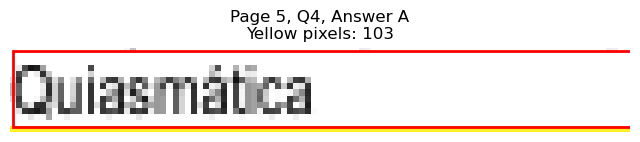

Page 5, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=127.0, y1=379.8
Page 5, Q4, B: Yellow pixels: 1181
Page 5, Q4, B: Total non-white pixels: 1417
Page 5, Q4, B: Yellow percentage: 83.3%


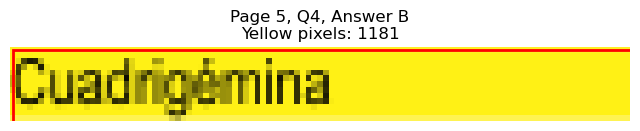

Page 5, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=101.9, y1=392.4
Page 5, Q4, C: Yellow pixels: 83
Page 5, Q4, C: Total non-white pixels: 241
Page 5, Q4, C: Yellow percentage: 34.4%


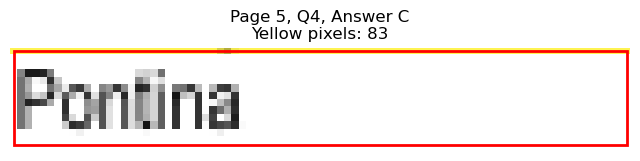

Page 5, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=389.7, y1=367.2
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 338
Page 5, Q4, D: Yellow percentage: 0.0%


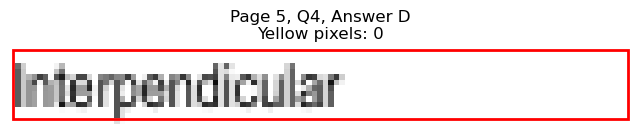

Page 5, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=428.8, y1=379.8
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 514
Page 5, Q4, E: Yellow percentage: 0.0%


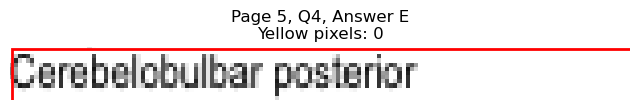


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=282.3, y1=430.3
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 1061
Page 5, Q5, A: Yellow percentage: 0.0%


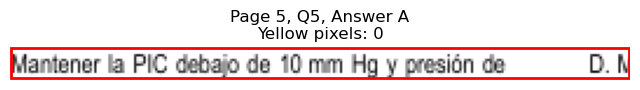

Page 5, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=282.3, y1=455.5
Page 5, Q5, B: Yellow pixels: 2033
Page 5, Q5, B: Total non-white pixels: 3065
Page 5, Q5, B: Yellow percentage: 66.3%


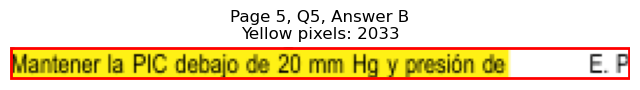

Page 5, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=282.3, y1=480.7
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 1217
Page 5, Q5, C: Yellow percentage: 0.0%


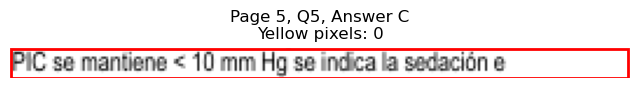

Page 5, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=540.9, y1=430.3
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 943
Page 5, Q5, D: Yellow percentage: 0.0%


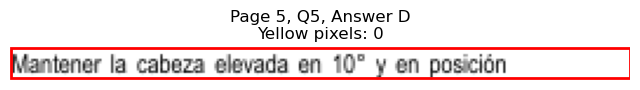

Page 5, Q5 - E: Detected box: x0=467.6, y0=442.8, x1=541.2, y1=455.5
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 367
Page 5, Q5, E: Yellow percentage: 0.0%


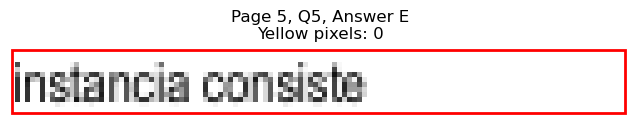


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=531.2, x1=282.3, y1=543.8
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 1122
Page 5, Q6, A: Yellow percentage: 0.0%


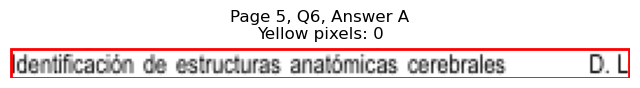

Page 5, Q6 - B: Detected box: x0=68.3, y0=556.5, x1=282.2, y1=569.2
Page 5, Q6, B: Yellow pixels: 19
Page 5, Q6, B: Total non-white pixels: 1110
Page 5, Q6, B: Yellow percentage: 1.7%


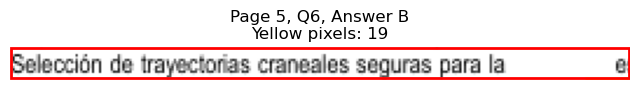

Page 5, Q6 - C: Detected box: x0=68.8, y0=581.7, x1=282.3, y1=594.4
Page 5, Q6, C: Yellow pixels: 19
Page 5, Q6, C: Total non-white pixels: 1114
Page 5, Q6, C: Yellow percentage: 1.7%


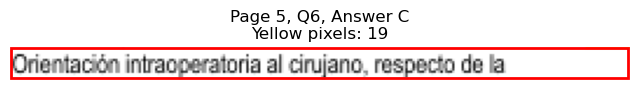

Page 5, Q6 - D: Detected box: x0=327.5, y0=531.2, x1=541.1, y1=543.8
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 1060
Page 5, Q6, D: Yellow percentage: 0.0%


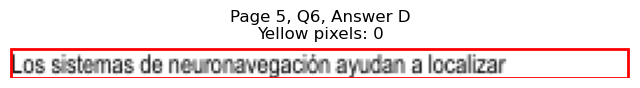

Page 5, Q6 - E: Detected box: x0=327.0, y0=569.1, x1=508.2, y1=581.8
Page 5, Q6, E: Yellow pixels: 2043
Page 5, Q6, E: Total non-white pixels: 2782
Page 5, Q6, E: Yellow percentage: 73.4%


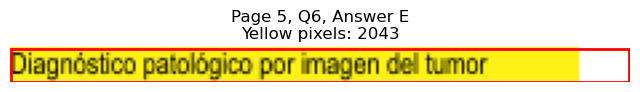


Page 5, Q6 - Selected Answer: E (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=632.2, x1=139.5, y1=644.9
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 506
Page 5, Q7, A: Yellow percentage: 0.0%


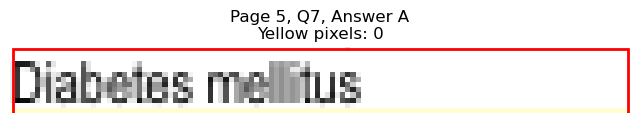

Page 5, Q7 - B: Detected box: x0=68.3, y0=644.9, x1=118.5, y1=657.5
Page 5, Q7, B: Yellow pixels: 1109
Page 5, Q7, B: Total non-white pixels: 1414
Page 5, Q7, B: Yellow percentage: 78.4%


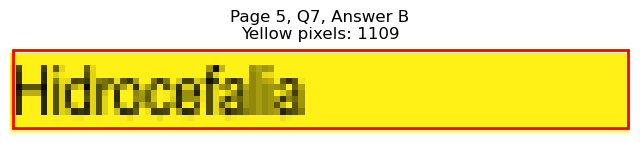

Page 5, Q7 - C: Detected box: x0=68.8, y0=657.5, x1=143.5, y1=670.1
Page 5, Q7, C: Yellow pixels: 126
Page 5, Q7, C: Total non-white pixels: 513
Page 5, Q7, C: Yellow percentage: 24.6%


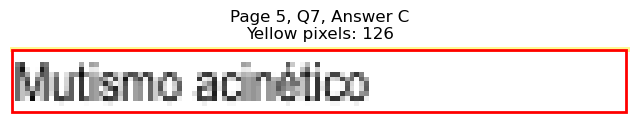

Page 5, Q7 - D: Detected box: x0=327.5, y0=632.2, x1=387.2, y1=644.9
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 332
Page 5, Q7, D: Yellow percentage: 0.0%


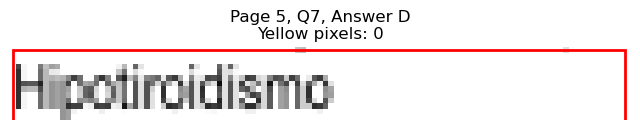

Page 5, Q7 - E: Detected box: x0=327.0, y0=644.9, x1=433.9, y1=657.5
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 543
Page 5, Q7, E: Yellow percentage: 0.0%


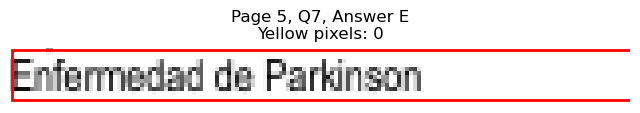


Page 5, Q7 - Selected Answer: B (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=708.0, x1=106.0, y1=720.6
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 201
Page 5, Q8, A: Yellow percentage: 0.0%


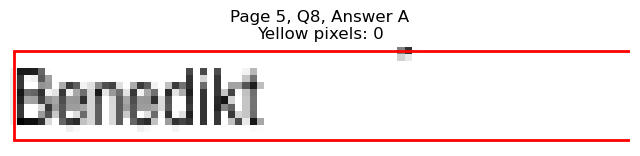

Page 5, Q8 - B: Detected box: x0=68.3, y0=720.6, x1=112.0, y1=733.2
Page 5, Q8, B: Yellow pixels: 94
Page 5, Q8, B: Total non-white pixels: 330
Page 5, Q8, B: Yellow percentage: 28.5%


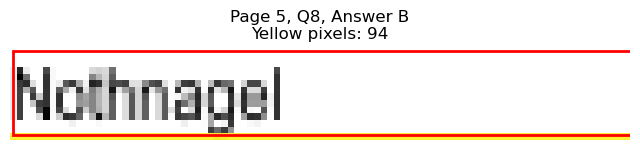

Page 5, Q8 - C: Detected box: x0=68.8, y0=733.2, x1=113.4, y1=745.8
Page 5, Q8, C: Yellow pixels: 1047
Page 5, Q8, C: Total non-white pixels: 1248
Page 5, Q8, C: Yellow percentage: 83.9%


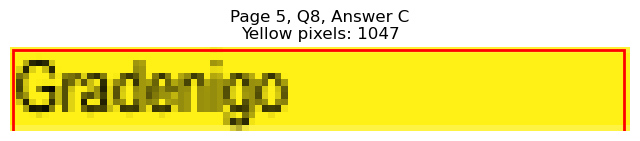

Page 5, Q8 - D: Detected box: x0=327.5, y0=708.0, x1=356.1, y1=720.6
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 135
Page 5, Q8, D: Yellow percentage: 0.0%


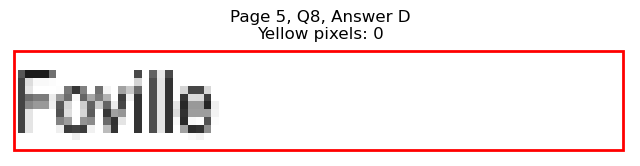

Page 5, Q8 - E: Detected box: x0=327.0, y0=720.6, x1=353.7, y1=733.2
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 151
Page 5, Q8, E: Yellow percentage: 0.0%


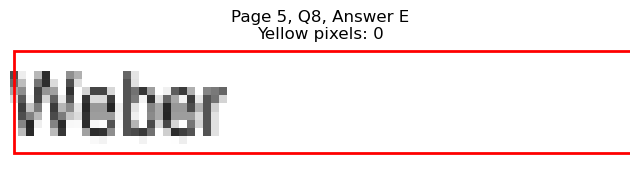


Page 5, Q8 - Selected Answer: C (based on yellow pixel count)





Page 6: Found 9 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=103.9, y1=114.7
Page 6, Q1, A: Yellow pixels: 983
Page 6, Q1, A: Total non-white pixels: 1118
Page 6, Q1, A: Yellow percentage: 87.9%


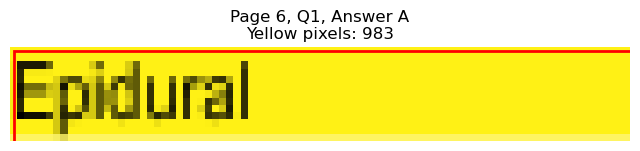

Page 6, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=96.4, y1=127.3
Page 6, Q1, B: Yellow pixels: 79
Page 6, Q1, B: Total non-white pixels: 227
Page 6, Q1, B: Yellow percentage: 34.8%


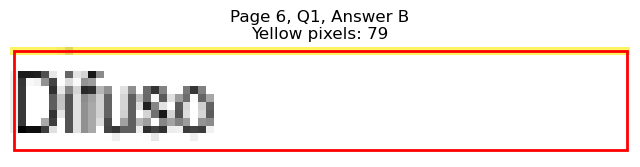

Page 6, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=107.4, y1=139.9
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 208
Page 6, Q1, C: Yellow percentage: 0.0%


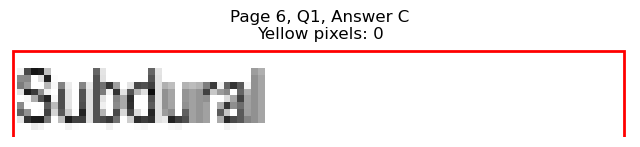

Page 6, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=366.7, y1=114.7
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 196
Page 6, Q1, D: Yellow percentage: 0.0%


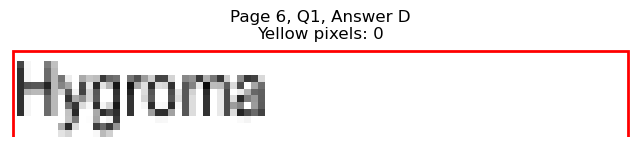

Page 6, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=390.3, y1=127.3
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 339
Page 6, Q1, E: Yellow percentage: 0.0%


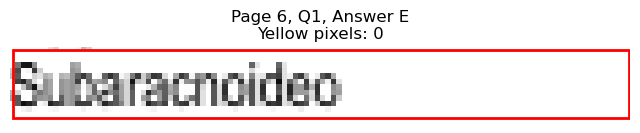


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=187.7, y1=190.4
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 605
Page 6, Q2, A: Yellow percentage: 0.0%


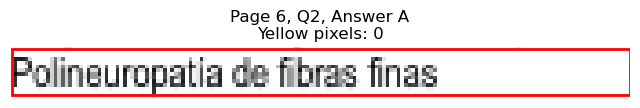

Page 6, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=140.5, y1=203.0
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 389
Page 6, Q2, B: Yellow percentage: 0.0%


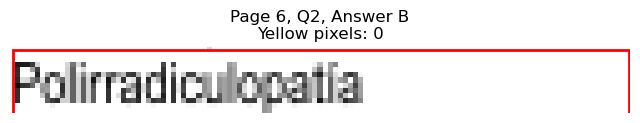

Page 6, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=168.1, y1=215.6
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 454
Page 6, Q2, C: Yellow percentage: 0.0%


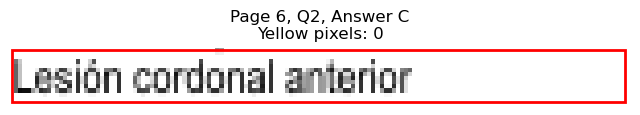

Page 6, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=416.8, y1=190.4
Page 6, Q2, D: Yellow pixels: 1333
Page 6, Q2, D: Total non-white pixels: 1960
Page 6, Q2, D: Yellow percentage: 68.0%


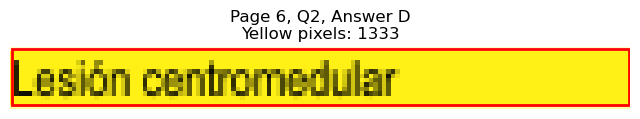

Page 6, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=430.9, y1=203.0
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 666
Page 6, Q2, E: Yellow percentage: 0.0%


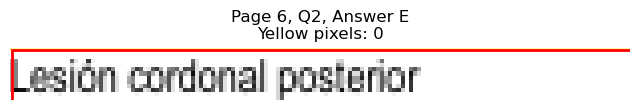


Page 6, Q2 - Selected Answer: D (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=199.1, y1=278.7
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 676
Page 6, Q3, A: Yellow percentage: 0.0%


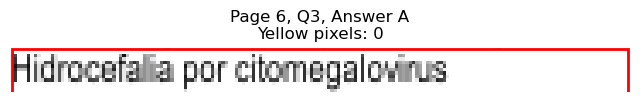

Page 6, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=185.7, y1=291.5
Page 6, Q3, B: Yellow pixels: 1713
Page 6, Q3, B: Total non-white pixels: 2352
Page 6, Q3, B: Yellow percentage: 72.8%


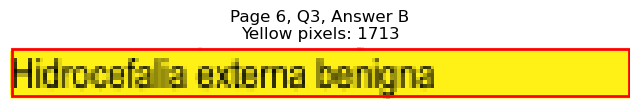

Page 6, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=183.1, y1=304.1
Page 6, Q3, C: Yellow pixels: 165
Page 6, Q3, C: Total non-white pixels: 739
Page 6, Q3, C: Yellow percentage: 22.3%


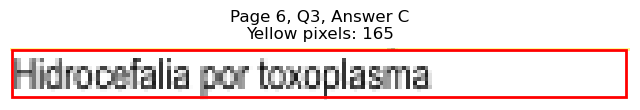

Page 6, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=411.3, y1=278.7
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 428
Page 6, Q3, D: Yellow percentage: 0.0%


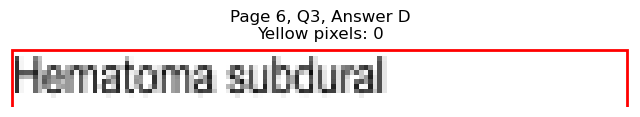

Page 6, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=412.3, y1=291.5
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 429
Page 6, Q3, E: Yellow percentage: 0.0%


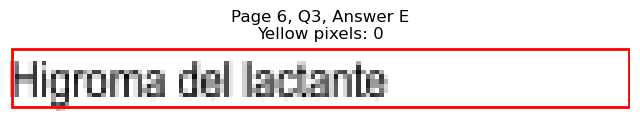


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=209.2, y1=341.9
Page 6, Q4, A: Yellow pixels: 1971
Page 6, Q4, A: Total non-white pixels: 2496
Page 6, Q4, A: Yellow percentage: 79.0%


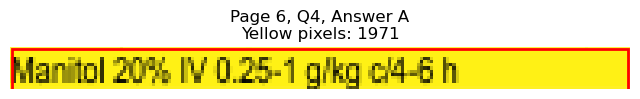

Page 6, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=206.2, y1=354.6
Page 6, Q4, B: Yellow pixels: 181
Page 6, Q4, B: Total non-white pixels: 853
Page 6, Q4, B: Yellow percentage: 21.2%


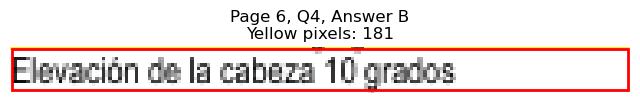

Page 6, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=234.3, y1=367.2
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 829
Page 6, Q4, C: Yellow percentage: 0.0%


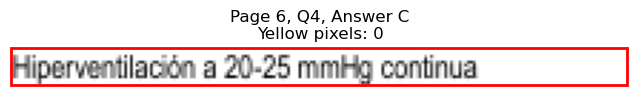

Page 6, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=456.5, y1=341.9
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 659
Page 6, Q4, D: Yellow percentage: 0.0%


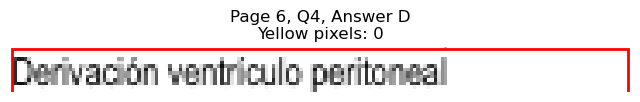

Page 6, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=449.5, y1=354.6
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 589
Page 6, Q4, E: Yellow percentage: 0.0%


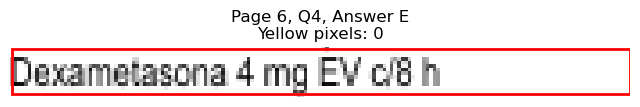


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=183.6, y1=417.6
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 542
Page 6, Q5, A: Yellow percentage: 0.0%


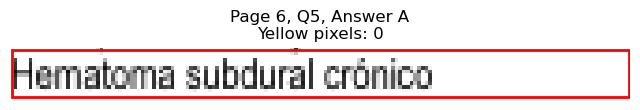

Page 6, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=176.7, y1=430.3
Page 6, Q5, B: Yellow pixels: 1497
Page 6, Q5, B: Total non-white pixels: 2226
Page 6, Q5, B: Yellow percentage: 67.3%


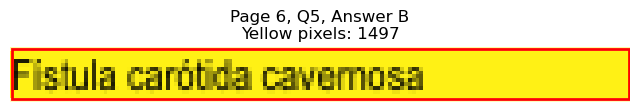

Page 6, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=210.3, y1=442.9
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 869
Page 6, Q5, C: Yellow percentage: 0.0%


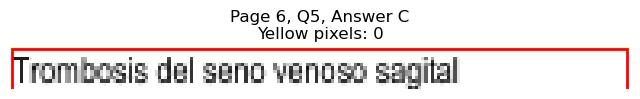

Page 6, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=436.9, y1=417.6
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 582
Page 6, Q5, D: Yellow percentage: 0.0%


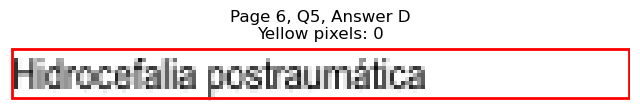

Page 6, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=452.0, y1=430.3
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 588
Page 6, Q5, E: Yellow percentage: 0.0%


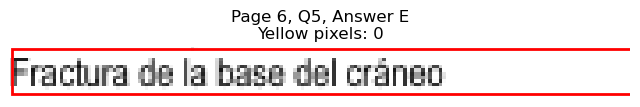


Page 6, Q5 - Selected Answer: B (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=77.3, y1=493.4
Page 6, Q6, A: Yellow pixels: 696
Page 6, Q6, A: Total non-white pixels: 840
Page 6, Q6, A: Yellow percentage: 82.9%


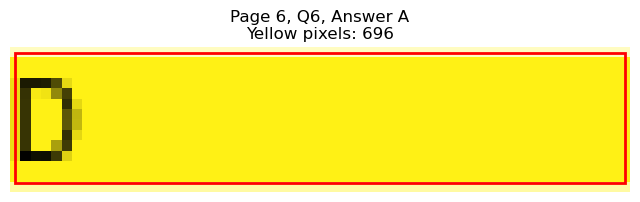

Page 6, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=76.8, y1=506.0
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 94
Page 6, Q6, B: Yellow percentage: 0.0%


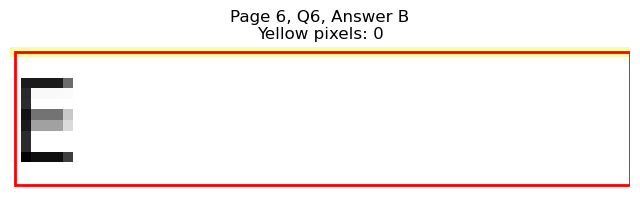

Page 6, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=77.8, y1=518.6
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 34
Page 6, Q6, C: Yellow percentage: 0.0%


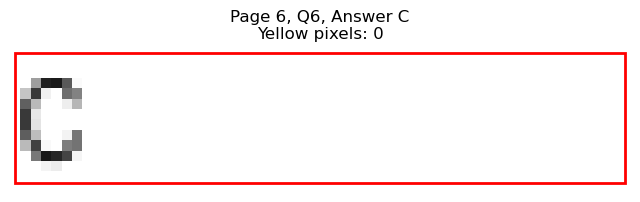

Page 6, Q6 - D: Detected box: x0=315.4, y0=480.8, x1=324.4, y1=493.4
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 73
Page 6, Q6, D: Yellow percentage: 0.0%


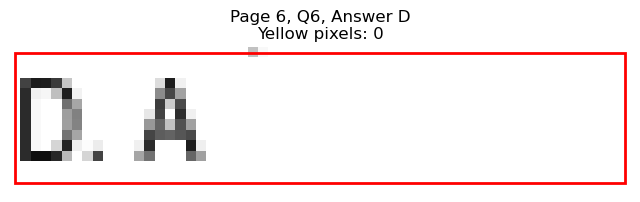

Page 6, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=335.6, y1=506.0
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 40
Page 6, Q6, E: Yellow percentage: 0.0%


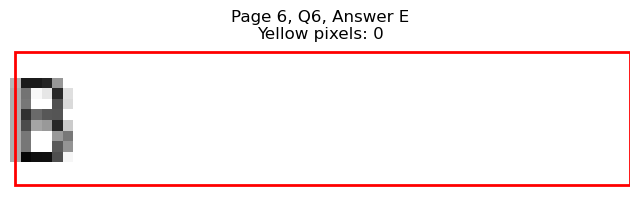


Page 6, Q6 - Selected Answer: A (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=118.5, y1=556.4
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 267
Page 6, Q7, A: Yellow percentage: 0.0%


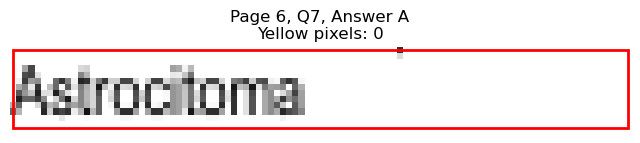

Page 6, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=124.0, y1=569.2
Page 6, Q7, B: Yellow pixels: 106
Page 6, Q7, B: Total non-white pixels: 379
Page 6, Q7, B: Yellow percentage: 28.0%


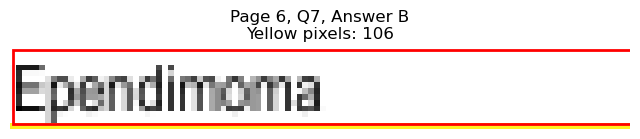

Page 6, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=149.1, y1=581.8
Page 6, Q7, C: Yellow pixels: 1361
Page 6, Q7, C: Total non-white pixels: 1716
Page 6, Q7, C: Yellow percentage: 79.3%


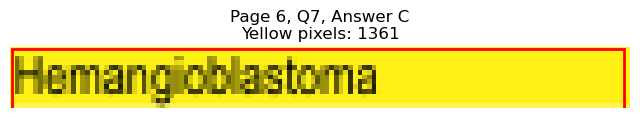

Page 6, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=405.8, y1=556.4
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 413
Page 6, Q7, D: Yellow percentage: 0.0%


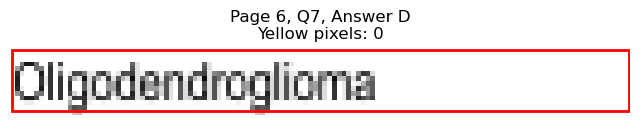

Page 6, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=466.5, y1=569.2
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 661
Page 6, Q7, E: Yellow percentage: 0.0%


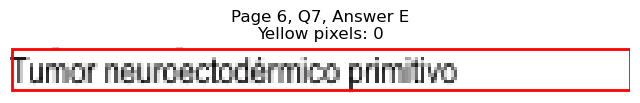


Page 6, Q7 - Selected Answer: C (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=168.1, y1=632.3
Page 6, Q8, A: Yellow pixels: 151
Page 6, Q8, A: Total non-white pixels: 659
Page 6, Q8, A: Yellow percentage: 22.9%


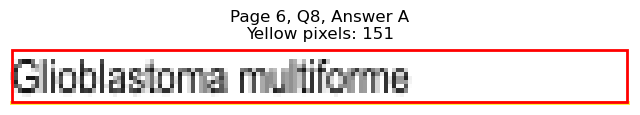

Page 6, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=174.1, y1=644.9
Page 6, Q8, B: Yellow pixels: 1618
Page 6, Q8, B: Total non-white pixels: 2041
Page 6, Q8, B: Yellow percentage: 79.3%


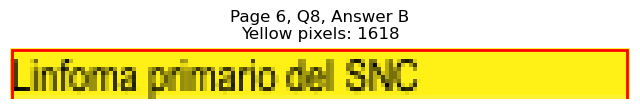

Page 6, Q8 - C: Detected box: x0=68.8, y0=569.1, x1=149.1, y1=581.8
Page 6, Q8, C: Yellow pixels: 1361
Page 6, Q8, C: Total non-white pixels: 1716
Page 6, Q8, C: Yellow percentage: 79.3%


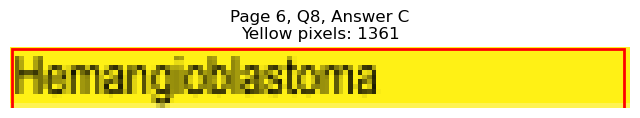

Page 6, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=396.3, y1=632.3
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 380
Page 6, Q8, D: Yellow percentage: 0.0%


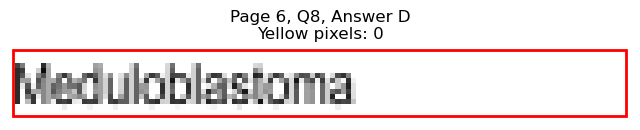

Page 6, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=405.3, y1=644.9
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 439
Page 6, Q8, E: Yellow percentage: 0.0%


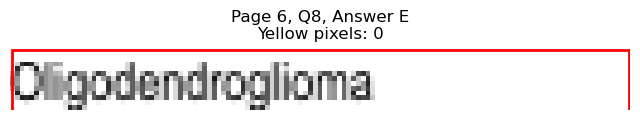


Page 6, Q8 - Selected Answer: B (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=78.4, y1=695.3
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 32
Page 6, Q9, A: Yellow percentage: 0.0%


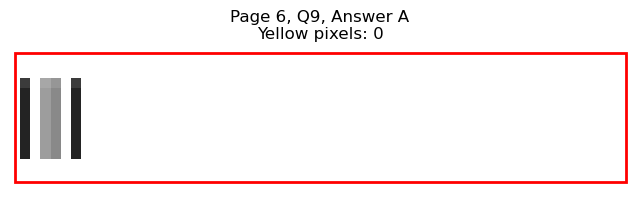

Page 6, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=79.3, y1=708.0
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 36
Page 6, Q9, B: Yellow percentage: 0.0%


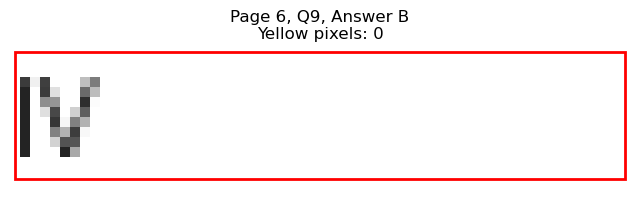

Page 6, Q9 - C: Detected box: x0=56.6, y0=708.0, x1=65.6, y1=720.6
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 65
Page 6, Q9, C: Yellow percentage: 0.0%


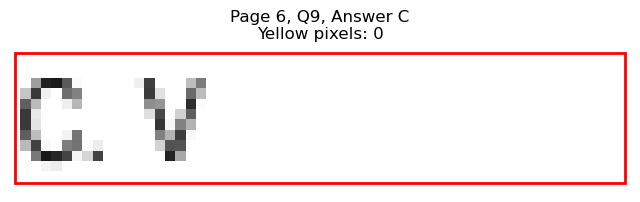

Page 6, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=338.6, y1=695.3
Page 6, Q9, D: Yellow pixels: 708
Page 6, Q9, D: Total non-white pixels: 868
Page 6, Q9, D: Yellow percentage: 81.6%


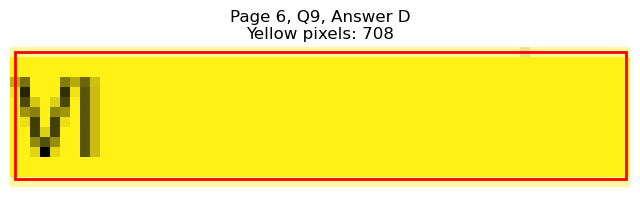

Page 6, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=340.6, y1=708.0
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 122
Page 6, Q9, E: Yellow percentage: 0.0%


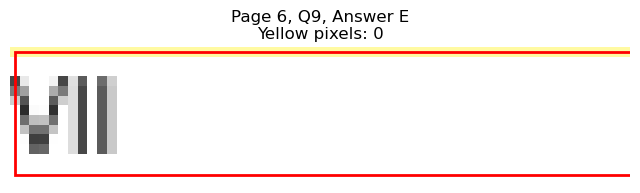


Page 6, Q9 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=136.6, y1=102.1
Page 7, Q1, A: Yellow pixels: 119
Page 7, Q1, A: Total non-white pixels: 449
Page 7, Q1, A: Yellow percentage: 26.5%


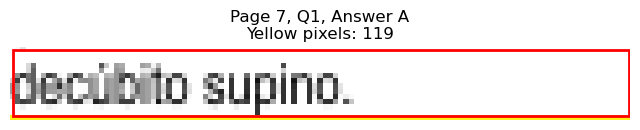

Page 7, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=117.5, y1=114.7
Page 7, Q1, B: Yellow pixels: 1097
Page 7, Q1, B: Total non-white pixels: 1300
Page 7, Q1, B: Yellow percentage: 84.4%


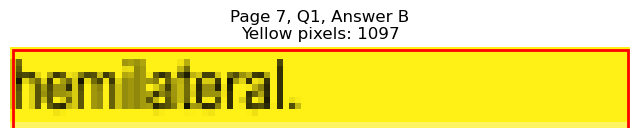

Page 7, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=133.5, y1=127.3
Page 7, Q1, C: Yellow pixels: 116
Page 7, Q1, C: Total non-white pixels: 405
Page 7, Q1, C: Yellow percentage: 28.6%


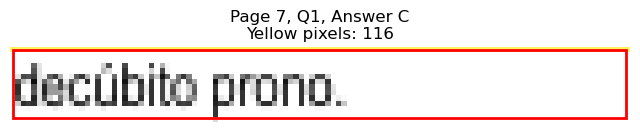

Page 7, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=357.2, y1=102.1
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 140
Page 7, Q1, D: Yellow percentage: 0.0%


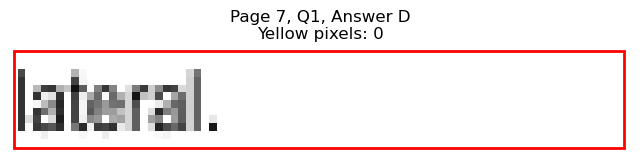

Page 7, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=364.1, y1=114.7
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 186
Page 7, Q1, E: Yellow percentage: 0.0%


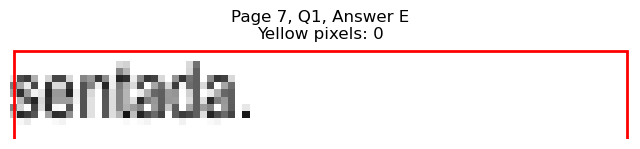


Page 7, Q1 - Selected Answer: B (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=102.4, y1=165.2
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 186
Page 7, Q2, A: Yellow percentage: 0.0%


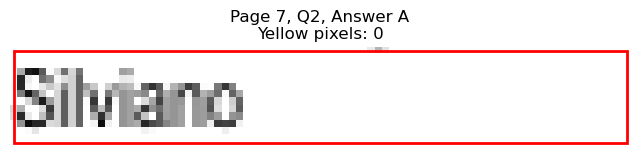

Page 7, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=130.5, y1=177.8
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 424
Page 7, Q2, B: Yellow percentage: 0.0%


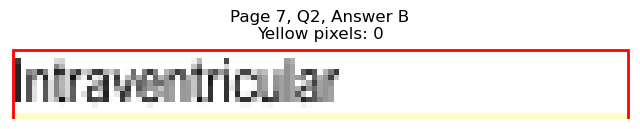

Page 7, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=145.0, y1=190.4
Page 7, Q2, C: Yellow pixels: 1202
Page 7, Q2, C: Total non-white pixels: 1778
Page 7, Q2, C: Yellow percentage: 67.6%


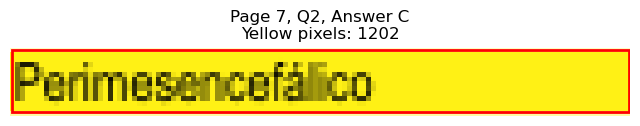

Page 7, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=373.7, y1=165.2
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 231
Page 7, Q2, D: Yellow percentage: 0.0%


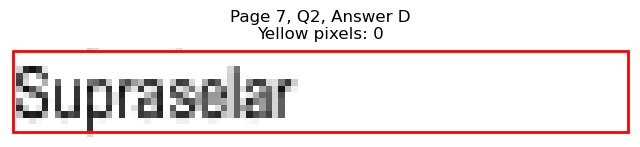

Page 7, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=393.8, y1=177.8
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 349
Page 7, Q2, E: Yellow percentage: 0.0%


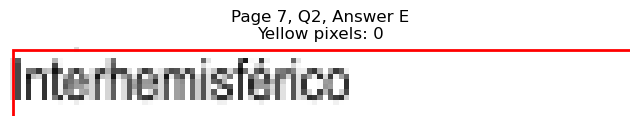


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=121.0, y1=253.5
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 518
Page 7, Q3, A: Yellow percentage: 0.0%


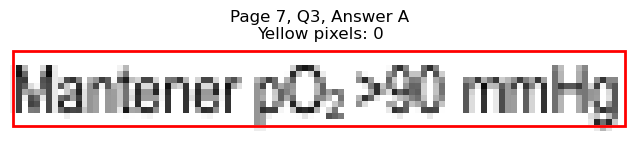

Page 7, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=175.7, y1=266.1
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 533
Page 7, Q3, B: Yellow percentage: 0.0%


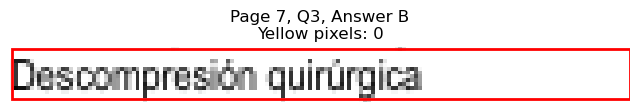

Page 7, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=148.1, y1=278.7
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 404
Page 7, Q3, C: Yellow percentage: 0.0%


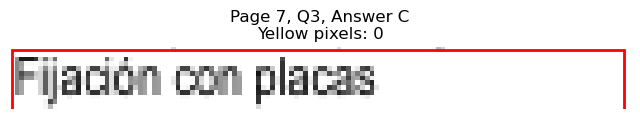

Page 7, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=397.9, y1=253.5
Page 7, Q3, D: Yellow pixels: 1309
Page 7, Q3, D: Total non-white pixels: 1694
Page 7, Q3, D: Yellow percentage: 77.3%


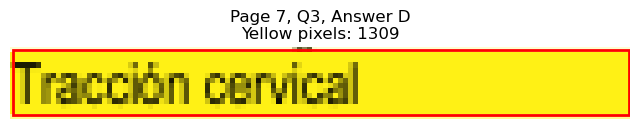

Page 7, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=434.8, y1=266.1
Page 7, Q3, E: Yellow pixels: 158
Page 7, Q3, E: Total non-white pixels: 668
Page 7, Q3, E: Yellow percentage: 23.7%


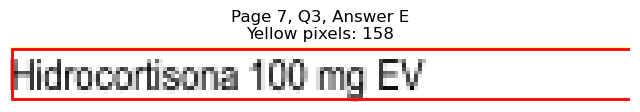


Page 7, Q3 - Selected Answer: D (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=143.5, y1=316.7
Page 7, Q4, A: Yellow pixels: 1347
Page 7, Q4, A: Total non-white pixels: 1638
Page 7, Q4, A: Yellow percentage: 82.2%


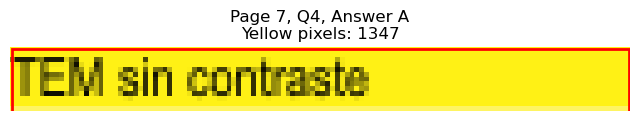

Page 7, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=145.0, y1=329.3
Page 7, Q4, B: Yellow pixels: 127
Page 7, Q4, B: Total non-white pixels: 528
Page 7, Q4, B: Yellow percentage: 24.1%


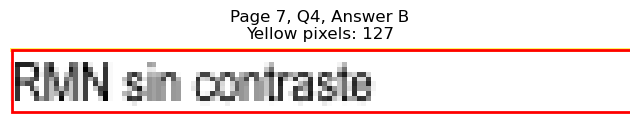

Page 7, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=147.0, y1=341.9
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 382
Page 7, Q4, C: Yellow percentage: 0.0%


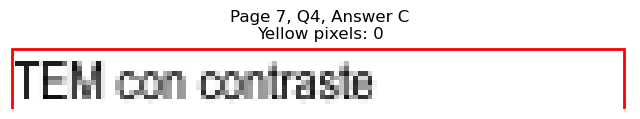

Page 7, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=419.3, y1=316.7
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 479
Page 7, Q4, D: Yellow percentage: 0.0%


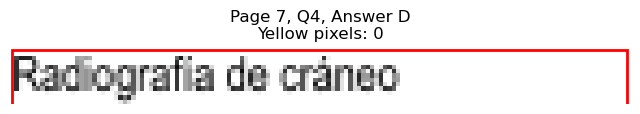

Page 7, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=406.7, y1=329.3
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 405
Page 7, Q4, E: Yellow percentage: 0.0%


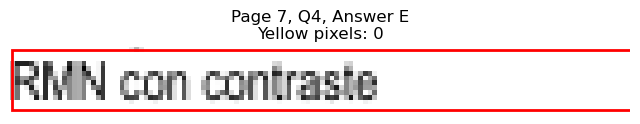


Page 7, Q4 - Selected Answer: A (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=212.8, y1=379.8
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 685
Page 7, Q5, A: Yellow percentage: 0.0%


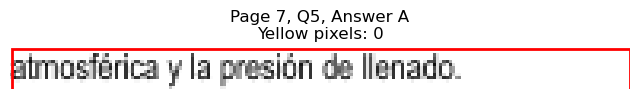

Page 7, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=282.2, y1=392.4
Page 7, Q5, B: Yellow pixels: 172
Page 7, Q5, B: Total non-white pixels: 1292
Page 7, Q5, B: Yellow percentage: 13.3%


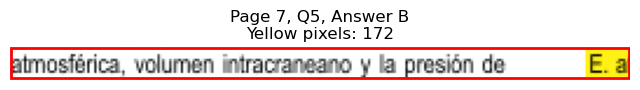

Page 7, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=264.4, y1=417.6
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 973
Page 7, Q5, C: Yellow percentage: 0.0%


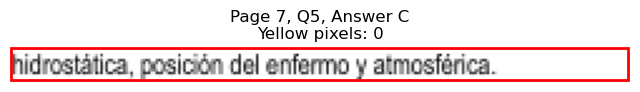

Page 7, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=467.5, y1=379.8
Page 7, Q5, D: Yellow pixels: 1
Page 7, Q5, D: Total non-white pixels: 867
Page 7, Q5, D: Yellow percentage: 0.1%


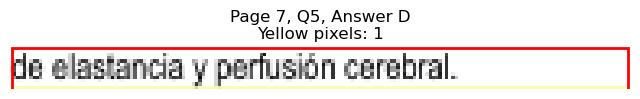

Page 7, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=522.7, y1=392.4
Page 7, Q5, E: Yellow pixels: 1825
Page 7, Q5, E: Total non-white pixels: 2996
Page 7, Q5, E: Yellow percentage: 60.9%


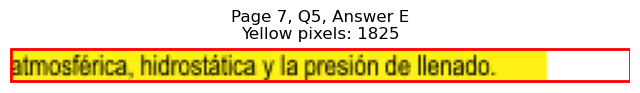


Page 7, Q5 - Selected Answer: E (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=179.7, y1=468.1
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 511
Page 7, Q6, A: Yellow percentage: 0.0%


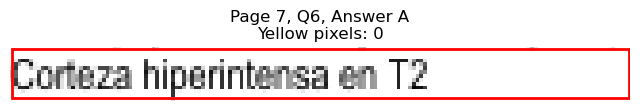

Page 7, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=169.1, y1=480.7
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 520
Page 7, Q6, B: Yellow percentage: 0.0%


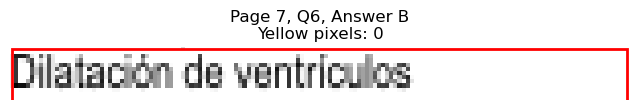

Page 7, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=146.5, y1=493.4
Page 7, Q6, C: Yellow pixels: 1206
Page 7, Q6, C: Total non-white pixels: 1806
Page 7, Q6, C: Yellow percentage: 66.8%


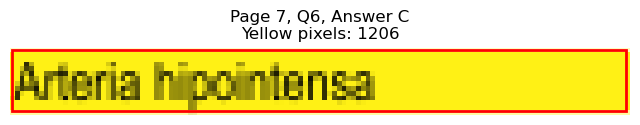

Page 7, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=445.4, y1=468.1
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 595
Page 7, Q6, D: Yellow percentage: 0.0%


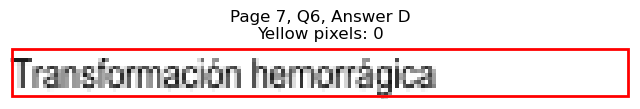

Page 7, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=395.8, y1=480.7
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 375
Page 7, Q6, E: Yellow percentage: 0.0%


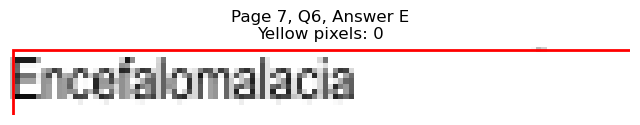


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=119.4, y1=531.2
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 283
Page 7, Q7, A: Yellow percentage: 0.0%


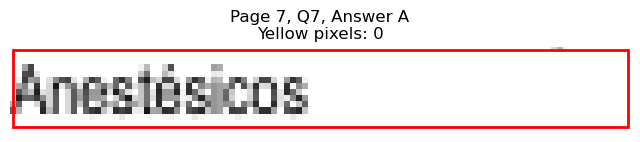

Page 7, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=92.9, y1=543.8
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 223
Page 7, Q7, B: Yellow percentage: 0.0%


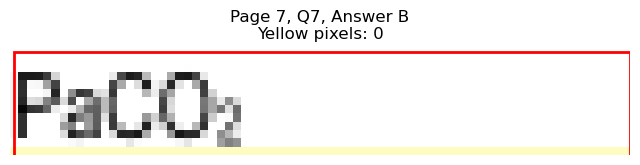

Page 7, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=177.6, y1=556.4
Page 7, Q7, C: Yellow pixels: 1656
Page 7, Q7, C: Total non-white pixels: 2240
Page 7, Q7, C: Yellow percentage: 73.9%


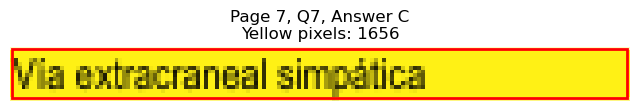

Page 7, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=381.8, y1=531.2
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 272
Page 7, Q7, D: Yellow percentage: 0.0%


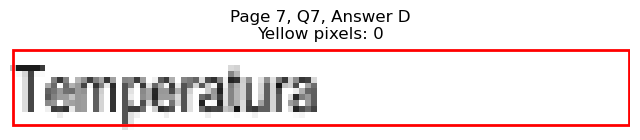

Page 7, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=417.9, y1=543.8
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 479
Page 7, Q7, E: Yellow percentage: 0.0%


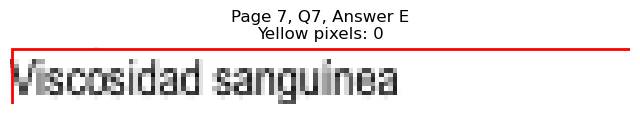


Page 7, Q7 - Selected Answer: C (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=137.5, y1=594.4
Page 7, Q8, A: Yellow pixels: 120
Page 7, Q8, A: Total non-white pixels: 472
Page 7, Q8, A: Yellow percentage: 25.4%


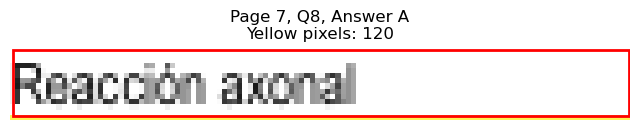

Page 7, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=97.9, y1=607.0
Page 7, Q8, B: Yellow pixels: 920
Page 7, Q8, B: Total non-white pixels: 1040
Page 7, Q8, B: Yellow percentage: 88.5%


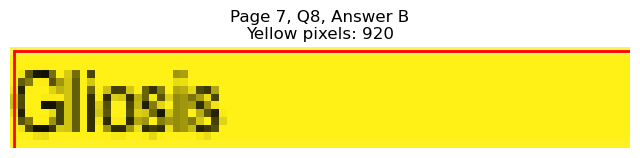

Page 7, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=220.8, y1=619.6
Page 7, Q8, C: Yellow pixels: 203
Page 7, Q8, C: Total non-white pixels: 929
Page 7, Q8, C: Yellow percentage: 21.9%


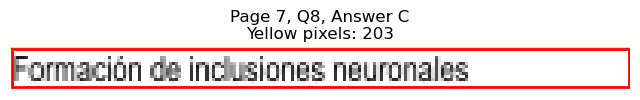

Page 7, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=384.2, y1=594.4
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 301
Page 7, Q8, D: Yellow percentage: 0.0%


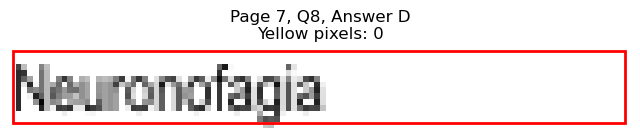

Page 7, Q8 - E: Detected box: x0=327.0, y0=594.3, x1=407.8, y1=607.0
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 399
Page 7, Q8, E: Yellow percentage: 0.0%


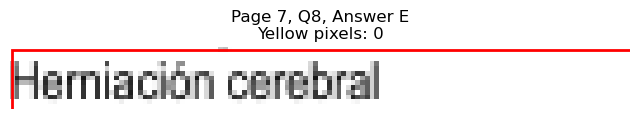


Page 7, Q8 - Selected Answer: B (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=122.4, y1=670.1
Page 7, Q9, A: Yellow pixels: 105
Page 7, Q9, A: Total non-white pixels: 410
Page 7, Q9, A: Yellow percentage: 25.6%


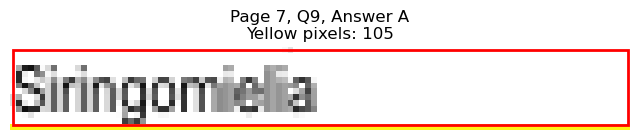

Page 7, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=149.5, y1=682.7
Page 7, Q9, B: Yellow pixels: 1437
Page 7, Q9, B: Total non-white pixels: 1716
Page 7, Q9, B: Yellow percentage: 83.7%


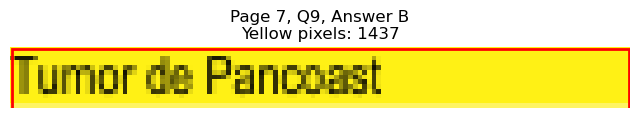

Page 7, Q9 - C: Detected box: x0=68.8, y0=682.7, x1=215.7, y1=695.3
Page 7, Q9, C: Yellow pixels: 198
Page 7, Q9, C: Total non-white pixels: 930
Page 7, Q9, C: Yellow percentage: 21.3%


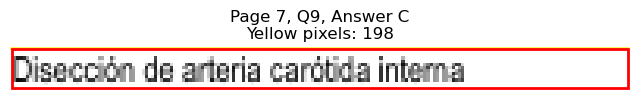

Page 7, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=411.3, y1=670.1
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 410
Page 7, Q9, D: Yellow percentage: 0.0%


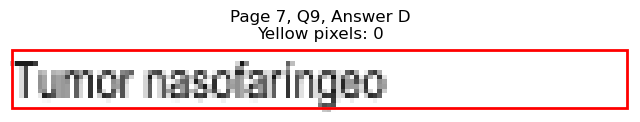

Page 7, Q9 - E: Detected box: x0=327.0, y0=670.1, x1=436.4, y1=682.7
Page 7, Q9, E: Yellow pixels: 0
Page 7, Q9, E: Total non-white pixels: 500
Page 7, Q9, E: Yellow percentage: 0.0%


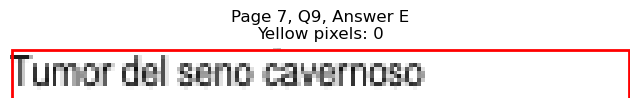


Page 7, Q9 - Selected Answer: B (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=194.2, y1=127.3
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 602
Page 8, Q1, A: Yellow percentage: 0.0%


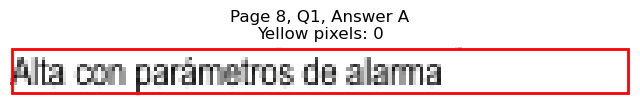

Page 8, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=254.4, y1=139.9
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 932
Page 8, Q1, B: Yellow percentage: 0.0%


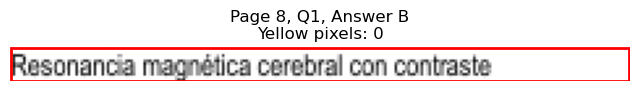

Page 8, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=269.9, y1=152.6
Page 8, Q1, C: Yellow pixels: 1971
Page 8, Q1, C: Total non-white pixels: 2996
Page 8, Q1, C: Yellow percentage: 65.8%


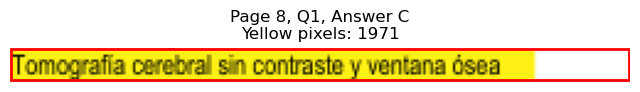

Page 8, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=433.9, y1=127.3
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 502
Page 8, Q1, D: Yellow percentage: 0.0%


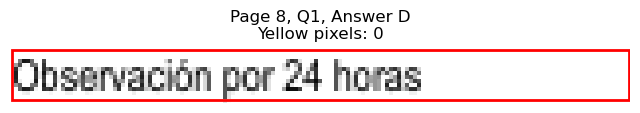

Page 8, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=418.9, y1=139.9
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 453
Page 8, Q1, E: Yellow percentage: 0.0%


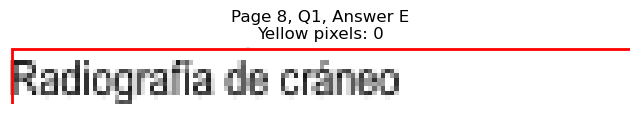


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=156.6, y1=215.6
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 428
Page 8, Q2, A: Yellow percentage: 0.0%


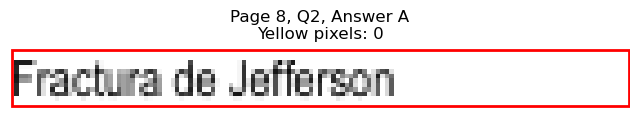

Page 8, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=174.7, y1=228.3
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 528
Page 8, Q2, B: Yellow percentage: 0.0%


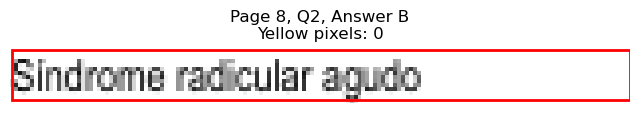

Page 8, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=191.3, y1=240.9
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 619
Page 8, Q2, C: Yellow percentage: 0.0%


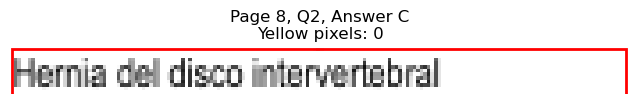

Page 8, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=410.3, y1=215.6
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 399
Page 8, Q2, D: Yellow percentage: 0.0%


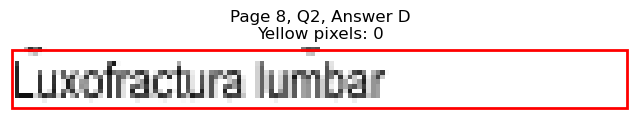

Page 8, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=409.3, y1=228.3
Page 8, Q2, E: Yellow pixels: 1299
Page 8, Q2, E: Total non-white pixels: 1862
Page 8, Q2, E: Yellow percentage: 69.8%


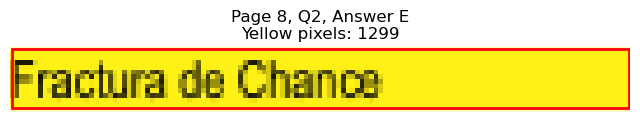


Page 8, Q2 - Selected Answer: E (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=245.8, y1=291.5
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 881
Page 8, Q3, A: Yellow percentage: 0.0%


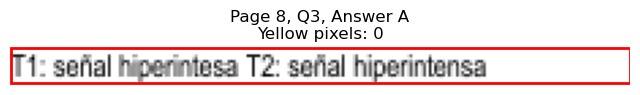

Page 8, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=282.4, y1=304.1
Page 8, Q3, B: Yellow pixels: 220
Page 8, Q3, B: Total non-white pixels: 1353
Page 8, Q3, B: Yellow percentage: 16.3%


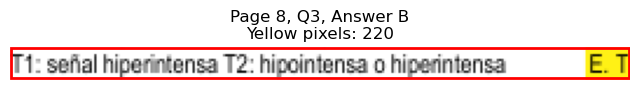

Page 8, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=273.5, y1=316.7
Page 8, Q3, C: Yellow pixels: 130
Page 8, Q3, C: Total non-white pixels: 1124
Page 8, Q3, C: Yellow percentage: 11.6%


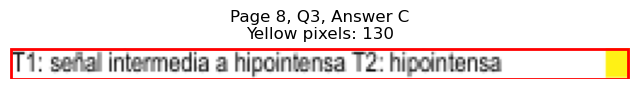

Page 8, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=485.5, y1=291.5
Page 8, Q3, D: Yellow pixels: 209
Page 8, Q3, D: Total non-white pixels: 973
Page 8, Q3, D: Yellow percentage: 21.5%


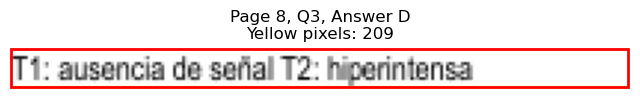

Page 8, Q3 - E: Detected box: x0=482.7, y0=291.4, x1=527.3, y1=304.1
Page 8, Q3, E: Yellow pixels: 620
Page 8, Q3, E: Total non-white pixels: 826
Page 8, Q3, E: Yellow percentage: 75.1%


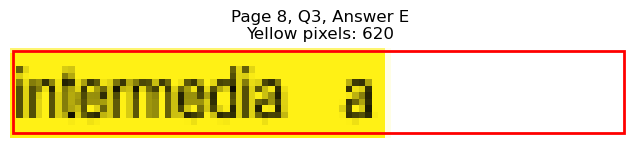


Page 8, Q3 - Selected Answer: E (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=196.2, y1=354.6
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 626
Page 8, Q4, A: Yellow percentage: 0.0%


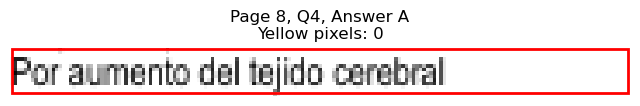

Page 8, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=157.6, y1=367.2
Page 8, Q4, B: Yellow pixels: 140
Page 8, Q4, B: Total non-white pixels: 548
Page 8, Q4, B: Yellow percentage: 25.5%


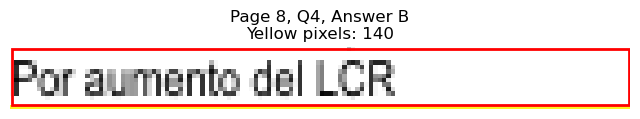

Page 8, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=282.2, y1=379.8
Page 8, Q4, C: Yellow pixels: 1981
Page 8, Q4, C: Total non-white pixels: 2782
Page 8, Q4, C: Yellow percentage: 71.2%


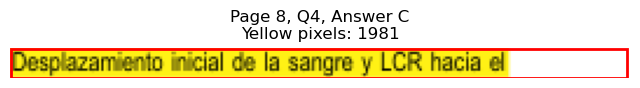

Page 8, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=467.5, y1=354.6
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 697
Page 8, Q4, D: Yellow percentage: 0.0%


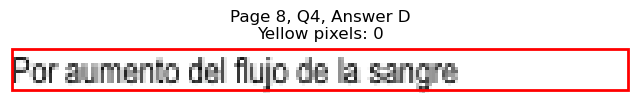

Page 8, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=437.5, y1=367.2
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 536
Page 8, Q4, E: Yellow percentage: 0.0%


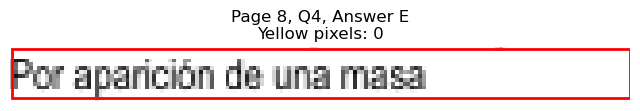


Page 8, Q4 - Selected Answer: C (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=134.1, y1=430.3
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 343
Page 8, Q5, A: Yellow percentage: 0.0%


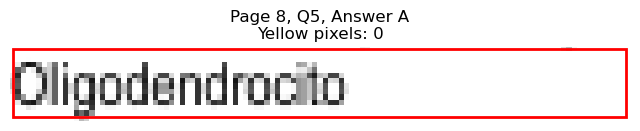

Page 8, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=153.5, y1=442.9
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 409
Page 8, Q5, B: Yellow percentage: 0.0%


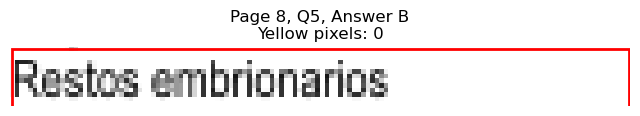

Page 8, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=122.4, y1=455.5
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 252
Page 8, Q5, C: Yellow percentage: 0.0%


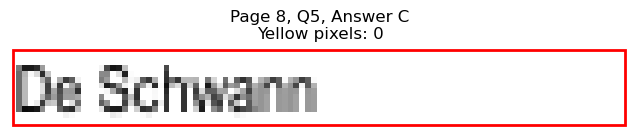

Page 8, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=411.8, y1=430.3
Page 8, Q5, D: Yellow pixels: 1299
Page 8, Q5, D: Total non-white pixels: 1890
Page 8, Q5, D: Yellow percentage: 68.7%


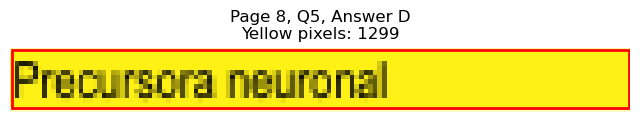

Page 8, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=364.6, y1=442.9
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 284
Page 8, Q5, E: Yellow percentage: 0.0%


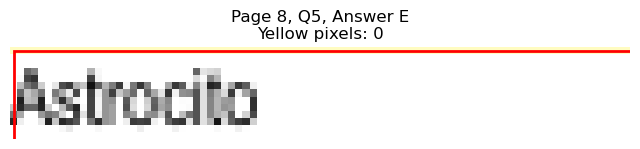


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=56.6, y0=506.0, x1=65.2, y1=518.6
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 62
Page 8, Q6, A: Yellow percentage: 0.0%


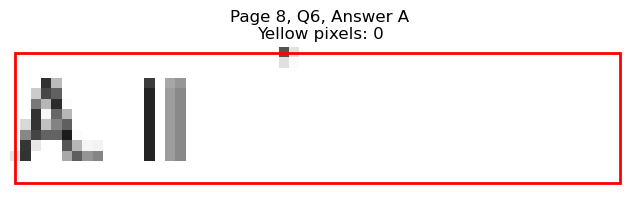

Page 8, Q6 - B: Detected box: x0=56.6, y0=518.6, x1=65.2, y1=531.2
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 50
Page 8, Q6, B: Yellow percentage: 0.0%


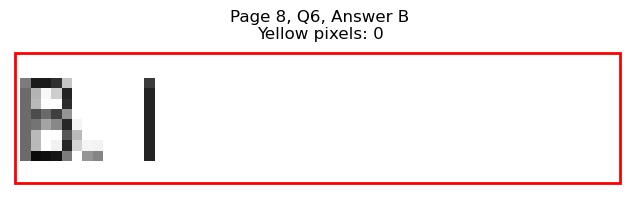

Page 8, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=79.8, y1=543.8
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 44
Page 8, Q6, C: Yellow percentage: 0.0%


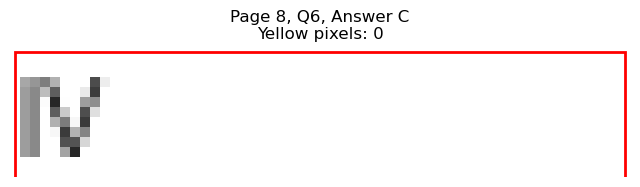

Page 8, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=337.6, y1=518.6
Page 8, Q6, D: Yellow pixels: 753
Page 8, Q6, D: Total non-white pixels: 854
Page 8, Q6, D: Yellow percentage: 88.2%


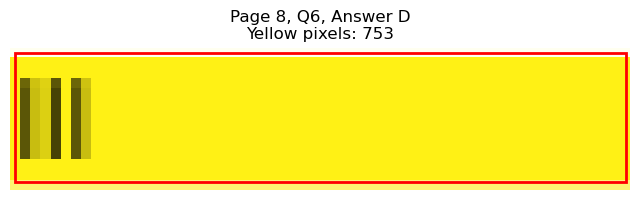

Page 8, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=335.6, y1=531.2
Page 8, Q6, E: Yellow pixels: 59
Page 8, Q6, E: Total non-white pixels: 85
Page 8, Q6, E: Yellow percentage: 69.4%


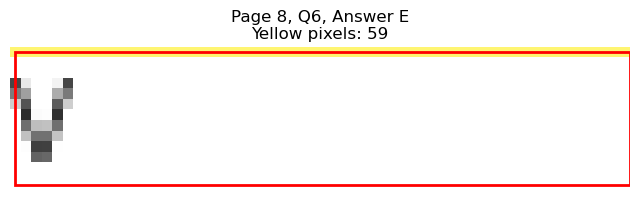


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=79.3, y1=581.8
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 38
Page 8, Q7, A: Yellow percentage: 0.0%


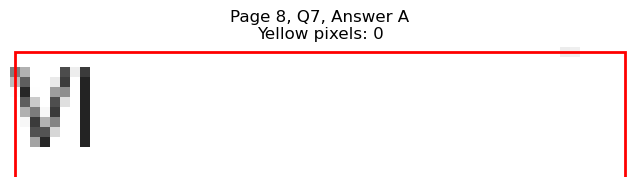

Page 8, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=76.8, y1=594.4
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 28
Page 8, Q7, B: Yellow percentage: 0.0%


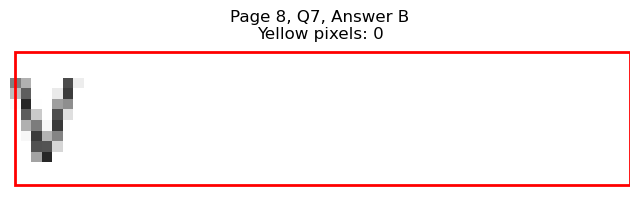

Page 8, Q7 - C: Detected box: x0=68.8, y0=531.2, x1=79.8, y1=543.8
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 44
Page 8, Q7, C: Yellow percentage: 0.0%


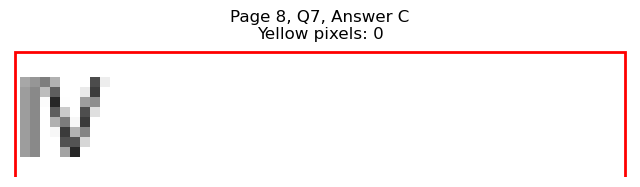

Page 8, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=341.1, y1=581.8
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 127
Page 8, Q7, D: Yellow percentage: 0.0%


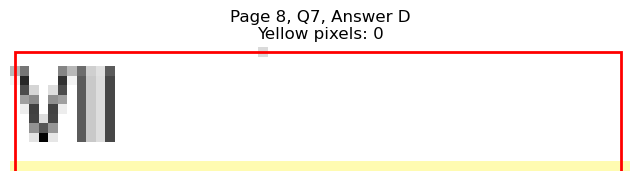

Page 8, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=337.1, y1=594.4
Page 8, Q7, E: Yellow pixels: 700
Page 8, Q7, E: Total non-white pixels: 854
Page 8, Q7, E: Yellow percentage: 82.0%


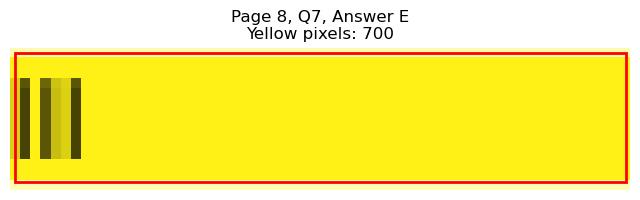


Page 8, Q7 - Selected Answer: E (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=205.8, y1=644.9
Page 8, Q8, A: Yellow pixels: 1863
Page 8, Q8, A: Total non-white pixels: 2444
Page 8, Q8, A: Yellow percentage: 76.2%


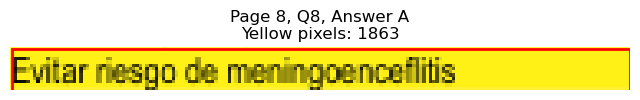

Page 8, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=216.3, y1=657.5
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 733
Page 8, Q8, B: Yellow percentage: 0.0%


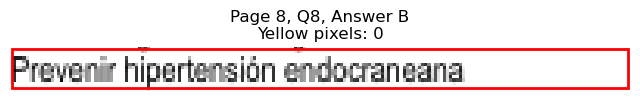

Page 8, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=196.2, y1=670.1
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 649
Page 8, Q8, C: Yellow percentage: 0.0%


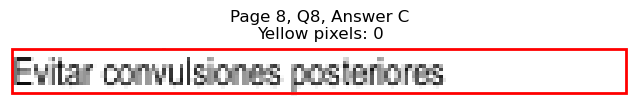

Page 8, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=436.9, y1=644.9
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 534
Page 8, Q8, D: Yellow percentage: 0.0%


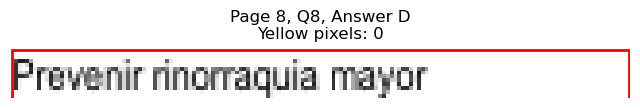

Page 8, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=432.4, y1=657.5
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 538
Page 8, Q8, E: Yellow percentage: 0.0%


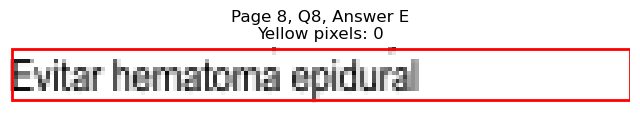


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=138.0, y1=733.2
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 339
Page 8, Q9, A: Yellow percentage: 0.0%


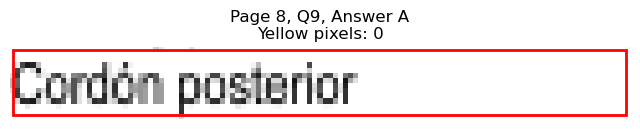

Page 8, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=130.0, y1=745.8
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 293
Page 8, Q9, B: Yellow percentage: 0.0%


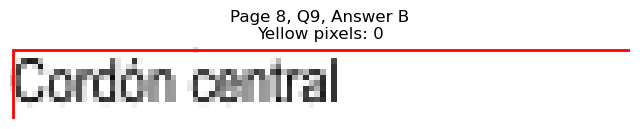

Page 8, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=153.5, y1=758.4
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 392
Page 8, Q9, C: Yellow percentage: 0.0%


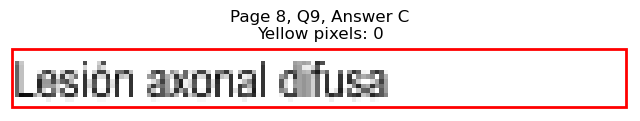

Page 8, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=408.9, y1=733.2
Page 8, Q9, D: Yellow pixels: 132
Page 8, Q9, D: Total non-white pixels: 554
Page 8, Q9, D: Yellow percentage: 23.8%


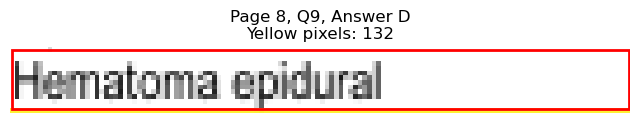

Page 8, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=388.7, y1=745.8
Page 8, Q9, E: Yellow pixels: 1242
Page 8, Q9, E: Total non-white pixels: 1456
Page 8, Q9, E: Yellow percentage: 85.3%


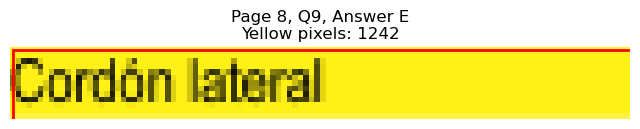


Page 8, Q9 - Selected Answer: E (based on yellow pixel count)





Page 9: Found 9 questions
Page 9, Q1 - A: Detected box: x0=133.0, y0=89.4, x1=211.3, y1=102.1
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 612
Page 9, Q1, A: Yellow percentage: 0.0%


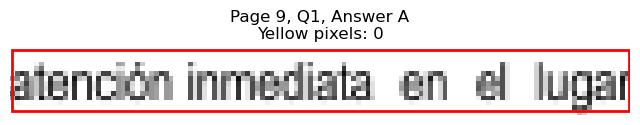

Page 9, Q1 - B: Detected box: x0=102.4, y0=114.6, x1=143.0, y1=127.3
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 379
Page 9, Q1, B: Yellow percentage: 0.0%


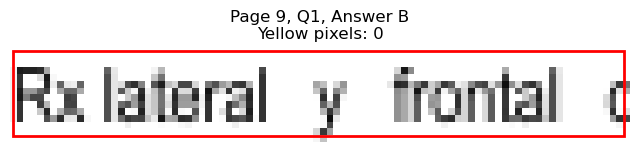

Page 9, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=106.4, y1=152.6
Page 9, Q1, C: Yellow pixels: 863
Page 9, Q1, C: Total non-white pixels: 1246
Page 9, Q1, C: Yellow percentage: 69.3%


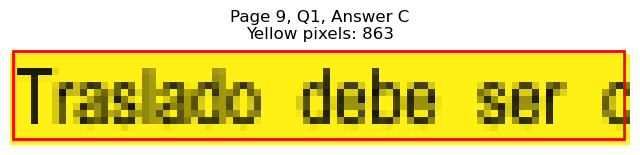

Page 9, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=519.2, y1=102.1
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 896
Page 9, Q1, D: Yellow percentage: 0.0%


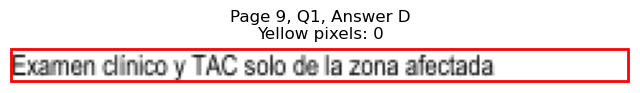

Page 9, Q1 - E: Detected box: x0=386.8, y0=102.0, x1=449.4, y1=114.7
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 547
Page 9, Q1, E: Yellow percentage: 0.0%


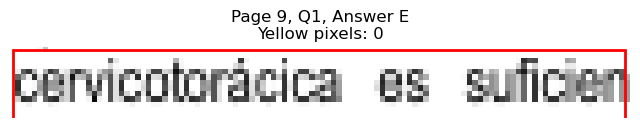


Page 9, Q1 - Selected Answer: C (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=228.3, x1=124.5, y1=240.9
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 275
Page 9, Q2, A: Yellow percentage: 0.0%


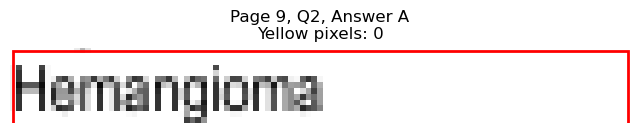

Page 9, Q2 - B: Detected box: x0=68.3, y0=240.9, x1=205.7, y1=253.5
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 656
Page 9, Q2, B: Yellow percentage: 0.0%


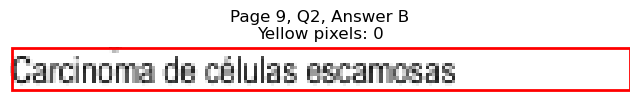

Page 9, Q2 - C: Detected box: x0=68.8, y0=253.5, x1=151.0, y1=266.1
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 423
Page 9, Q2, C: Yellow percentage: 0.0%


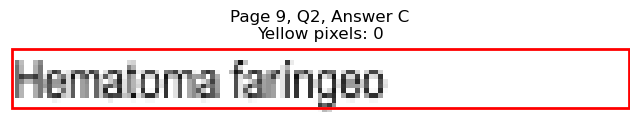

Page 9, Q2 - D: Detected box: x0=327.5, y0=228.3, x1=403.3, y1=240.9
Page 9, Q2, D: Yellow pixels: 1335
Page 9, Q2, D: Total non-white pixels: 1651
Page 9, Q2, D: Yellow percentage: 80.9%


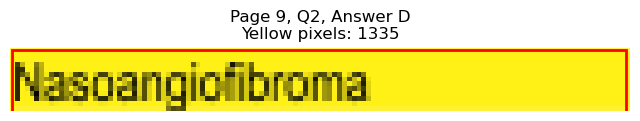

Page 9, Q2 - E: Detected box: x0=327.0, y0=240.9, x1=361.6, y1=253.5
Page 9, Q2, E: Yellow pixels: 81
Page 9, Q2, E: Total non-white pixels: 246
Page 9, Q2, E: Yellow percentage: 32.9%


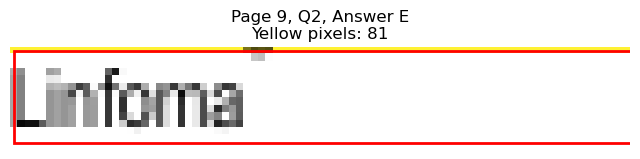


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=90.9, y1=304.1
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 96
Page 9, Q3, A: Yellow percentage: 0.0%


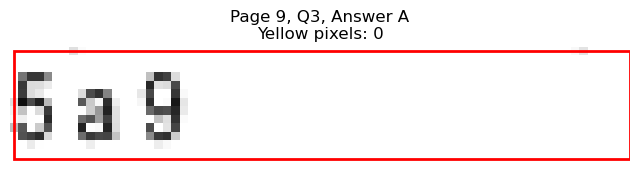

Page 9, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=100.9, y1=316.7
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 204
Page 9, Q3, B: Yellow percentage: 0.0%


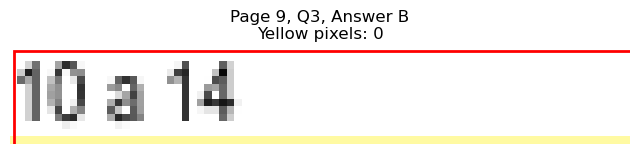

Page 9, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=101.4, y1=329.3
Page 9, Q3, C: Yellow pixels: 901
Page 9, Q3, C: Total non-white pixels: 1176
Page 9, Q3, C: Yellow percentage: 76.6%


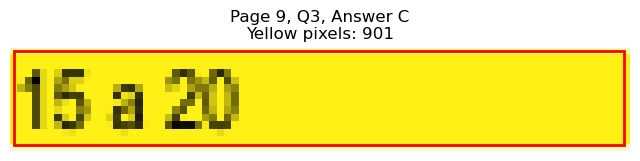

Page 9, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=360.2, y1=304.1
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 122
Page 9, Q3, D: Yellow percentage: 0.0%


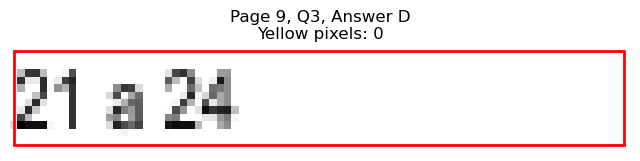

Page 9, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=359.7, y1=316.7
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 153
Page 9, Q3, E: Yellow percentage: 0.0%


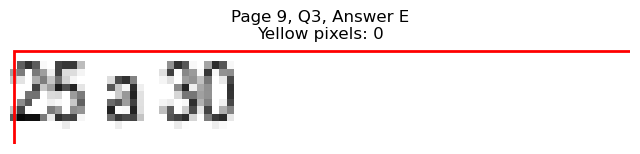


Page 9, Q3 - Selected Answer: C (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=178.7, y1=367.2
Page 9, Q4, A: Yellow pixels: 161
Page 9, Q4, A: Total non-white pixels: 729
Page 9, Q4, A: Yellow percentage: 22.1%


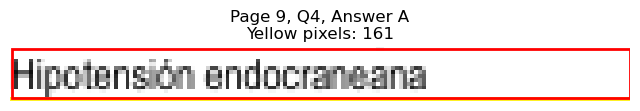

Page 9, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=181.7, y1=379.8
Page 9, Q4, B: Yellow pixels: 1681
Page 9, Q4, B: Total non-white pixels: 2132
Page 9, Q4, B: Yellow percentage: 78.8%


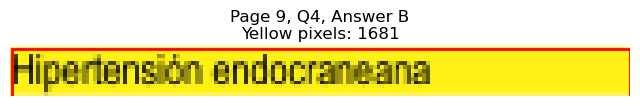

Page 9, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=152.1, y1=392.4
Page 9, Q4, C: Yellow pixels: 135
Page 9, Q4, C: Total non-white pixels: 557
Page 9, Q4, C: Yellow percentage: 24.2%


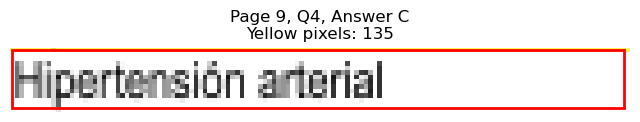

Page 9, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=407.9, y1=367.2
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 438
Page 9, Q4, D: Yellow percentage: 0.0%


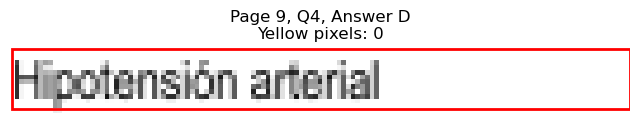

Page 9, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=375.2, y1=379.8
Page 9, Q4, E: Yellow pixels: 0
Page 9, Q4, E: Total non-white pixels: 270
Page 9, Q4, E: Yellow percentage: 0.0%


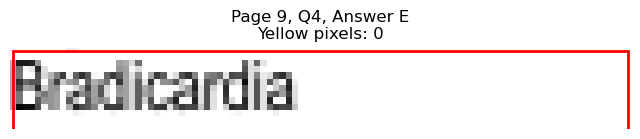


Page 9, Q4 - Selected Answer: B (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=253.8, y1=430.3
Page 9, Q5, A: Yellow pixels: 213
Page 9, Q5, A: Total non-white pixels: 1125
Page 9, Q5, A: Yellow percentage: 18.9%


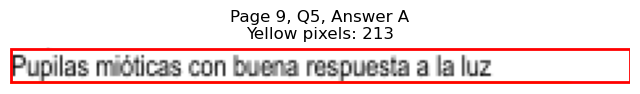

Page 9, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=265.8, y1=442.9
Page 9, Q5, B: Yellow pixels: 1985
Page 9, Q5, B: Total non-white pixels: 2782
Page 9, Q5, B: Yellow percentage: 71.4%


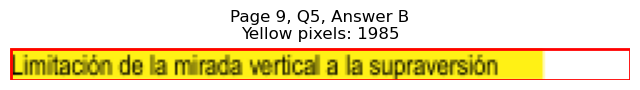

Page 9, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=262.8, y1=455.5
Page 9, Q5, C: Yellow pixels: 212
Page 9, Q5, C: Total non-white pixels: 1200
Page 9, Q5, C: Yellow percentage: 17.7%


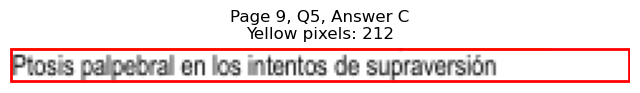

Page 9, Q5 - D: Detected box: x0=366.0, y0=417.6, x1=411.6, y1=430.3
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 388
Page 9, Q5, D: Yellow percentage: 0.0%


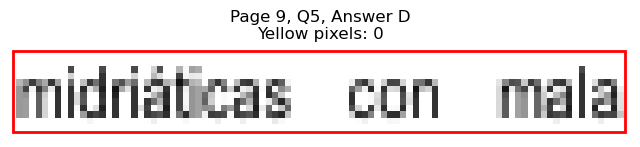

Page 9, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=533.7, y1=455.5
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 1046
Page 9, Q5, E: Yellow percentage: 0.0%


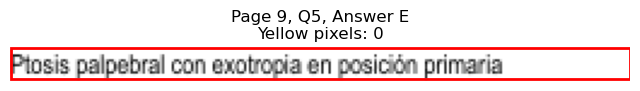


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=178.6, y1=493.4
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 557
Page 9, Q6, A: Yellow percentage: 0.0%


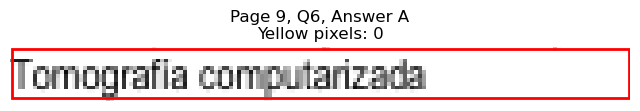

Page 9, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=140.7, y1=506.0
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 363
Page 9, Q6, B: Yellow percentage: 0.0%


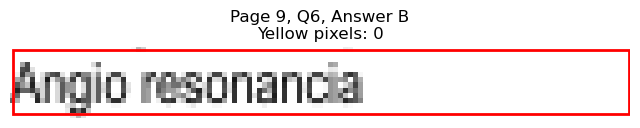

Page 9, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=155.1, y1=518.6
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 423
Page 9, Q6, C: Yellow percentage: 0.0%


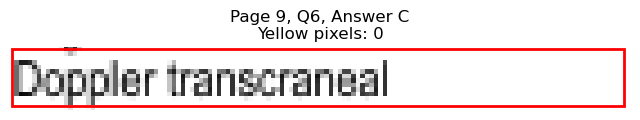

Page 9, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=392.7, y1=493.4
Page 9, Q6, D: Yellow pixels: 116
Page 9, Q6, D: Total non-white pixels: 424
Page 9, Q6, D: Yellow percentage: 27.4%


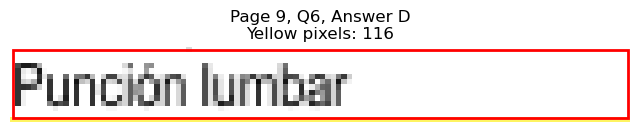

Page 9, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=410.8, y1=506.0
Page 9, Q6, E: Yellow pixels: 1364
Page 9, Q6, E: Total non-white pixels: 1748
Page 9, Q6, E: Yellow percentage: 78.0%


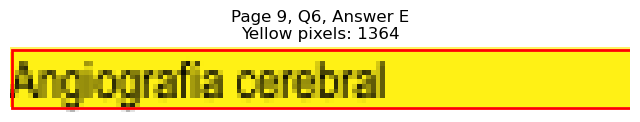


Page 9, Q6 - Selected Answer: E (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=183.6, y1=569.2
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 591
Page 9, Q7, A: Yellow percentage: 0.0%


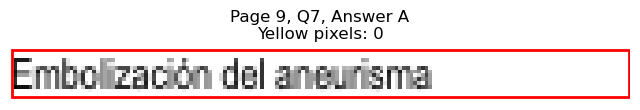

Page 9, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=199.6, y1=581.8
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 644
Page 9, Q7, B: Yellow percentage: 0.0%


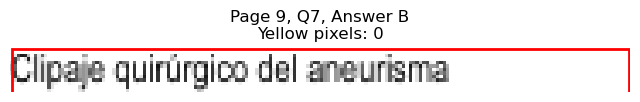

Page 9, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=187.6, y1=594.4
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 630
Page 9, Q7, C: Yellow percentage: 0.0%


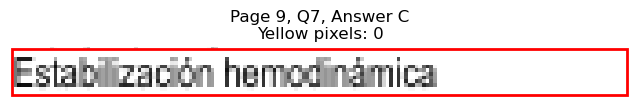

Page 9, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=419.8, y1=569.2
Page 9, Q7, D: Yellow pixels: 1474
Page 9, Q7, D: Total non-white pixels: 2002
Page 9, Q7, D: Yellow percentage: 73.6%


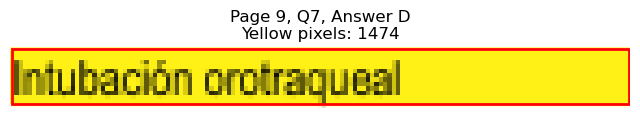

Page 9, Q7 - E: Detected box: x0=327.0, y0=493.4, x1=410.8, y1=506.0
Page 9, Q7, E: Yellow pixels: 1364
Page 9, Q7, E: Total non-white pixels: 1748
Page 9, Q7, E: Yellow percentage: 78.0%


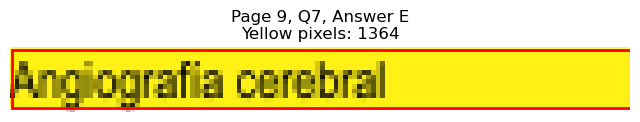


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=56.6, y0=644.9, x1=65.2, y1=657.5
Page 9, Q8, A: Yellow pixels: 60
Page 9, Q8, A: Total non-white pixels: 106
Page 9, Q8, A: Yellow percentage: 56.6%


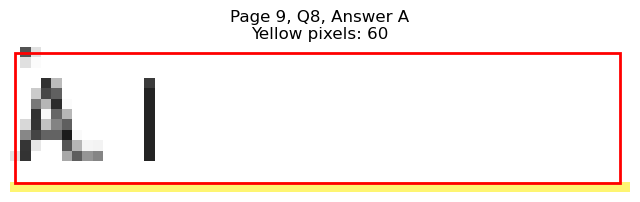

Page 9, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=78.4, y1=670.1
Page 9, Q8, B: Yellow pixels: 761
Page 9, Q8, B: Total non-white pixels: 854
Page 9, Q8, B: Yellow percentage: 89.1%


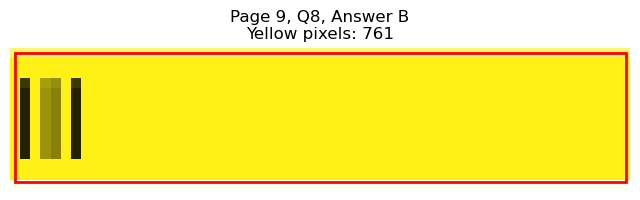

Page 9, Q8 - C: Detected box: x0=56.6, y0=670.1, x1=65.6, y1=682.7
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 121
Page 9, Q8, C: Yellow percentage: 0.0%


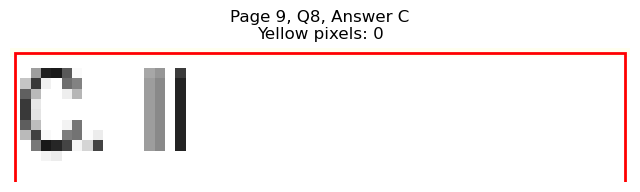

Page 9, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=338.6, y1=657.5
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 42
Page 9, Q8, D: Yellow percentage: 0.0%


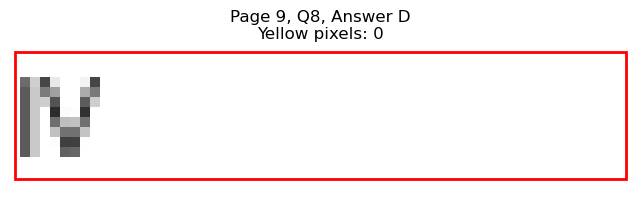

Page 9, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=335.6, y1=670.1
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 26
Page 9, Q8, E: Yellow percentage: 0.0%


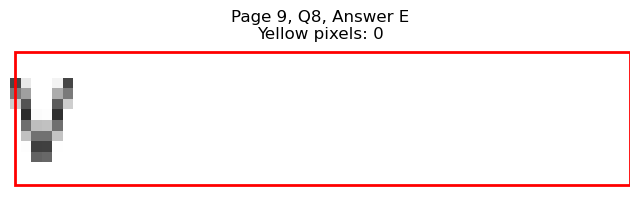


Page 9, Q8 - Selected Answer: B (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=157.1, y1=720.6
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 428
Page 9, Q9, A: Yellow percentage: 0.0%


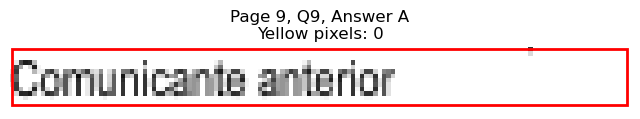

Page 9, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=161.5, y1=733.2
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 465
Page 9, Q9, B: Yellow percentage: 0.0%


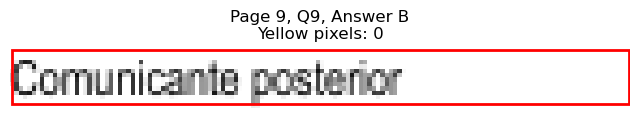

Page 9, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=126.0, y1=745.8
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 274
Page 9, Q9, C: Yellow percentage: 0.0%


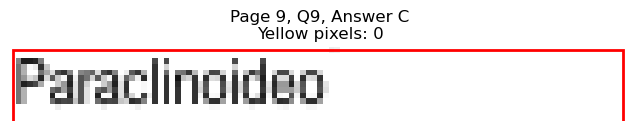

Page 9, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=374.7, y1=720.6
Page 9, Q9, D: Yellow pixels: 98
Page 9, Q9, D: Total non-white pixels: 341
Page 9, Q9, D: Yellow percentage: 28.7%


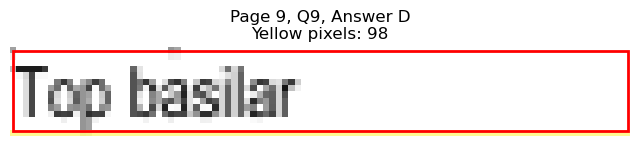

Page 9, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=388.8, y1=733.2
Page 9, Q9, E: Yellow pixels: 1227
Page 9, Q9, E: Total non-white pixels: 1568
Page 9, Q9, E: Yellow percentage: 78.3%


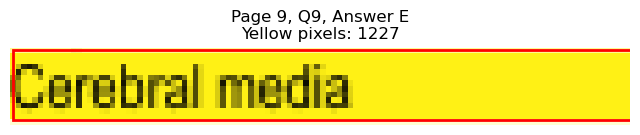


Page 9, Q9 - Selected Answer: E (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=186.1, y1=102.1
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 537
Page 10, Q1, A: Yellow percentage: 0.0%


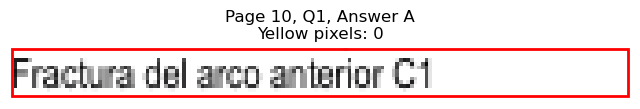

Page 10, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=187.7, y1=114.7
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 592
Page 10, Q1, B: Yellow percentage: 0.0%


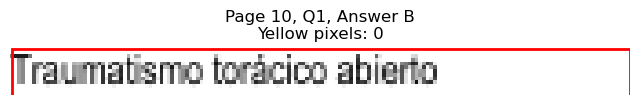

Page 10, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=180.7, y1=127.3
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 560
Page 10, Q1, C: Yellow percentage: 0.0%


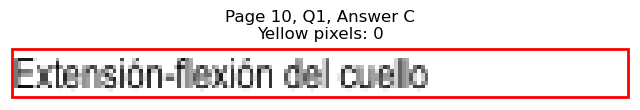

Page 10, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=460.0, y1=102.1
Page 10, Q1, D: Yellow pixels: 1838
Page 10, Q1, D: Total non-white pixels: 2576
Page 10, Q1, D: Yellow percentage: 71.4%


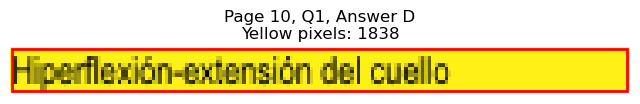

Page 10, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=442.4, y1=114.7
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 707
Page 10, Q1, E: Yellow percentage: 0.0%


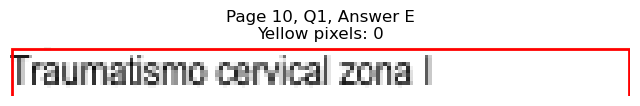


Page 10, Q1 - Selected Answer: D (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=127.5, y1=190.4
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 299
Page 10, Q2, A: Yellow percentage: 0.0%


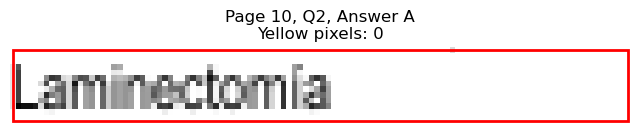

Page 10, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=207.8, y1=203.0
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 703
Page 10, Q2, B: Yellow percentage: 0.0%


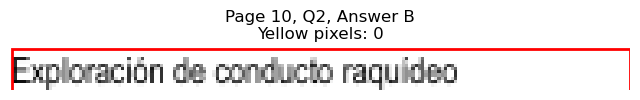

Page 10, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=165.5, y1=215.6
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 497
Page 10, Q2, C: Yellow percentage: 0.0%


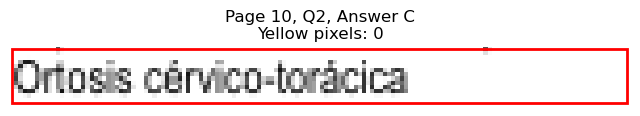

Page 10, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=397.7, y1=190.4
Page 10, Q2, D: Yellow pixels: 1192
Page 10, Q2, D: Total non-white pixels: 1694
Page 10, Q2, D: Yellow percentage: 70.4%


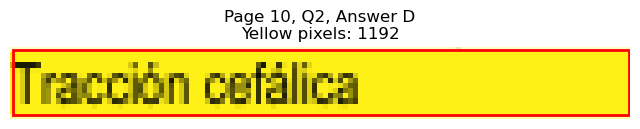

Page 10, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=473.0, y1=203.0
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 897
Page 10, Q2, E: Yellow percentage: 0.0%


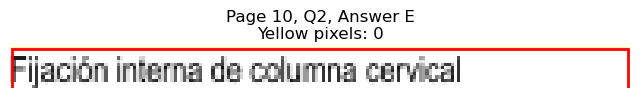


Page 10, Q2 - Selected Answer: D (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=184.1, y1=278.7
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 569
Page 10, Q3, A: Yellow percentage: 0.0%


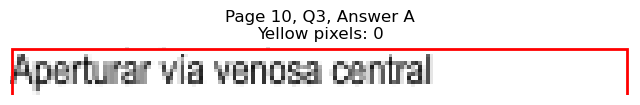

Page 10, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=161.2, y1=291.5
Page 10, Q3, B: Yellow pixels: 144
Page 10, Q3, B: Total non-white pixels: 584
Page 10, Q3, B: Yellow percentage: 24.7%


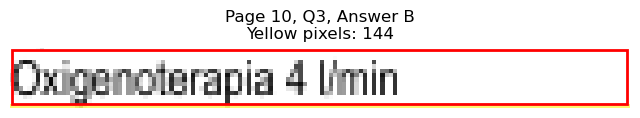

Page 10, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=168.3, y1=304.1
Page 10, Q3, C: Yellow pixels: 1571
Page 10, Q3, C: Total non-white pixels: 2114
Page 10, Q3, C: Yellow percentage: 74.3%


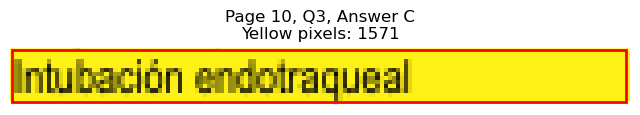

Page 10, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=423.3, y1=278.7
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 491
Page 10, Q3, D: Yellow percentage: 0.0%


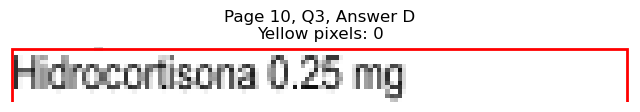

Page 10, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=441.4, y1=291.5
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 632
Page 10, Q3, E: Yellow percentage: 0.0%


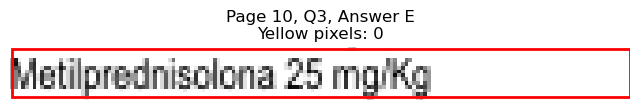


Page 10, Q3 - Selected Answer: C (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=103.5, y1=341.9
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 204
Page 10, Q4, A: Yellow percentage: 0.0%


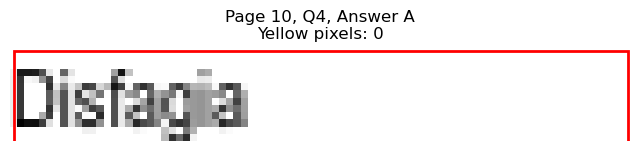

Page 10, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=168.6, y1=354.6
Page 10, Q4, B: Yellow pixels: 1552
Page 10, Q4, B: Total non-white pixels: 2114
Page 10, Q4, B: Yellow percentage: 73.4%


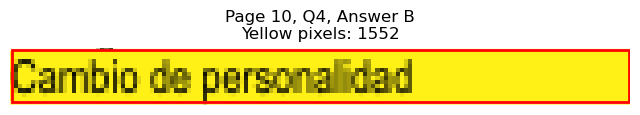

Page 10, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=103.9, y1=367.2
Page 10, Q4, C: Yellow pixels: 86
Page 10, Q4, C: Total non-white pixels: 271
Page 10, Q4, C: Yellow percentage: 31.7%


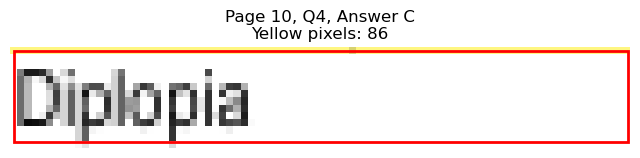

Page 10, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=361.1, y1=341.9
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 168
Page 10, Q4, D: Yellow percentage: 0.0%


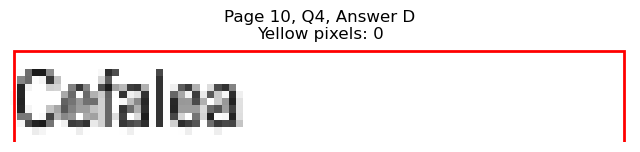

Page 10, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=374.7, y1=354.6
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 235
Page 10, Q4, E: Yellow percentage: 0.0%


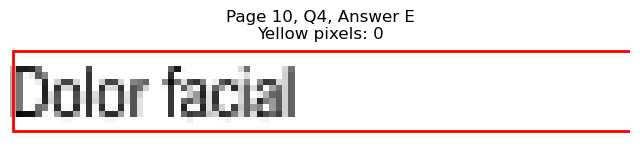


Page 10, Q4 - Selected Answer: B (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=172.1, y1=405.0
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 499
Page 10, Q5, A: Yellow percentage: 0.0%


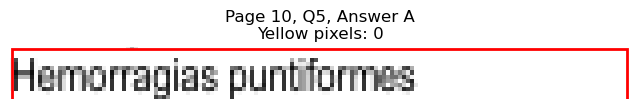

Page 10, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=176.7, y1=417.6
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 561
Page 10, Q5, B: Yellow percentage: 0.0%


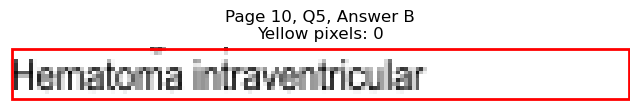

Page 10, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=151.6, y1=430.3
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 415
Page 10, Q5, C: Yellow percentage: 0.0%


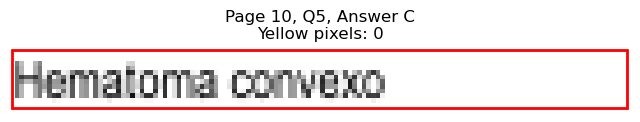

Page 10, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=395.8, y1=405.0
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 453
Page 10, Q5, D: Yellow percentage: 0.0%


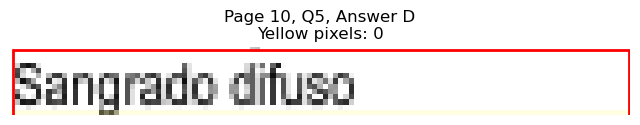

Page 10, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=409.9, y1=417.6
Page 10, Q5, E: Yellow pixels: 1422
Page 10, Q5, E: Total non-white pixels: 1862
Page 10, Q5, E: Yellow percentage: 76.4%


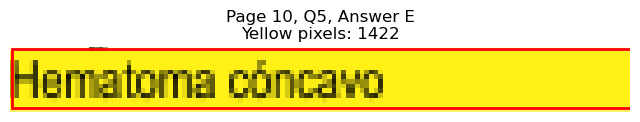


Page 10, Q5 - Selected Answer: E (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=153.0, y1=493.4
Page 10, Q6, A: Yellow pixels: 1269
Page 10, Q6, A: Total non-white pixels: 1904
Page 10, Q6, A: Yellow percentage: 66.6%


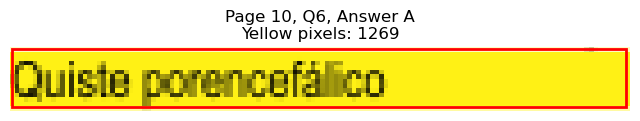

Page 10, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=133.5, y1=506.0
Page 10, Q6, B: Yellow pixels: 1
Page 10, Q6, B: Total non-white pixels: 467
Page 10, Q6, B: Yellow percentage: 0.2%


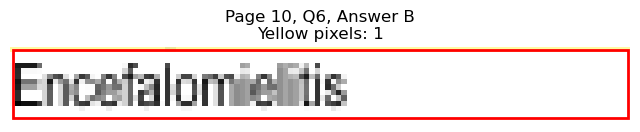

Page 10, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=138.5, y1=518.6
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 338
Page 10, Q6, C: Yellow percentage: 0.0%


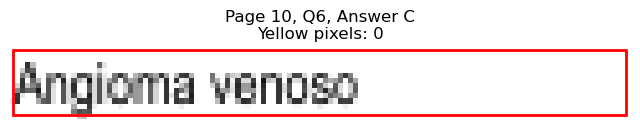

Page 10, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=412.3, y1=493.4
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 456
Page 10, Q6, D: Yellow percentage: 0.0%


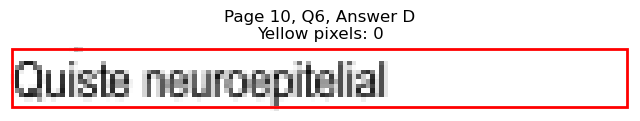

Page 10, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=372.7, y1=506.0
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 266
Page 10, Q6, E: Yellow percentage: 0.0%


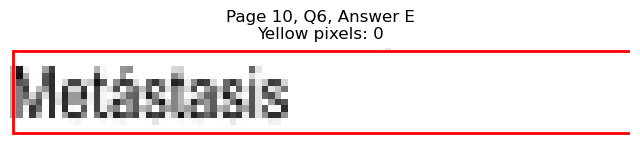


Page 10, Q6 - Selected Answer: A (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=221.9, y1=556.4
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 759
Page 10, Q7, A: Yellow percentage: 0.0%


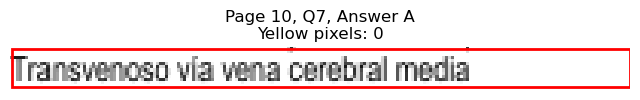

Page 10, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=274.5, y1=569.2
Page 10, Q7, B: Yellow pixels: 117
Page 10, Q7, B: Total non-white pixels: 1201
Page 10, Q7, B: Yellow percentage: 9.7%


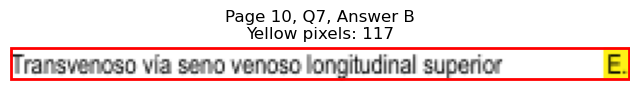

Page 10, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=217.2, y1=581.8
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 743
Page 10, Q7, C: Yellow percentage: 0.0%


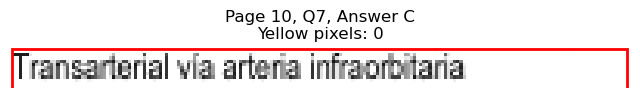

Page 10, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=500.1, y1=556.4
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 843
Page 10, Q7, D: Yellow percentage: 0.0%


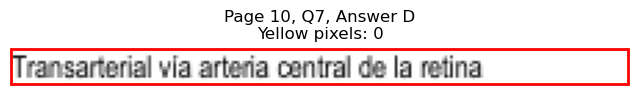

Page 10, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=492.1, y1=569.2
Page 10, Q7, E: Yellow pixels: 2180
Page 10, Q7, E: Total non-white pixels: 2995
Page 10, Q7, E: Yellow percentage: 72.8%


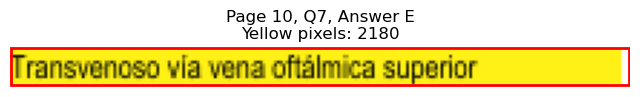


Page 10, Q7 - Selected Answer: E (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=253.8, y1=644.9
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 937
Page 10, Q8, A: Yellow percentage: 0.0%


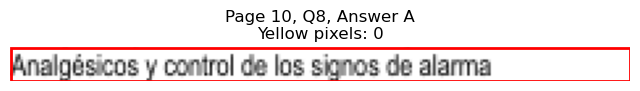

Page 10, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=247.4, y1=657.5
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 877
Page 10, Q8, B: Yellow percentage: 0.0%


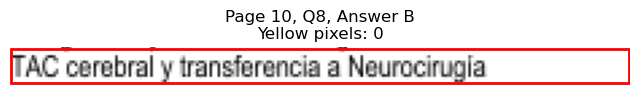

Page 10, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=160.6, y1=670.1
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 473
Page 10, Q8, C: Yellow percentage: 0.0%


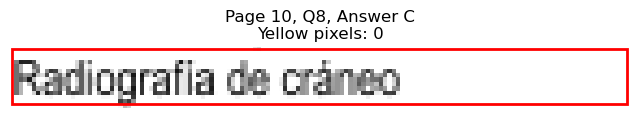

Page 10, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=447.9, y1=644.9
Page 10, Q8, D: Yellow pixels: 1793
Page 10, Q8, D: Total non-white pixels: 2223
Page 10, Q8, D: Yellow percentage: 80.7%


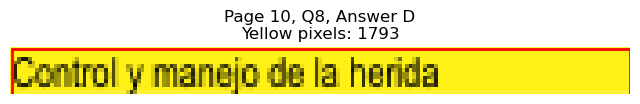

Page 10, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=455.9, y1=657.5
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 684
Page 10, Q8, E: Yellow percentage: 0.0%


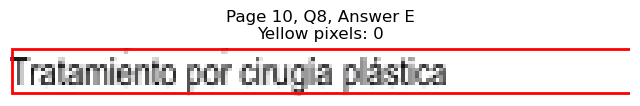


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=271.0, y1=708.0
Page 10, Q9, A: Yellow pixels: 0
Page 10, Q9, A: Total non-white pixels: 1022
Page 10, Q9, A: Yellow percentage: 0.0%


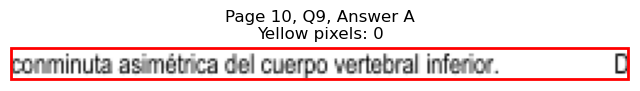

Page 10, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=170.1, y1=720.6
Page 10, Q9, B: Yellow pixels: 153
Page 10, Q9, B: Total non-white pixels: 617
Page 10, Q9, B: Yellow percentage: 24.8%


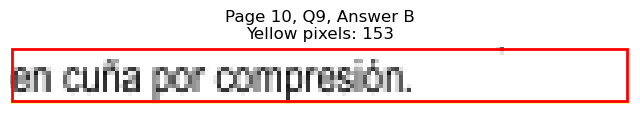

Page 10, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=213.8, y1=733.2
Page 10, Q9, C: Yellow pixels: 2006
Page 10, Q9, C: Total non-white pixels: 2744
Page 10, Q9, C: Yellow percentage: 73.1%


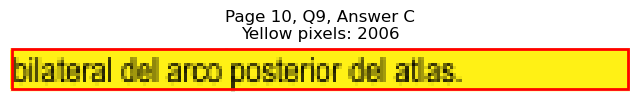

Page 10, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=389.2, y1=708.0
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 295
Page 10, Q9, D: Yellow percentage: 0.0%


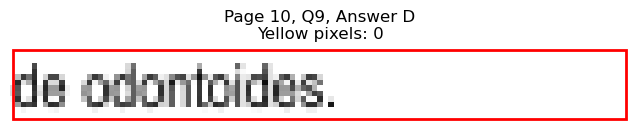

Page 10, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=409.4, y1=720.6
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 426
Page 10, Q9, E: Yellow percentage: 0.0%


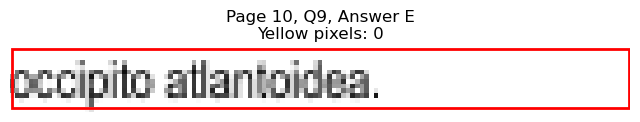


Page 10, Q9 - Selected Answer: C (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=263.9, y1=102.1
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 965
Page 11, Q1, A: Yellow percentage: 0.0%


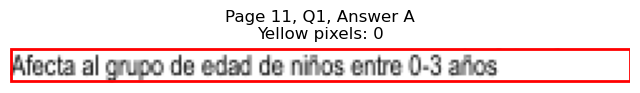

Page 11, Q1 - B: Detected box: x0=86.8, y0=102.0, x1=136.6, y1=114.7
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 408
Page 11, Q1, B: Yellow percentage: 0.0%


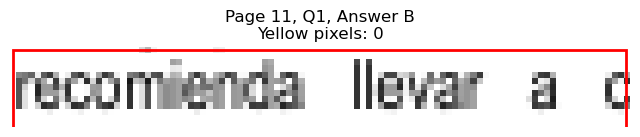

Page 11, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=174.1, y1=139.9
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 525
Page 11, Q1, C: Yellow percentage: 0.0%


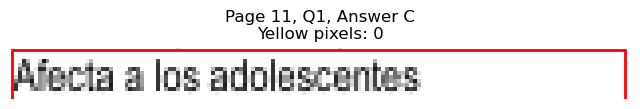

Page 11, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=541.1, y1=102.1
Page 11, Q1, D: Yellow pixels: 2176
Page 11, Q1, D: Total non-white pixels: 2996
Page 11, Q1, D: Yellow percentage: 72.6%


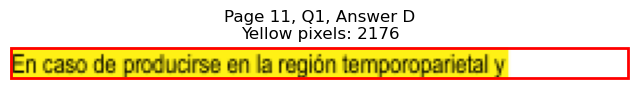

Page 11, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=541.2, y1=139.9
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 1238
Page 11, Q1, E: Yellow percentage: 0.0%


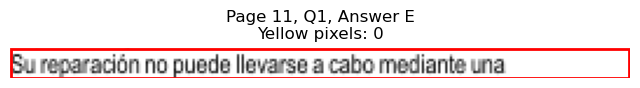


Page 11, Q1 - Selected Answer: D (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=118.5, y1=215.6
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 502
Page 11, Q2, A: Yellow percentage: 0.0%


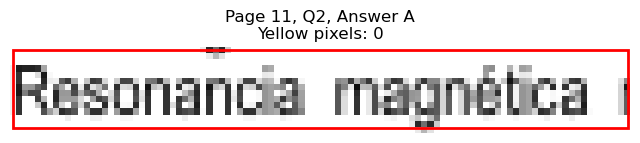

Page 11, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=270.9, y1=240.9
Page 11, Q2, B: Yellow pixels: 2002
Page 11, Q2, B: Total non-white pixels: 2782
Page 11, Q2, B: Yellow percentage: 72.0%


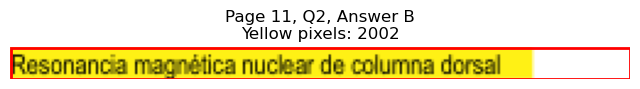

Page 11, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=218.8, y1=253.5
Page 11, Q2, C: Yellow pixels: 197
Page 11, Q2, C: Total non-white pixels: 944
Page 11, Q2, C: Yellow percentage: 20.9%


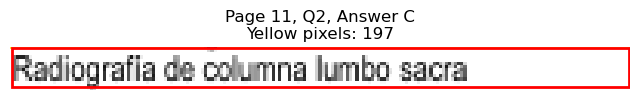

Page 11, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=411.8, y1=215.6
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 437
Page 11, Q2, D: Yellow percentage: 0.0%


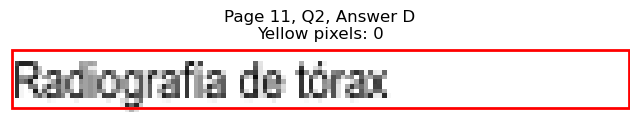

Page 11, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=445.4, y1=228.3
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 615
Page 11, Q2, E: Yellow percentage: 0.0%


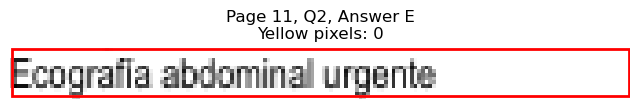


Page 11, Q2 - Selected Answer: B (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=156.1, y1=291.5
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 404
Page 11, Q3, A: Yellow percentage: 0.0%


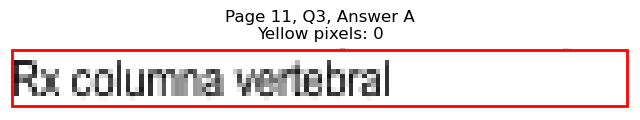

Page 11, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=145.7, y1=304.1
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 343
Page 11, Q3, B: Yellow percentage: 0.0%


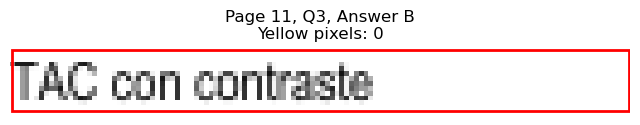

Page 11, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=116.1, y1=316.7
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 260
Page 11, Q3, C: Yellow percentage: 0.0%


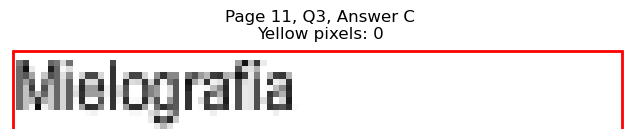

Page 11, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=422.0, y1=291.5
Page 11, Q3, D: Yellow pixels: 1522
Page 11, Q3, D: Total non-white pixels: 2030
Page 11, Q3, D: Yellow percentage: 75.0%


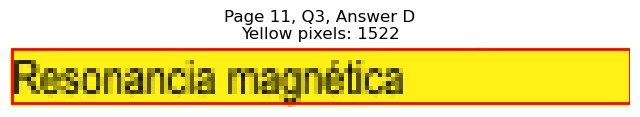

Page 11, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=402.4, y1=304.1
Page 11, Q3, E: Yellow pixels: 125
Page 11, Q3, E: Total non-white pixels: 526
Page 11, Q3, E: Yellow percentage: 23.8%


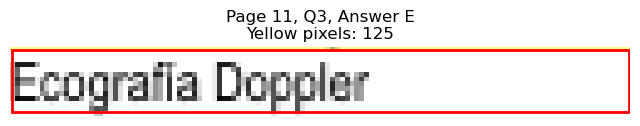


Page 11, Q3 - Selected Answer: D (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=155.1, y1=379.8
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 417
Page 11, Q4, A: Yellow percentage: 0.0%


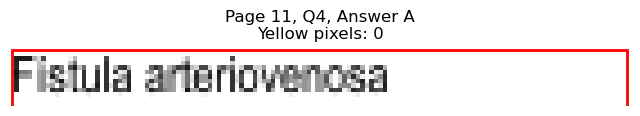

Page 11, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=197.8, y1=392.4
Page 11, Q4, B: Yellow pixels: 180
Page 11, Q4, B: Total non-white pixels: 827
Page 11, Q4, B: Yellow percentage: 21.8%


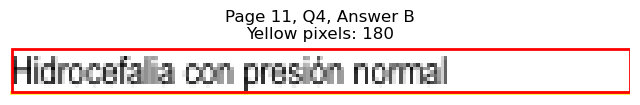

Page 11, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=155.5, y1=405.0
Page 11, Q4, C: Yellow pixels: 1443
Page 11, Q4, C: Total non-white pixels: 1794
Page 11, Q4, C: Yellow percentage: 80.4%


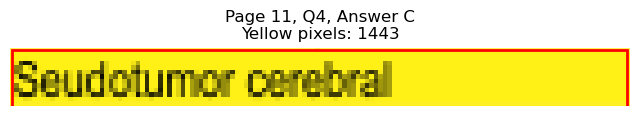

Page 11, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=405.3, y1=379.8
Page 11, Q4, D: Yellow pixels: 0
Page 11, Q4, D: Total non-white pixels: 406
Page 11, Q4, D: Yellow percentage: 0.0%


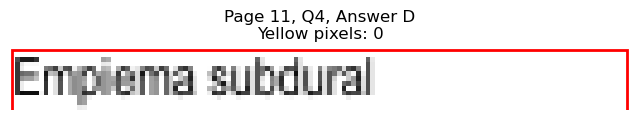

Page 11, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=418.4, y1=392.4
Page 11, Q4, E: Yellow pixels: 0
Page 11, Q4, E: Total non-white pixels: 437
Page 11, Q4, E: Yellow percentage: 0.0%


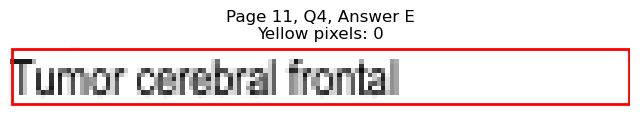


Page 11, Q4 - Selected Answer: C (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=98.4, y1=442.9
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 156
Page 11, Q5, A: Yellow percentage: 0.0%


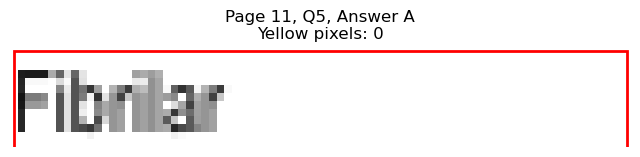

Page 11, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=115.0, y1=455.5
Page 11, Q5, B: Yellow pixels: 97
Page 11, Q5, B: Total non-white pixels: 341
Page 11, Q5, B: Yellow percentage: 28.4%


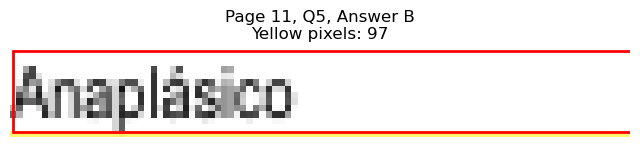

Page 11, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=107.4, y1=468.1
Page 11, Q5, C: Yellow pixels: 1016
Page 11, Q5, C: Total non-white pixels: 1260
Page 11, Q5, C: Yellow percentage: 80.6%


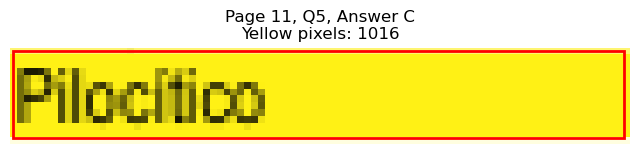

Page 11, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=393.3, y1=442.9
Page 11, Q5, D: Yellow pixels: 0
Page 11, Q5, D: Total non-white pixels: 330
Page 11, Q5, D: Yellow percentage: 0.0%


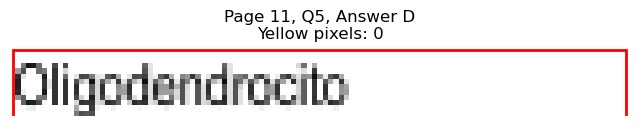

Page 11, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=426.9, y1=455.5
Page 11, Q5, E: Yellow pixels: 0
Page 11, Q5, E: Total non-white pixels: 543
Page 11, Q5, E: Yellow percentage: 0.0%


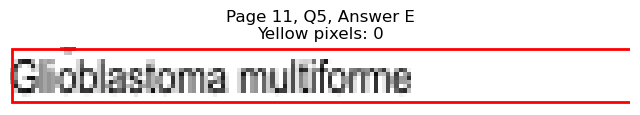


Page 11, Q5 - Selected Answer: C (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=249.4, y1=506.0
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 919
Page 11, Q6, A: Yellow percentage: 0.0%


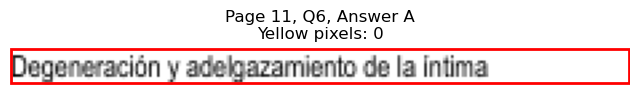

Page 11, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=261.4, y1=518.6
Page 11, Q6, B: Yellow pixels: 0
Page 11, Q6, B: Total non-white pixels: 981
Page 11, Q6, B: Yellow percentage: 0.0%


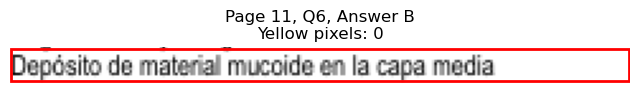

Page 11, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=220.2, y1=531.2
Page 11, Q6, C: Yellow pixels: 0
Page 11, Q6, C: Total non-white pixels: 732
Page 11, Q6, C: Yellow percentage: 0.0%


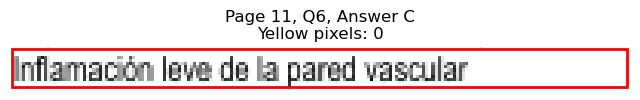

Page 11, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=461.9, y1=506.0
Page 11, Q6, D: Yellow pixels: 1884
Page 11, Q6, D: Total non-white pixels: 2408
Page 11, Q6, D: Yellow percentage: 78.2%


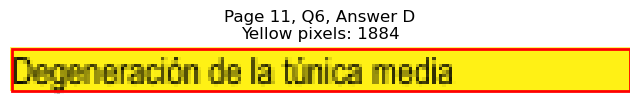

Page 11, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=426.9, y1=518.6
Page 11, Q6, E: Yellow pixels: 146
Page 11, Q6, E: Total non-white pixels: 681
Page 11, Q6, E: Yellow percentage: 21.4%


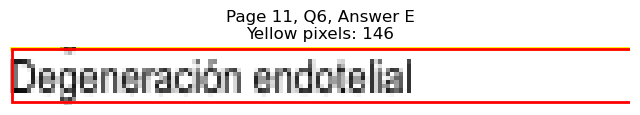


Page 11, Q6 - Selected Answer: D (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=189.6, y1=569.2
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 579
Page 11, Q7, A: Yellow percentage: 0.0%


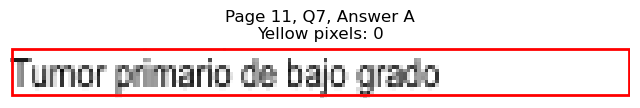

Page 11, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=113.9, y1=581.8
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 272
Page 11, Q7, B: Yellow percentage: 0.0%


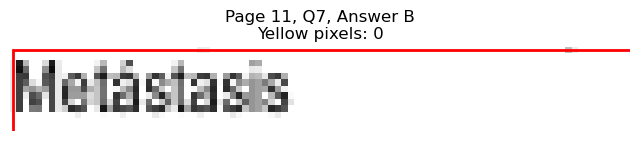

Page 11, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=96.9, y1=594.4
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 143
Page 11, Q7, C: Yellow percentage: 0.0%


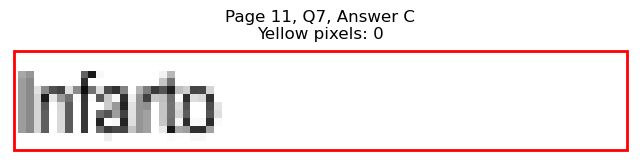

Page 11, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=512.1, y1=569.2
Page 11, Q7, D: Yellow pixels: 2055
Page 11, Q7, D: Total non-white pixels: 2995
Page 11, Q7, D: Yellow percentage: 68.6%


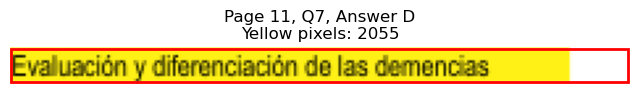

Page 11, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=385.3, y1=581.8
Page 11, Q7, E: Yellow pixels: 0
Page 11, Q7, E: Total non-white pixels: 400
Page 11, Q7, E: Yellow percentage: 0.0%


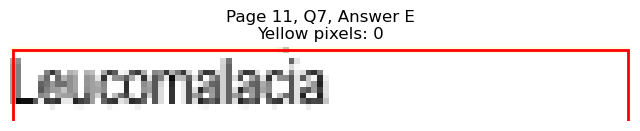


Page 11, Q7 - Selected Answer: D (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=197.8, y1=632.3
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 667
Page 11, Q8, A: Yellow percentage: 0.0%


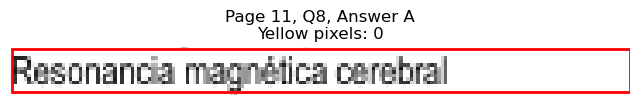

Page 11, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=108.9, y1=644.9
Page 11, Q8, B: Yellow pixels: 0
Page 11, Q8, B: Total non-white pixels: 286
Page 11, Q8, B: Yellow percentage: 0.0%


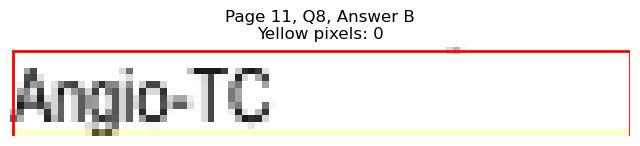

Page 11, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=133.9, y1=657.5
Page 11, Q8, C: Yellow pixels: 1272
Page 11, Q8, C: Total non-white pixels: 1624
Page 11, Q8, C: Yellow percentage: 78.3%


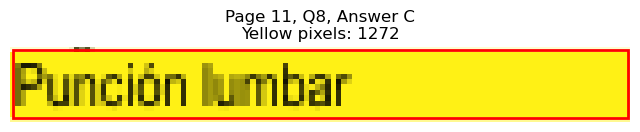

Page 11, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=452.9, y1=632.3
Page 11, Q8, D: Yellow pixels: 0
Page 11, Q8, D: Total non-white pixels: 649
Page 11, Q8, D: Yellow percentage: 0.0%


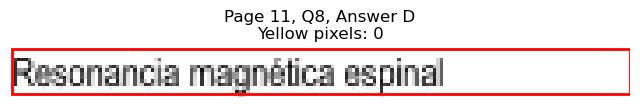

Page 11, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=410.8, y1=644.9
Page 11, Q8, E: Yellow pixels: 0
Page 11, Q8, E: Total non-white pixels: 450
Page 11, Q8, E: Yellow percentage: 0.0%


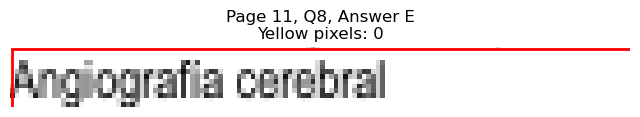


Page 11, Q8 - Selected Answer: C (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=351.7, y1=695.3
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 1402
Page 11, Q9, A: Yellow percentage: 0.0%


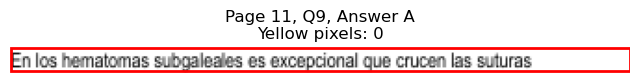

Page 11, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=507.7, y1=708.0
Page 11, Q9, B: Yellow pixels: 0
Page 11, Q9, B: Total non-white pixels: 2156
Page 11, Q9, B: Yellow percentage: 0.0%


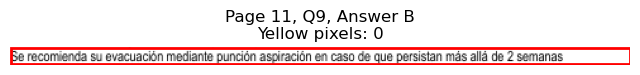

Page 11, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=363.2, y1=720.6
Page 11, Q9, C: Yellow pixels: 0
Page 11, Q9, C: Total non-white pixels: 1455
Page 11, Q9, C: Yellow percentage: 0.0%


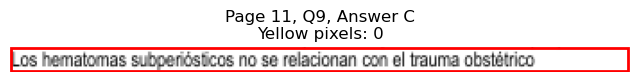

Page 11, Q9 - D: Detected box: x0=68.8, y0=720.6, x1=442.5, y1=733.2
Page 11, Q9, D: Yellow pixels: 425
Page 11, Q9, D: Total non-white pixels: 2264
Page 11, Q9, D: Yellow percentage: 18.8%


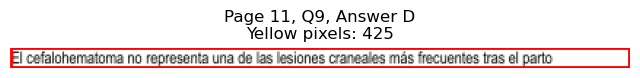

Page 11, Q9 - E: Detected box: x0=68.3, y0=733.2, x1=347.6, y1=745.8
Page 11, Q9, E: Yellow pixels: 3255
Page 11, Q9, E: Total non-white pixels: 4290
Page 11, Q9, E: Yellow percentage: 75.9%


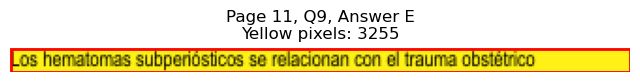


Page 11, Q9 - Selected Answer: E (based on yellow pixel count)





Page 12: Found 2 questions
Page 12, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=153.5, y1=114.7
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 437
Page 12, Q1, A: Yellow percentage: 0.0%


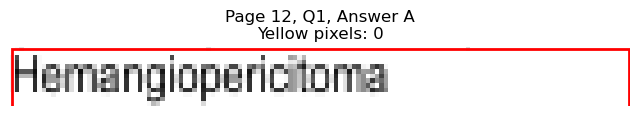

Page 12, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=175.6, y1=127.3
Page 12, Q1, B: Yellow pixels: 0
Page 12, Q1, B: Total non-white pixels: 616
Page 12, Q1, B: Yellow percentage: 0.0%


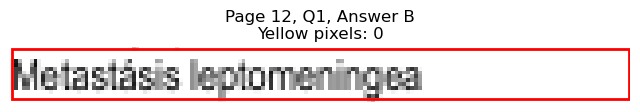

Page 12, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=132.0, y1=139.9
Page 12, Q1, C: Yellow pixels: 0
Page 12, Q1, C: Total non-white pixels: 347
Page 12, Q1, C: Yellow percentage: 0.0%


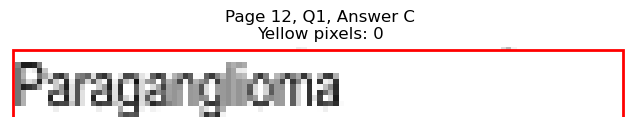

Page 12, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=403.3, y1=114.7
Page 12, Q1, D: Yellow pixels: 1380
Page 12, Q1, D: Total non-white pixels: 1651
Page 12, Q1, D: Yellow percentage: 83.6%


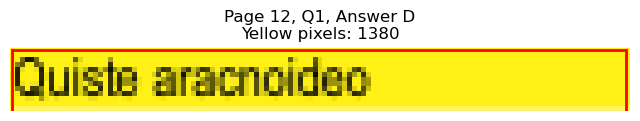

Page 12, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=368.2, y1=127.3
Page 12, Q1, E: Yellow pixels: 92
Page 12, Q1, E: Total non-white pixels: 294
Page 12, Q1, E: Yellow percentage: 31.3%


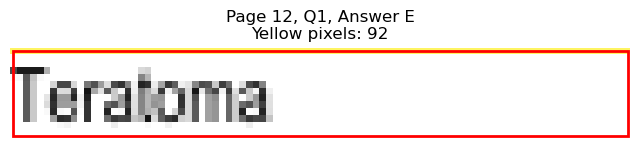


Page 12, Q1 - Selected Answer: D (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=123.5, y1=203.0
Page 12, Q2, A: Yellow pixels: 0
Page 12, Q2, A: Total non-white pixels: 257
Page 12, Q2, A: Yellow percentage: 0.0%


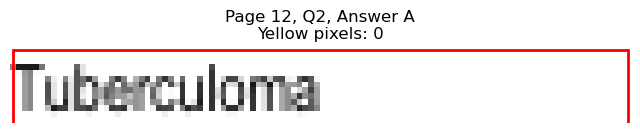

Page 12, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=141.0, y1=215.6
Page 12, Q2, B: Yellow pixels: 0
Page 12, Q2, B: Total non-white pixels: 376
Page 12, Q2, B: Yellow percentage: 0.0%


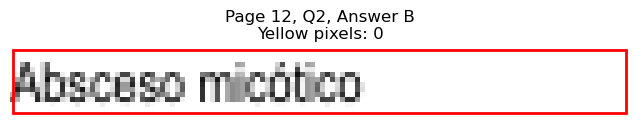

Page 12, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=103.3, y1=228.3
Page 12, Q2, C: Yellow pixels: 0
Page 12, Q2, C: Total non-white pixels: 169
Page 12, Q2, C: Yellow percentage: 0.0%


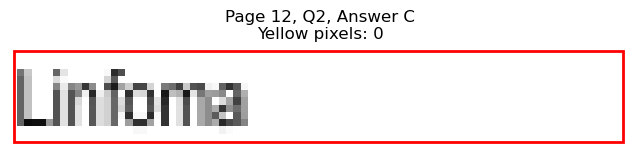

Page 12, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=399.3, y1=203.0
Page 12, Q2, D: Yellow pixels: 0
Page 12, Q2, D: Total non-white pixels: 481
Page 12, Q2, D: Yellow percentage: 0.0%


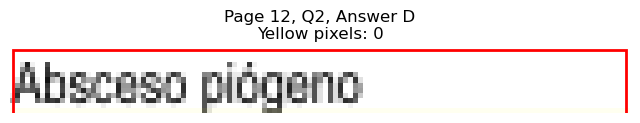

Page 12, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=369.7, y1=215.6
Page 12, Q2, E: Yellow pixels: 1032
Page 12, Q2, E: Total non-white pixels: 1302
Page 12, Q2, E: Yellow percentage: 79.3%


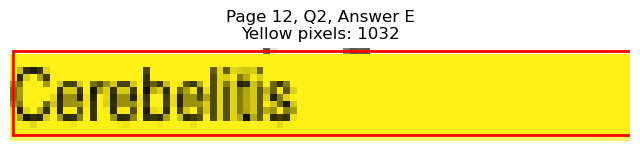


Page 12, Q2 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Cuál de los siguientes NO es un factor de rie...
1,¿De dónde son los aneurismas que más frecuente...
2,¿Cuál de las siguientes afirmaciones NO es cor...
3,En la escala del coma de Glasgow. La respuesta...
4,¿Cuál de las siguientes opciones sería la meno...
...,...
95,¿Cuál es la principal indicación clínica del P...
96,¿Cuál de las siguientes pruebas NO está indica...
97,¿Qué es correcto en relación con los cefalohem...
98,RMN columna lumbar: lesión bien delimitada ext...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Edad avanzada,Puntuación baja en la escala de Glasgow,Aneurisma de cerebral media,Hemorragia intraventricular,Convulsiones
1,Comunicante posterior,Cerebral media,PICA,Paraclinoideo,Comunicante anterior
2,La HSA espontánea asocia una elevada mortalidad,La HSA más frecuente es la secundaria a la rot...,La HSA se localiza en el compartimento,La HSA espontánea afecta a una población más,Es la hipertensión arterial un factor de riesgo
3,1,3,4,5,2
4,Cavernoma pontino,Rotura de arteria perforante,Sangrado venoso,Hematoma de la pared de la arteria basilar,Trastorno de coagulación
...,...,...,...,...,...
95,Tumor primario de bajo grado,Metástasis,Infarto,Evaluación y diferenciación de las demencias,Leucomalacia
96,Resonancia magnética cerebral,Angio-TC,Punción lumbar,Resonancia magnética espinal,Angiografía cerebral
97,En los hematomas subgaleales es excepcional qu...,Se recomienda su evacuación mediante punción a...,Los hematomas subperiósticos no se relacionan ...,El cefalohematoma no representa una de las les...,Los hematomas subperiósticos se relacionan con...
98,Hemangiopericitoma,Metastásis leptomeningea,Paraganglioma,Quiste aracnoideo,Teratoma


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,¿Cuál de los siguientes NO es un factor de rie...,Edad avanzada,Puntuación baja en la escala de Glasgow,Aneurisma de cerebral media,Hemorragia intraventricular,Convulsiones,C
1,¿De dónde son los aneurismas que más frecuente...,Comunicante posterior,Cerebral media,PICA,Paraclinoideo,Comunicante anterior,E
2,¿Cuál de las siguientes afirmaciones NO es cor...,La HSA espontánea asocia una elevada mortalidad,La HSA más frecuente es la secundaria a la rot...,La HSA se localiza en el compartimento,La HSA espontánea afecta a una población más,Es la hipertensión arterial un factor de riesgo,B
3,En la escala del coma de Glasgow. La respuesta...,1,3,4,5,2,E
4,¿Cuál de las siguientes opciones sería la meno...,Cavernoma pontino,Rotura de arteria perforante,Sangrado venoso,Hematoma de la pared de la arteria basilar,Trastorno de coagulación,A
...,...,...,...,...,...,...,...
95,¿Cuál es la principal indicación clínica del P...,Tumor primario de bajo grado,Metástasis,Infarto,Evaluación y diferenciación de las demencias,Leucomalacia,D
96,¿Cuál de las siguientes pruebas NO está indica...,Resonancia magnética cerebral,Angio-TC,Punción lumbar,Resonancia magnética espinal,Angiografía cerebral,C
97,¿Qué es correcto en relación con los cefalohem...,En los hematomas subgaleales es excepcional qu...,Se recomienda su evacuación mediante punción a...,Los hematomas subperiósticos no se relacionan ...,El cefalohematoma no representa una de las les...,Los hematomas subperiósticos se relacionan con...,E
98,RMN columna lumbar: lesión bien delimitada ext...,Hemangiopericitoma,Metastásis leptomeningea,Paraganglioma,Quiste aracnoideo,Teratoma,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Neurocirugía.csv
